In [29]:
print("hello wrold!")

hello wrold!


Project root: C:\Users\singh\Desktop\foresight
Original dataset shape: (2452, 9)

Household consumption transactions: 1996

WEEKLY DATASET
Total calendar weeks: 206
Weeks with transactions: 193
Zero-spending weeks: 13
Date range: 2014-12-29/2015-01-04 to 2018-12-03/2018-12-09

WEEKLY SPENDING STATISTICS


count      206.00
mean      4548.51
std       7986.50
min          0.00
25%        569.62
50%       2223.50
75%       4870.00
90%       9008.59
95%      18100.25
max      55597.00
Name: Total_Spending, dtype: float64


Mean weekly spending: 4548.51
Standard deviation: 7986.5
Coefficient of variation: 1.7558

Potential high-spending weeks:


,Total_Spending
Week,
2017-08-07/2017-08-13,55597.00
2018-01-15/2018-01-21,52244.00
2018-01-22/2018-01-28,46613.90
2017-12-18/2017-12-24,32431.00
2017-07-24/2017-07-30,30001.00
2017-11-27/2017-12-03,29370.00
2017-02-27/2017-03-05,28453.47
2018-06-25/2018-07-01,26429.67
2018-05-14/2018-05-20,23914.00


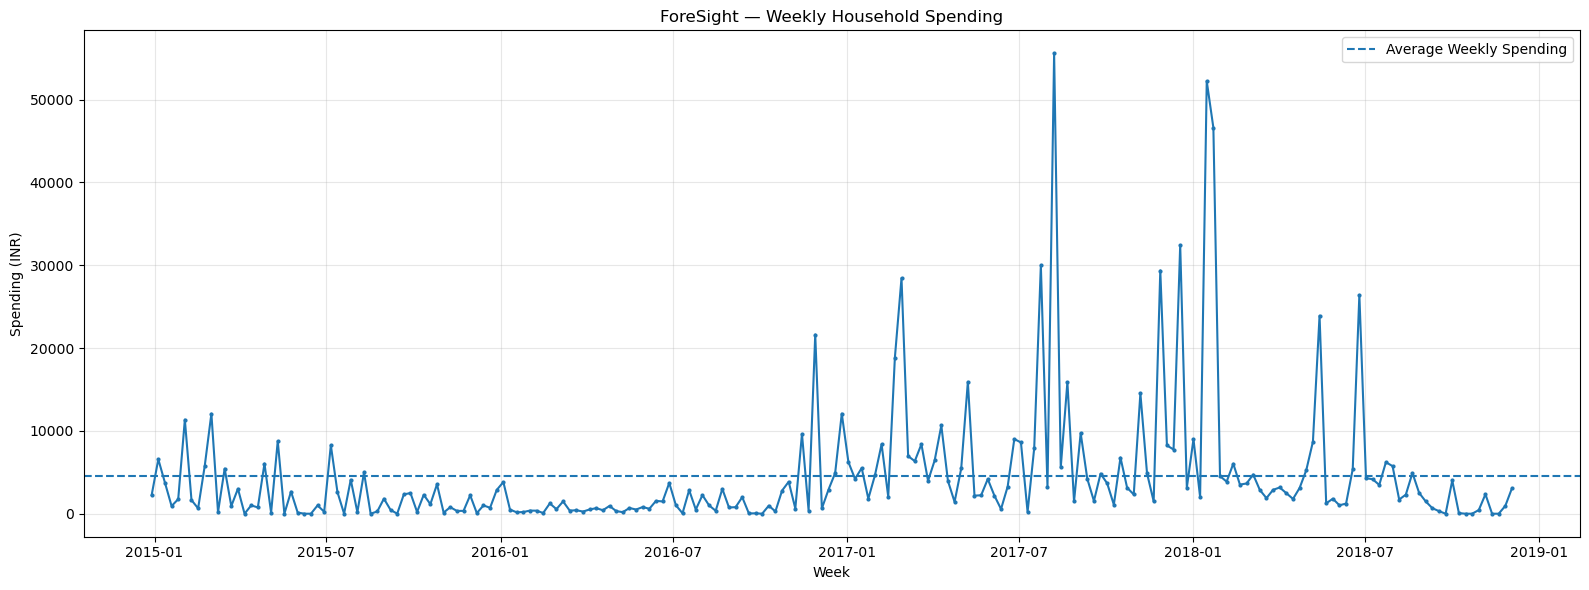

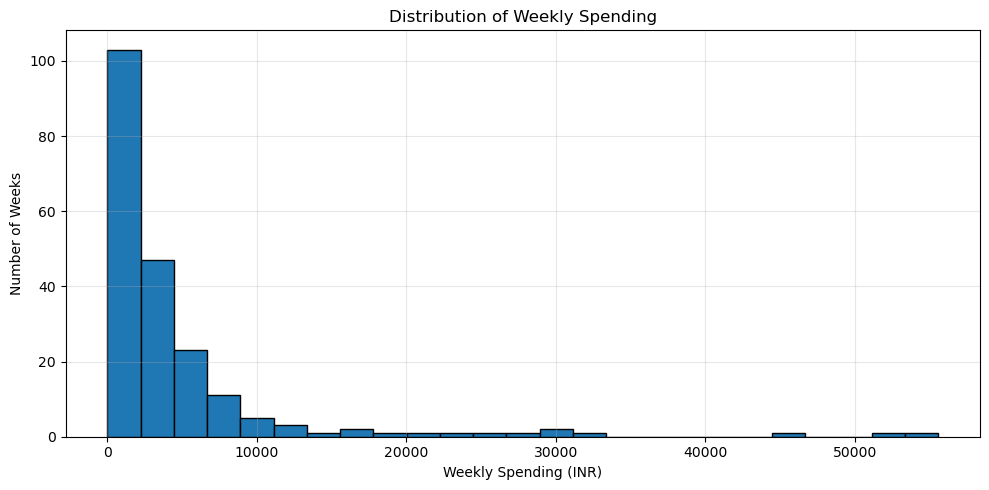


DATA QUALITY CHECKS
Missing weekly values: 0
Negative spending weeks: 0
Duplicate weekly periods: 0
Weekly spending total: 936993.63

STEP 1 COMPLETED


In [30]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 1: WEEKLY DATA PREPARATION
# ============================================================

import os
os.environ["OMP_NUM_THREADS"] = "1"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. FIND PROJECT ROOT AND LOAD DATA
# ------------------------------------------------------------

current_path = Path.cwd().resolve()

project_root = None

for folder in [current_path, *current_path.parents]:
    if (
        (folder / "data").exists()
        and (folder / "models").exists()
        and (folder / "notebooks").exists()
    ):
        project_root = folder
        break

if project_root is None:
    raise FileNotFoundError(
        "Could not find ForeSight project root."
    )

DATA_PATH = (
    project_root /
    "data" /
    "processed" /
    "cleaned_household_transactions.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH)

df["Date"] = pd.to_datetime(
    df["Date"], errors="coerce"
)

df["Amount"] = pd.to_numeric(
    df["Amount"], errors="coerce"
)

print("Project root:", project_root)
print("Original dataset shape:", df.shape)

# ------------------------------------------------------------
# 2. SELECT HOUSEHOLD CONSUMPTION EXPENSES
# SAME FILTERING AS NOTEBOOK 04 AND 05
# ------------------------------------------------------------

expense_df = df[
    df["Income/Expense"] == "Expense"
].copy()

financial_categories_strict = [
    "Money transfer",
    "Investment",
    "Public Provident Fund",
    "Recurring Deposit"
]

excluded_notes = [
    "Public Provident Fund",
    "Permanent Residence money transfer"
]

household_df = expense_df[
    (~expense_df["Category"].isin(
        financial_categories_strict
    )) &
    (~expense_df["Note"].isin(
        excluded_notes
    ))
].copy()

household_df = household_df.dropna(
    subset=["Date", "Amount", "Category"]
)

print(
    "\nHousehold consumption transactions:",
    len(household_df)
)

# ------------------------------------------------------------
# 3. CREATE WEEKLY PERIODS
# MONDAY TO SUNDAY
# ------------------------------------------------------------

household_df["Week"] = (
    household_df["Date"].dt.to_period("W-SUN")
)

all_weeks = pd.period_range(
    start=household_df["Week"].min(),
    end=household_df["Week"].max(),
    freq="W-SUN"
)

# ------------------------------------------------------------
# 4. AGGREGATE WEEKLY SPENDING
# ------------------------------------------------------------

weekly_summary = (
    household_df.groupby("Week").agg(
        Total_Spending=("Amount", "sum"),
        Transaction_Count=("Amount", "count"),
        Average_Transaction=("Amount", "mean")
    )
)

# Preserve weeks with no recorded transactions
weekly_summary = weekly_summary.reindex(
    all_weeks,
    fill_value=0
)

weekly_summary.index.name = "Week"

weekly_spending = (
    weekly_summary["Total_Spending"].copy()
)

weekly_spending.name = "Total_Spending"

print("\nWEEKLY DATASET")
print("Total calendar weeks:", len(weekly_spending))
print("Weeks with transactions:", (weekly_spending > 0).sum())
print("Zero-spending weeks:", (weekly_spending == 0).sum())

print(
    "Date range:",
    weekly_spending.index.min(),
    "to",
    weekly_spending.index.max()
)

# ------------------------------------------------------------
# 5. DESCRIPTIVE STATISTICS
# ------------------------------------------------------------

print("\nWEEKLY SPENDING STATISTICS")

display(
    weekly_spending.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    ).round(2)
)

weekly_mean = weekly_spending.mean()
weekly_std = weekly_spending.std()

weekly_cv = (
    weekly_std / weekly_mean
    if weekly_mean != 0 else np.nan
)

print("\nMean weekly spending:", round(weekly_mean, 2))
print("Standard deviation:", round(weekly_std, 2))
print("Coefficient of variation:", round(weekly_cv, 4))

# ------------------------------------------------------------
# 6. IDENTIFY HIGH-SPENDING WEEKS
# DO NOT REMOVE THEM AUTOMATICALLY
# ------------------------------------------------------------

q1 = weekly_spending.quantile(0.25)
q3 = weekly_spending.quantile(0.75)

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

high_spending_weeks = weekly_spending[
    weekly_spending > upper_bound
].sort_values(ascending=False)

print("\nPotential high-spending weeks:")
display(high_spending_weeks.to_frame().round(2))

# ------------------------------------------------------------
# 7. WEEKLY SPENDING VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(16, 6))

plt.plot(
    weekly_spending.index.to_timestamp(),
    weekly_spending.values,
    linewidth=1.5,
    marker=".",
    markersize=4
)

plt.axhline(
    weekly_mean,
    linestyle="--",
    label="Average Weekly Spending"
)

plt.title("ForeSight — Weekly Household Spending")
plt.xlabel("Week")
plt.ylabel("Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. DISTRIBUTION VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.hist(
    weekly_spending,
    bins=25,
    edgecolor="black"
)

plt.title("Distribution of Weekly Spending")
plt.xlabel("Weekly Spending (INR)")
plt.ylabel("Number of Weeks")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. VERIFY DATA QUALITY
# ------------------------------------------------------------

print("\nDATA QUALITY CHECKS")

print(
    "Missing weekly values:",
    weekly_spending.isna().sum()
)

print(
    "Negative spending weeks:",
    (weekly_spending < 0).sum()
)

print(
    "Duplicate weekly periods:",
    weekly_spending.index.duplicated().sum()
)

print(
    "Weekly spending total:",
    round(weekly_spending.sum(), 2)
)

print("\nSTEP 1 COMPLETED")


WEEKLY SPENDING DISTRIBUTION
Mean: 4548.51
Median: 2223.5
Standard Deviation: 7986.5
Skewness: 3.952
Kurtosis: 18.447


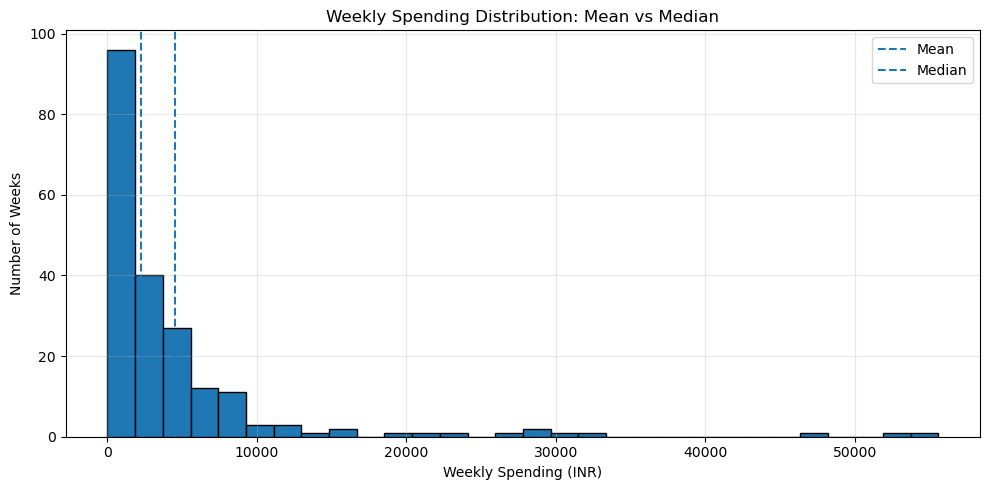

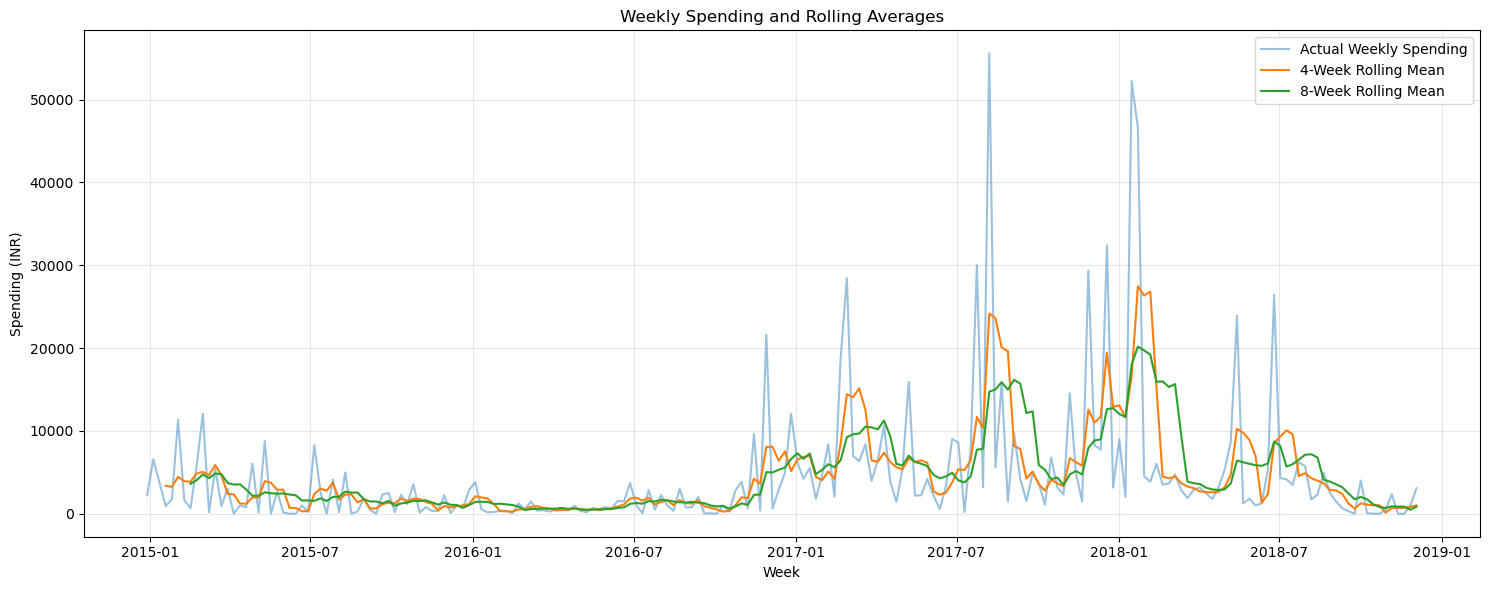


YEAR-WISE WEEKLY SPENDING


,Total,Average,Median,Standard_Deviation,Maximum,Active_Weeks
Year,,,,,,
2014,2254.00,2254.00,2254.0,NaN,2254.0,1
2015,118047.40,2270.14,999.5,2920.17,12082.0,45
2016,97593.20,1876.79,654.5,3577.17,21637.0,51
2017,440970.67,8480.21,5174.5,10188.76,55597.0,52
2018,278128.36,5676.09,2883.0,10389.68,52244.0,44


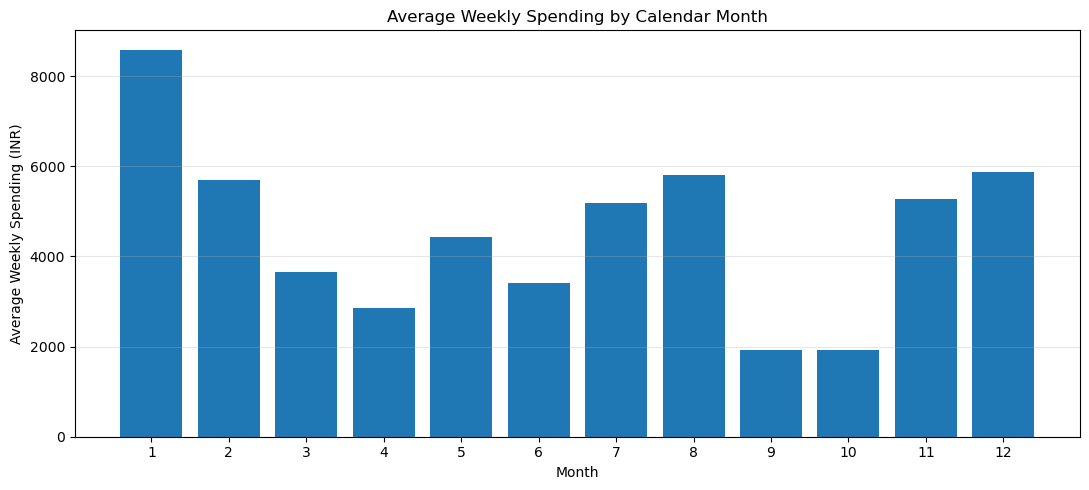

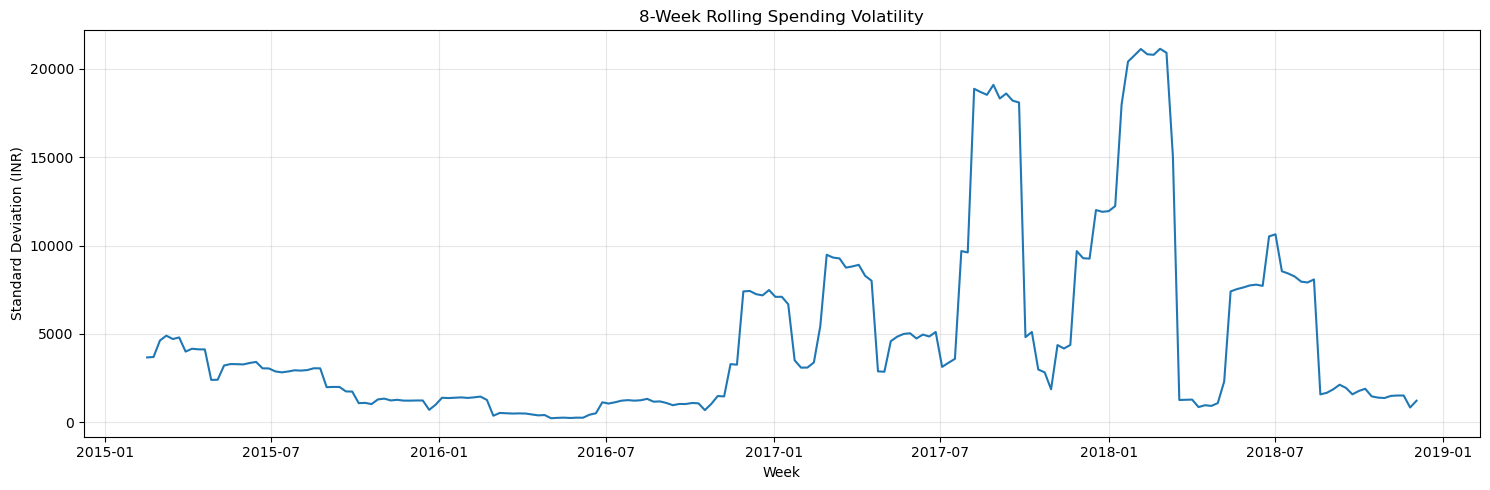


STEP 2 COMPLETED


In [31]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 2: WEEKLY SPENDING EXPLORATORY DATA ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. DISTRIBUTION ANALYSIS
# ------------------------------------------------------------

print("WEEKLY SPENDING DISTRIBUTION")

print("Mean:", round(weekly_spending.mean(), 2))
print("Median:", round(weekly_spending.median(), 2))
print("Standard Deviation:", round(weekly_spending.std(), 2))
print("Skewness:", round(weekly_spending.skew(), 3))
print("Kurtosis:", round(weekly_spending.kurtosis(), 3))

# ------------------------------------------------------------
# 2. MEAN VS MEDIAN
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.hist(
    weekly_spending,
    bins=30,
    edgecolor="black"
)

plt.axvline(
    weekly_spending.mean(),
    linestyle="--",
    label="Mean"
)

plt.axvline(
    weekly_spending.median(),
    linestyle="--",
    label="Median"
)

plt.title("Weekly Spending Distribution: Mean vs Median")
plt.xlabel("Weekly Spending (INR)")
plt.ylabel("Number of Weeks")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. ROLLING AVERAGE ANALYSIS
# ------------------------------------------------------------

weekly_rolling = pd.DataFrame(index=weekly_spending.index)

weekly_rolling["Actual"] = weekly_spending
weekly_rolling["4_Week_Mean"] = weekly_spending.rolling(
    window=4
).mean()

weekly_rolling["8_Week_Mean"] = weekly_spending.rolling(
    window=8
).mean()

plt.figure(figsize=(15, 6))

plt.plot(
    weekly_rolling.index.to_timestamp(),
    weekly_rolling["Actual"],
    alpha=0.45,
    label="Actual Weekly Spending"
)

plt.plot(
    weekly_rolling.index.to_timestamp(),
    weekly_rolling["4_Week_Mean"],
    label="4-Week Rolling Mean"
)

plt.plot(
    weekly_rolling.index.to_timestamp(),
    weekly_rolling["8_Week_Mean"],
    label="8-Week Rolling Mean"
)

plt.title("Weekly Spending and Rolling Averages")
plt.xlabel("Week")
plt.ylabel("Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. YEAR-WISE SPENDING ANALYSIS
# ------------------------------------------------------------

yearly_weekly = weekly_spending.to_frame()

yearly_weekly["Year"] = (
    yearly_weekly.index.to_timestamp().year
)

yearly_summary = yearly_weekly.groupby("Year")[
    "Total_Spending"
].agg(
    Total="sum",
    Average="mean",
    Median="median",
    Standard_Deviation="std",
    Maximum="max",
    Active_Weeks=lambda x: (x > 0).sum()
)

print("\nYEAR-WISE WEEKLY SPENDING")
display(yearly_summary.round(2))

# ------------------------------------------------------------
# 5. MONTH-WISE AVERAGE WEEKLY SPENDING
# ------------------------------------------------------------

monthly_pattern = pd.DataFrame({
    "Spending": weekly_spending.values,
    "Month": weekly_spending.index.to_timestamp().month
})

month_summary = monthly_pattern.groupby("Month")[
    "Spending"
].mean()

plt.figure(figsize=(11, 5))

plt.bar(
    month_summary.index,
    month_summary.values
)

plt.title("Average Weekly Spending by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Weekly Spending (INR)")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. SPENDING VOLATILITY
# ------------------------------------------------------------

rolling_volatility = weekly_spending.rolling(
    window=8
).std()

plt.figure(figsize=(15, 5))

plt.plot(
    rolling_volatility.index.to_timestamp(),
    rolling_volatility
)

plt.title("8-Week Rolling Spending Volatility")
plt.xlabel("Week")
plt.ylabel("Standard Deviation (INR)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSTEP 2 COMPLETED")


In [32]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 3: UNUSUAL WEEKLY SPENDING INVESTIGATION
# ============================================================

# 1. IDENTIFY TOP 15 HIGHEST-SPENDING WEEKS

top_weeks = weekly_spending.nlargest(15)

print("TOP 15 HIGH-SPENDING WEEKS")
display(top_weeks.to_frame().round(2))

# 2. INVESTIGATE CATEGORY CONTRIBUTIONS

high_week_periods = top_weeks.index

high_week_transactions = household_df[
    household_df["Week"].isin(high_week_periods)
].copy()

category_analysis = (
    high_week_transactions
    .groupby(["Week", "Category"])["Amount"]
    .sum()
    .reset_index()
    .sort_values(["Week", "Amount"], ascending=[True, False])
)

print("\nCATEGORY CONTRIBUTION IN HIGH-SPENDING WEEKS")

for week in high_week_periods:
    print("\nWeek:", week)

    week_categories = category_analysis[
        category_analysis["Week"] == week
    ]

    display(week_categories.head(5).round(2))

# 3. INSPECT LARGEST INDIVIDUAL TRANSACTIONS

print("\nLARGEST TRANSACTIONS IN HIGH-SPENDING WEEKS")

transaction_columns = [
    "Date",
    "Week",
    "Category",
    "Note",
    "Amount"
]

largest_transactions = (
    high_week_transactions[
        transaction_columns
    ]
    .sort_values("Amount", ascending=False)
    .head(30)
)

display(largest_transactions)

# 4. CALCULATE HOW MUCH TOP WEEKS CONTRIBUTE

total_spending = weekly_spending.sum()

top_5_contribution = (
    top_weeks.head(5).sum() / total_spending
) * 100

top_10_contribution = (
    top_weeks.head(10).sum() / total_spending
) * 100

print("\nHIGH-SPENDING WEEK CONTRIBUTION")

print(
    "Top 5 weeks contribution:",
    round(top_5_contribution, 2), "%"
)

print(
    "Top 10 weeks contribution:",
    round(top_10_contribution, 2), "%"
)

# 5. COMPARE YEARLY MEDIAN AND MEAN

yearly_comparison = weekly_spending.to_frame()

yearly_comparison["Year"] = (
    yearly_comparison.index.to_timestamp().year
)

yearly_comparison = yearly_comparison.groupby("Year")[
    "Total_Spending"
].agg(
    Mean="mean",
    Median="median",
    Maximum="max"
)

print("\nYEARLY SPENDING COMPARISON")
display(yearly_comparison.round(2))

print("\nSTEP 3 COMPLETED")


TOP 15 HIGH-SPENDING WEEKS


,Total_Spending
Week,
2017-08-07/2017-08-13,55597.00
2018-01-15/2018-01-21,52244.00
2018-01-22/2018-01-28,46613.90
2017-12-18/2017-12-24,32431.00
2017-07-24/2017-07-30,30001.00
2017-11-27/2017-12-03,29370.00
2017-02-27/2017-03-05,28453.47
2018-06-25/2018-07-01,26429.67
2018-05-14/2018-05-20,23914.00



CATEGORY CONTRIBUTION IN HIGH-SPENDING WEEKS

Week: 2017-08-07/2017-08-13


,Week,Category,Amount
45,2017-08-07/2017-08-13,Tourism,43000.0
43,2017-08-07/2017-08-13,Gift,6500.0
41,2017-08-07/2017-08-13,Family,3198.0
46,2017-08-07/2017-08-13,Transportation,1440.0
42,2017-08-07/2017-08-13,Food,920.0



Week: 2018-01-15/2018-01-21


,Week,Category,Amount
80,2018-01-15/2018-01-21,Transportation,50306.0
77,2018-01-15/2018-01-21,Food,1197.0
79,2018-01-15/2018-01-21,Social Life,298.0
78,2018-01-15/2018-01-21,Household,264.0
81,2018-01-15/2018-01-21,subscription,179.0


... (27 outputs left out)

,Date,Week,Category,Note,Amount
608,2018-01-18,2018-01-15/2018-01-21,Transportation,Two Wheeler Bikedelux second installment,50000.00
582,2018-01-27,2018-01-22/2018-01-28,Transportation,Two Wheeler Bikedelux third installment,43000.00
1076,2017-08-08,2017-08-07/2017-08-13,Tourism,Tours and Travel,43000.00
706,2017-12-20,2017-12-18/2017-12-24,subscription,Renewal,28400.00
770,2017-11-30,2017-11-27/2017-12-03,Health,Family's Glasses,22700.00
268,2018-05-15,2018-05-14/2018-05-20,Household,LG Washing Machine,21500.00
1773,2016-11-28,2016-11-28/2016-12-04,Household,Metz 32 inch TV,20500.00
1132,2017-07-25,2017-07-24/2017-07-30,Tourism,Tours and Travel,20000.00
218,2018-06-26,2018-06-25/2018-07-01,Household,Aqugurad water purifier,13050.00
1395,2017-03-05,2017-02-27/2017-03-05,Household,Gas stove elica 3 burner,8825.00



HIGH-SPENDING WEEK CONTRIBUTION
Top 5 weeks contribution: 23.15 %
Top 10 weeks contribution: 37.0 %

YEARLY SPENDING COMPARISON


,Mean,Median,Maximum
Year,,,
2014,2254.00,2254.0,2254.0
2015,2270.14,999.5,12082.0
2016,1876.79,654.5,21637.0
2017,8480.21,5174.5,55597.0
2018,5676.09,2883.0,52244.0



STEP 3 COMPLETED


Weekly observations: 206
Start: 2014-12-29 00:00:00
End: 2018-12-03 00:00:00


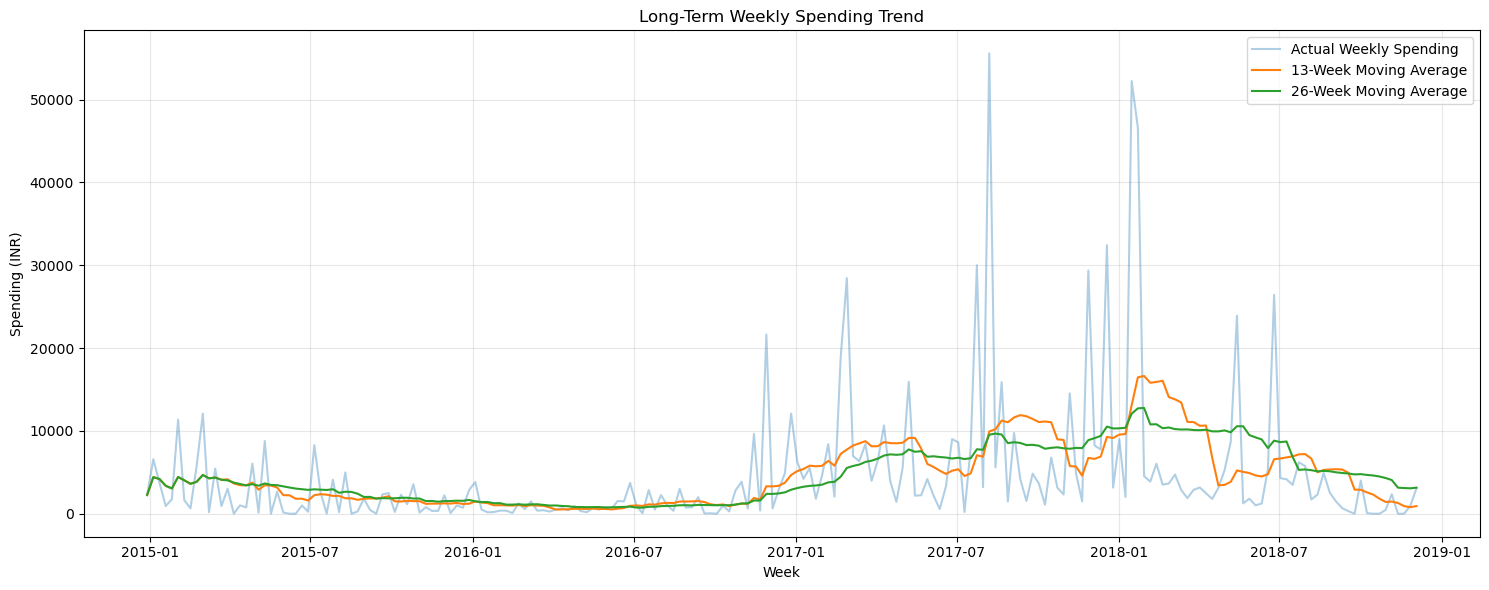


ANNUAL WEEKLY SEASONALITY PROFILE


,Mean,Median,Observations
ISO_Week,,,
1,5327.67,5028.00,4
2,3325.00,3112.50,4
3,15416.00,4625.50,4
4,12386.72,1367.00,4
5,2830.25,3149.00,4
6,5996.50,6130.50,4
7,2456.50,1851.00,4
8,6056.00,2377.50,4
9,9610.12,4718.00,4


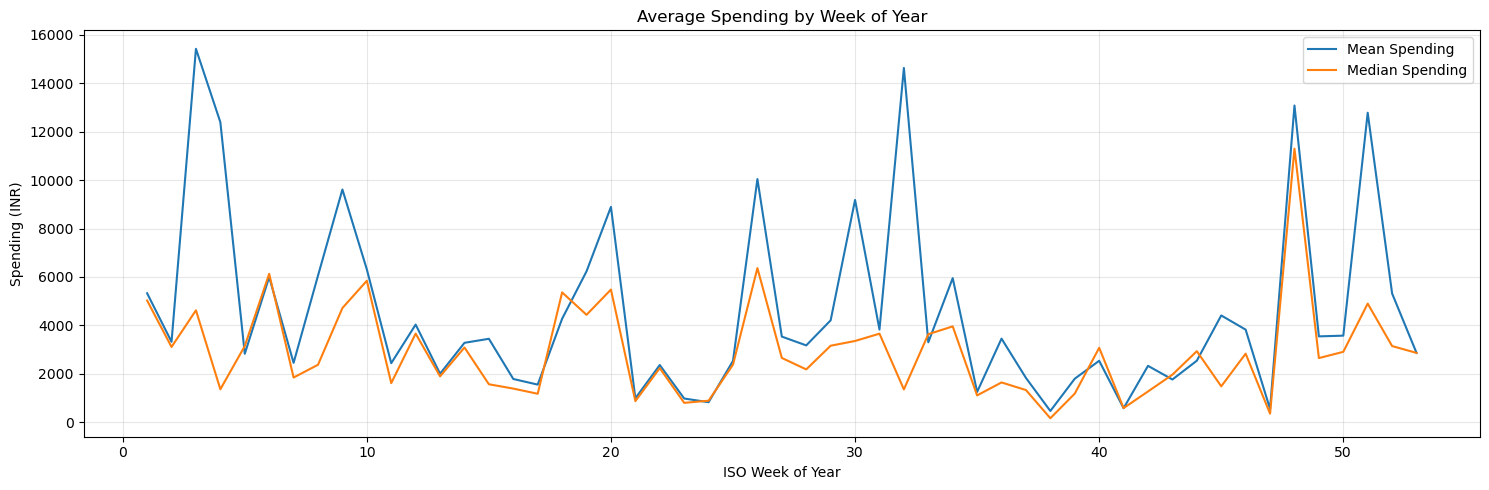

<Figure size 1200x500 with 0 Axes>

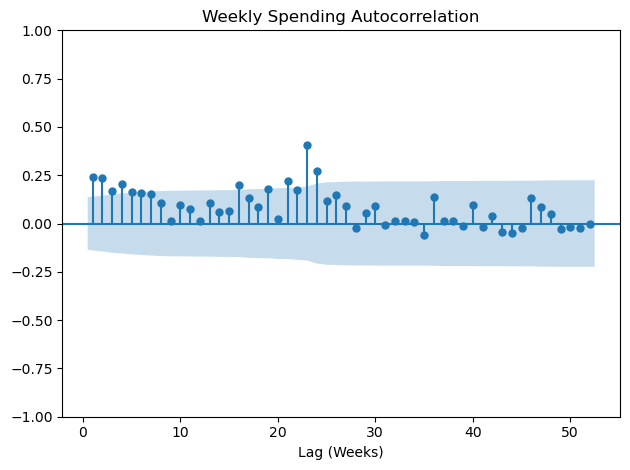

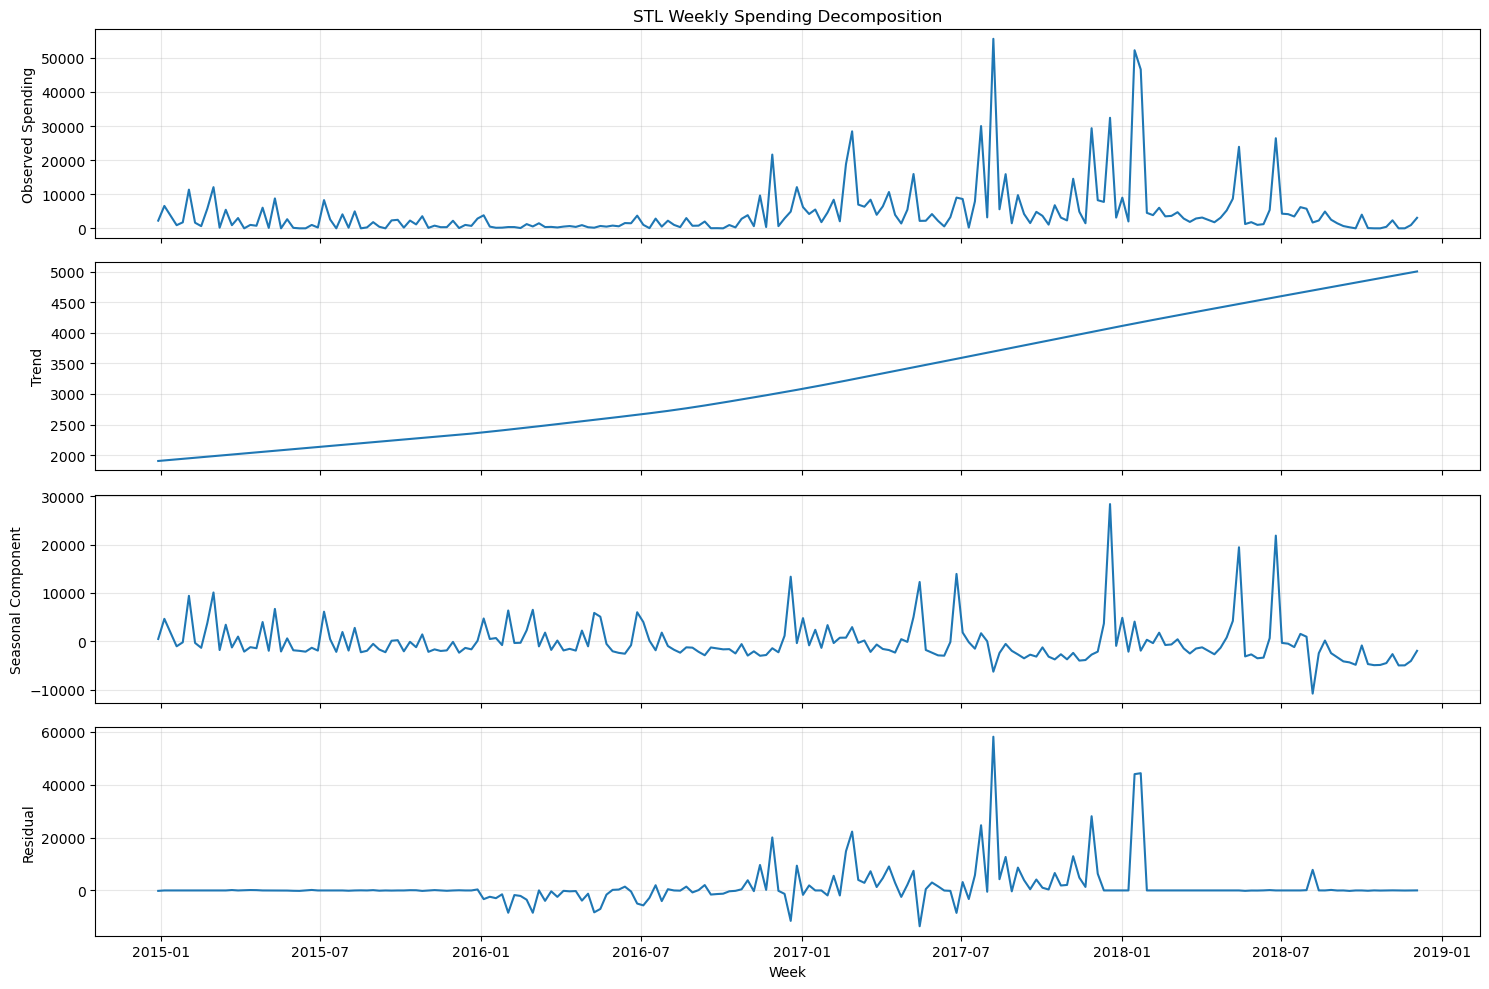


STL COMPONENT SUMMARY
Trend standard deviation: 947.95
Seasonal standard deviation: 4309.98
Residual standard deviation: 7457.5

COMPONENT VARIATION COMPARISON


,Component,Standard_Deviation
0,Trend,947.95
1,Seasonal,4309.98
2,Residual,7457.50



STEP 4 COMPLETED


In [33]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 4: TREND AND SEASONALITY ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf

# ------------------------------------------------------------
# 1. PREPARE WEEKLY TIME SERIES
# ------------------------------------------------------------

weekly_series = weekly_spending.astype(float).copy()

weekly_dates = weekly_series.index.to_timestamp()

print("Weekly observations:", len(weekly_series))
print("Start:", weekly_dates.min())
print("End:", weekly_dates.max())

# ------------------------------------------------------------
# 2. LONG-TERM TREND ANALYSIS
# ------------------------------------------------------------

trend_13 = weekly_series.rolling(
    window=13,
    min_periods=1
).mean()

trend_26 = weekly_series.rolling(
    window=26,
    min_periods=1
).mean()

plt.figure(figsize=(15, 6))

plt.plot(
    weekly_dates,
    weekly_series.values,
    alpha=0.35,
    label="Actual Weekly Spending"
)

plt.plot(
    weekly_dates,
    trend_13.values,
    label="13-Week Moving Average"
)

plt.plot(
    weekly_dates,
    trend_26.values,
    label="26-Week Moving Average"
)

plt.title("Long-Term Weekly Spending Trend")
plt.xlabel("Week")
plt.ylabel("Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. ANNUAL SEASONALITY ANALYSIS
# ------------------------------------------------------------

seasonal_df = pd.DataFrame({
    "Spending": weekly_series.values,
    "Date": weekly_dates
})

seasonal_df["ISO_Week"] = (
    seasonal_df["Date"].dt.isocalendar().week.astype(int)
)

seasonal_df["Year"] = seasonal_df["Date"].dt.year

seasonal_profile = seasonal_df.groupby(
    "ISO_Week"
)["Spending"].agg(
    Mean="mean",
    Median="median",
    Observations="count"
)

print("\nANNUAL WEEKLY SEASONALITY PROFILE")

display(seasonal_profile.round(2))

plt.figure(figsize=(15, 5))

plt.plot(
    seasonal_profile.index,
    seasonal_profile["Mean"],
    label="Mean Spending"
)

plt.plot(
    seasonal_profile.index,
    seasonal_profile["Median"],
    label="Median Spending"
)

plt.title("Average Spending by Week of Year")
plt.xlabel("ISO Week of Year")
plt.ylabel("Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. AUTOCORRELATION ANALYSIS
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plot_acf(
    weekly_series,
    lags=52,
    zero=False
)

plt.title("Weekly Spending Autocorrelation")
plt.xlabel("Lag (Weeks)")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. STL DECOMPOSITION
# ANNUAL PERIOD = 52 WEEKS
# ------------------------------------------------------------

stl_result = STL(
    weekly_series,
    period=52,
    robust=True
).fit()

# Convert components to arrays for reliable plotting

stl_components = [
    ("Observed Spending", weekly_series.values),
    ("Trend", np.asarray(stl_result.trend)),
    ("Seasonal Component", np.asarray(stl_result.seasonal)),
    ("Residual", np.asarray(stl_result.resid))
]

fig, axes = plt.subplots(
    4,
    1,
    figsize=(15, 10),
    sharex=True
)

for ax, (label, values) in zip(
    axes,
    stl_components
):

    ax.plot(
        weekly_dates,
        values
    )

    ax.set_ylabel(label)
    ax.grid(alpha=0.3)

axes[0].set_title(
    "STL Weekly Spending Decomposition"
)

axes[-1].set_xlabel("Week")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. COMPONENT VARIATION
# ------------------------------------------------------------

print("\nSTL COMPONENT SUMMARY")

print(
    "Trend standard deviation:",
    round(stl_result.trend.std(), 2)
)

print(
    "Seasonal standard deviation:",
    round(stl_result.seasonal.std(), 2)
)

print(
    "Residual standard deviation:",
    round(stl_result.resid.std(), 2)
)

# ------------------------------------------------------------
# 7. FINAL INTERPRETATION SUPPORT
# ------------------------------------------------------------

component_variation = pd.DataFrame({
    "Component": [
        "Trend",
        "Seasonal",
        "Residual"
    ],
    "Standard_Deviation": [
        stl_result.trend.std(),
        stl_result.seasonal.std(),
        stl_result.resid.std()
    ]
})

print("\nCOMPONENT VARIATION COMPARISON")

display(component_variation.round(2))

print("\nSTEP 4 COMPLETED")



SERIES: Original Weekly Spending

ADF TEST
ADF Statistic: -7.1893
p-value: 0.0
Used Lags: 1
Observations: 204

KPSS TEST
KPSS Statistic: 0.6853
p-value: 0.0149
Used Lags: 7

INTERPRETATION
ADF: Stationary
KPSS: Non-stationary
Conclusion: Tests disagree; further investigation needed

SERIES: First Difference

ADF TEST
ADF Statistic: -6.4148
p-value: 0.0
Used Lags: 14
Observations: 190

KPSS TEST
KPSS Statistic: 0.1342
p-value: 0.1
Used Lags: 57

INTERPRETATION
ADF: Stationary
KPSS: Stationary
Conclusion: Both tests support stationarity

SERIES: Second Difference

ADF TEST
ADF Statistic: -6.9631
p-value: 0.0
Used Lags: 15
Observations: 188

KPSS TEST
KPSS Statistic: 0.1219
p-value: 0.1
Used Lags: 35

INTERPRETATION
ADF: Stationary
KPSS: Stationary
Conclusion: Both tests support stationarity

STATIONARITY COMPARISON


,Series,ADF_Statistic,ADF_p_value,KPSS_Statistic,KPSS_p_value,Conclusion
0,Original Weekly Spending,-7.1893,0.0,0.6853,0.0149,Tests disagree; further investigation needed
1,First Difference,-6.4148,0.0,0.1342,0.1000,Both tests support stationarity
2,Second Difference,-6.9631,0.0,0.1219,0.1000,Both tests support stationarity


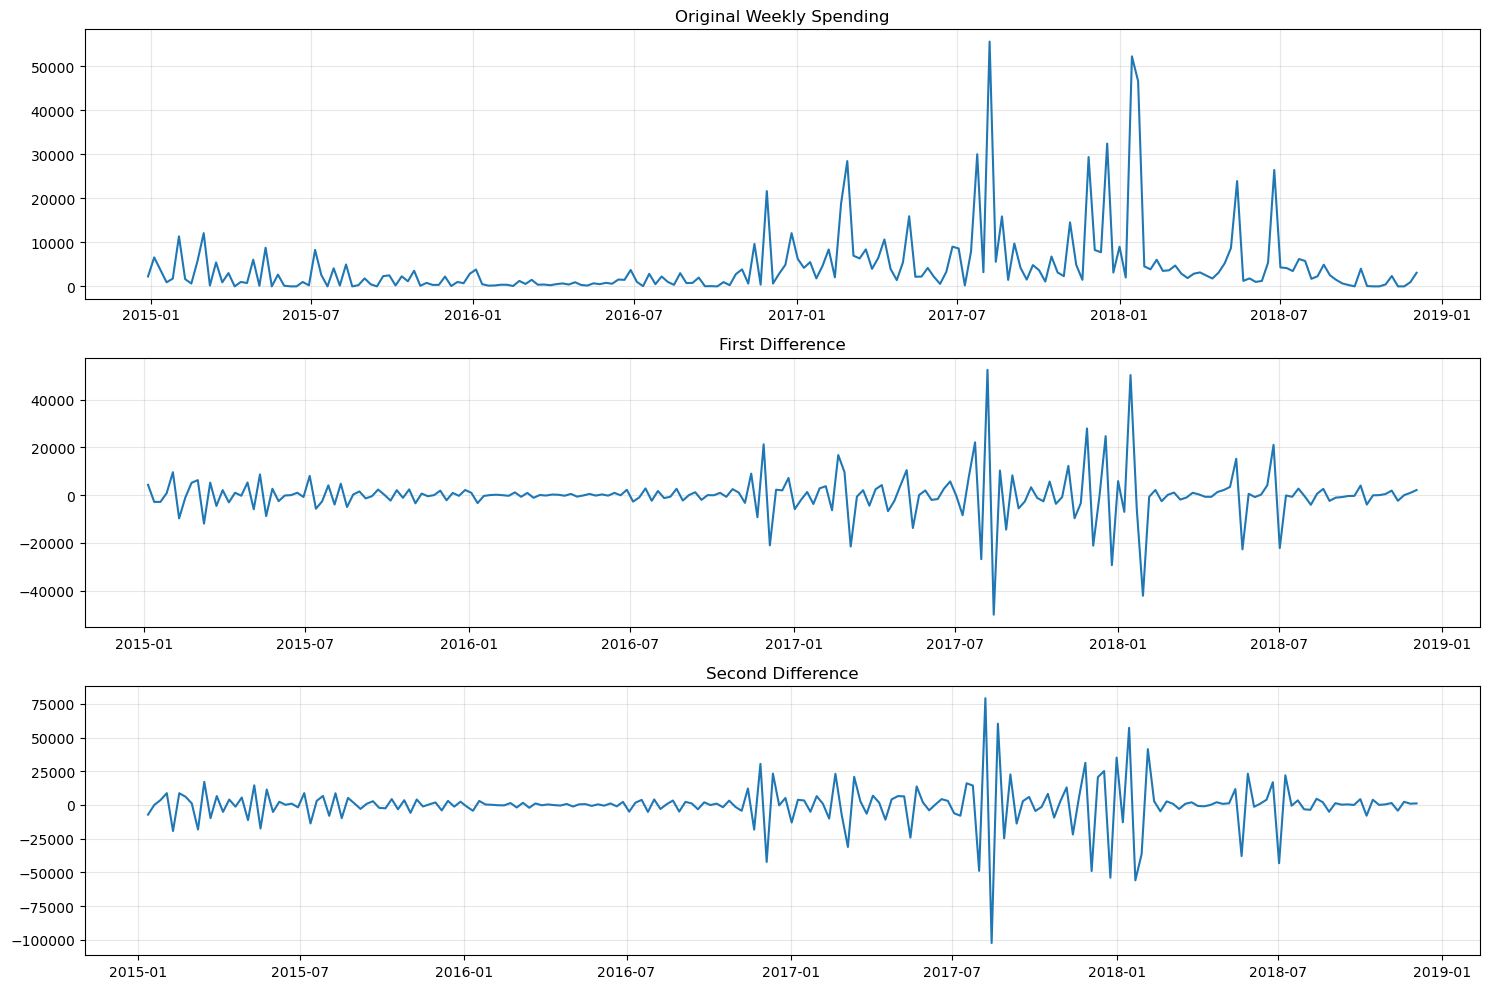


STEP 5 COMPLETED


In [34]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 5: STATIONARITY ANALYSIS
# ============================================================

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss

# ------------------------------------------------------------
# 1. DEFINE STATIONARITY TEST FUNCTION
# ------------------------------------------------------------

def run_stationarity_tests(series, series_name):

    series = series.dropna().astype(float)

    print("\n" + "=" * 55)
    print("SERIES:", series_name)
    print("=" * 55)

    # ADF TEST
    adf_result = adfuller(
        series,
        autolag="AIC"
    )

    # KPSS TEST
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        kpss_result = kpss(
            series,
            regression="c",
            nlags="auto"
        )

    print("\nADF TEST")
    print("ADF Statistic:", round(adf_result[0], 4))
    print("p-value:", round(adf_result[1], 4))
    print("Used Lags:", adf_result[2])
    print("Observations:", adf_result[3])

    print("\nKPSS TEST")
    print("KPSS Statistic:", round(kpss_result[0], 4))
    print("p-value:", round(kpss_result[1], 4))
    print("Used Lags:", kpss_result[2])

    # INTERPRETATION
    adf_stationary = adf_result[1] < 0.05
    kpss_stationary = kpss_result[1] >= 0.05

    print("\nINTERPRETATION")

    print(
        "ADF:",
        "Stationary" if adf_stationary
        else "Non-stationary"
    )

    print(
        "KPSS:",
        "Stationary" if kpss_stationary
        else "Non-stationary"
    )

    if adf_stationary and kpss_stationary:
        conclusion = "Both tests support stationarity"
    elif not adf_stationary and not kpss_stationary:
        conclusion = "Both tests indicate non-stationarity"
    else:
        conclusion = "Tests disagree; further investigation needed"

    print("Conclusion:", conclusion)

    return {
        "Series": series_name,
        "ADF_Statistic": adf_result[0],
        "ADF_p_value": adf_result[1],
        "KPSS_Statistic": kpss_result[0],
        "KPSS_p_value": kpss_result[1],
        "Conclusion": conclusion
    }


# ------------------------------------------------------------
# 2. TEST ORIGINAL WEEKLY SPENDING
# ------------------------------------------------------------

original_result = run_stationarity_tests(
    weekly_spending,
    "Original Weekly Spending"
)

# ------------------------------------------------------------
# 3. FIRST DIFFERENCING
# ------------------------------------------------------------

weekly_diff_1 = weekly_spending.diff().dropna()

first_diff_result = run_stationarity_tests(
    weekly_diff_1,
    "First Difference"
)

# ------------------------------------------------------------
# 4. SECOND DIFFERENCING
# ------------------------------------------------------------

weekly_diff_2 = weekly_spending.diff().diff().dropna()

second_diff_result = run_stationarity_tests(
    weekly_diff_2,
    "Second Difference"
)

# ------------------------------------------------------------
# 5. COMPARE RESULTS
# ------------------------------------------------------------

stationarity_results = pd.DataFrame([
    original_result,
    first_diff_result,
    second_diff_result
])

print("\nSTATIONARITY COMPARISON")

display(stationarity_results.round(4))

# ------------------------------------------------------------
# 6. VISUALIZE DIFFERENCING
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 10)
)

series_list = [
    (weekly_spending, "Original Weekly Spending"),
    (weekly_diff_1, "First Difference"),
    (weekly_diff_2, "Second Difference")
]

for ax, (series, title) in zip(axes, series_list):

    ax.plot(
        series.index.to_timestamp(),
        series.values
    )

    ax.set_title(title)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\nSTEP 5 COMPLETED")


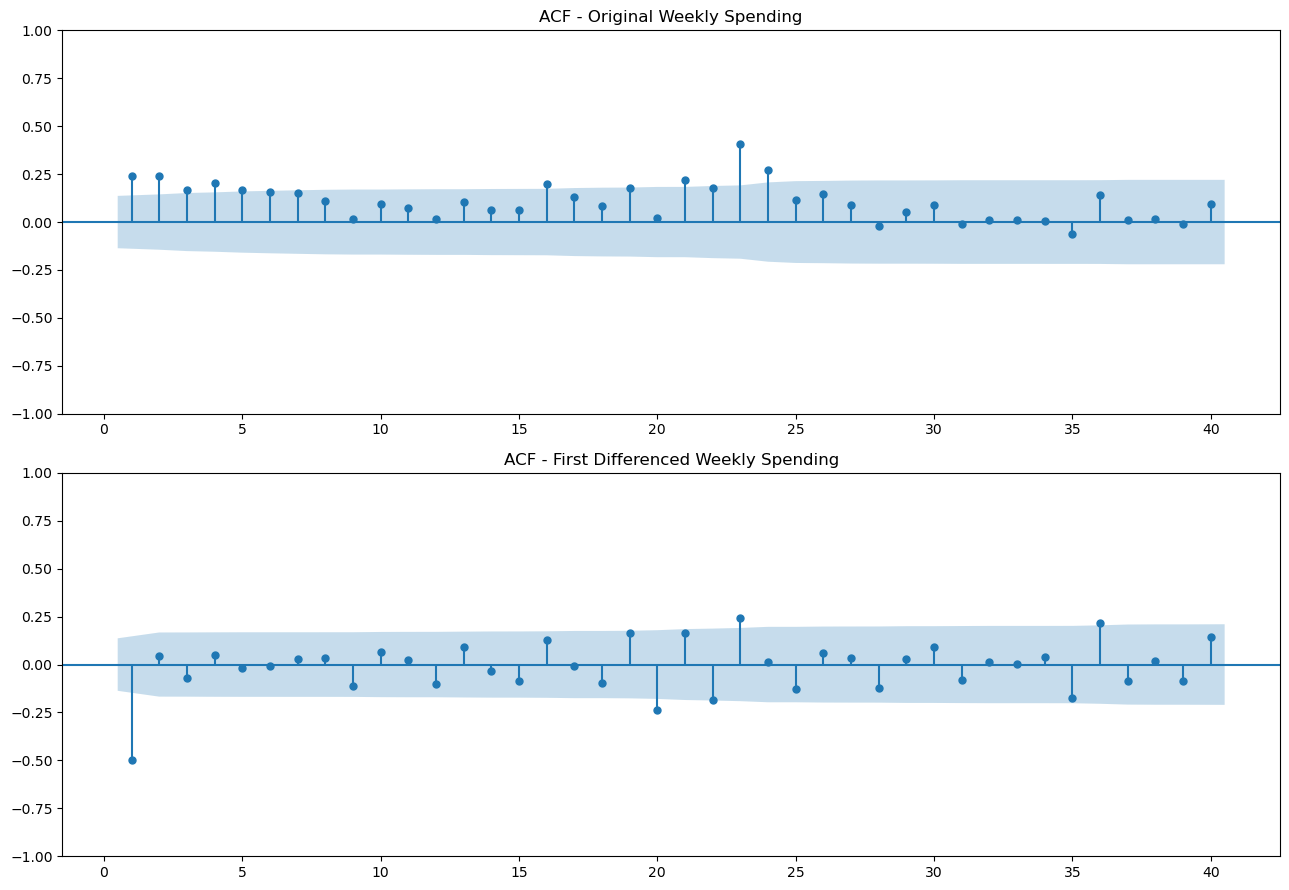

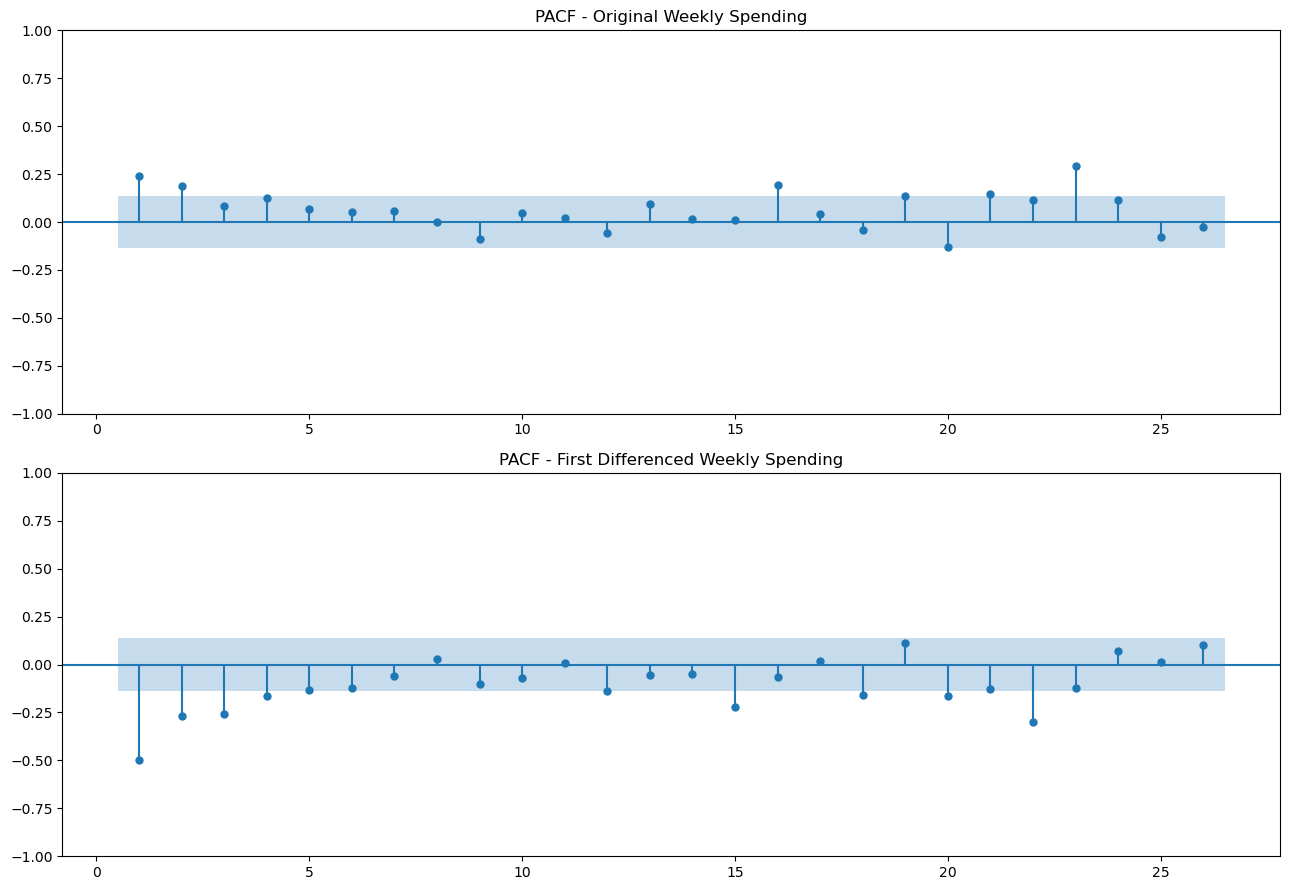

FIRST DIFFERENCE AUTOCORRELATION
Lag 1 correlation: -0.4975

STEP 6 COMPLETED


In [35]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 6: ACF AND PACF ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ------------------------------------------------------------
# 1. PREPARE ORIGINAL AND DIFFERENCED SERIES
# ------------------------------------------------------------

original_series = weekly_spending.astype(float)

differenced_series = original_series.diff().dropna()

# ------------------------------------------------------------
# 2. ACF — ORIGINAL SERIES
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

plot_acf(
    original_series,
    lags=40,
    zero=False,
    ax=axes[0]
)

axes[0].set_title("ACF - Original Weekly Spending")

# ------------------------------------------------------------
# 3. ACF — FIRST DIFFERENCED SERIES
# ------------------------------------------------------------

plot_acf(
    differenced_series,
    lags=40,
    zero=False,
    ax=axes[1]
)

axes[1].set_title("ACF - First Differenced Weekly Spending")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. PACF — ORIGINAL SERIES
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

plot_pacf(
    original_series,
    lags=26,
    zero=False,
    method="ywm",
    ax=axes[0]
)

axes[0].set_title("PACF - Original Weekly Spending")

# ------------------------------------------------------------
# 5. PACF — FIRST DIFFERENCED SERIES
# ------------------------------------------------------------

plot_pacf(
    differenced_series,
    lags=26,
    zero=False,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("PACF - First Differenced Weekly Spending")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. NUMERICAL CORRELATION VALUES
# ------------------------------------------------------------

acf_values = differenced_series.autocorr(lag=1)

print("FIRST DIFFERENCE AUTOCORRELATION")
print("Lag 1 correlation:", round(acf_values, 4))

print("\nSTEP 6 COMPLETED")


CHRONOLOGICAL DATA SPLIT


,Dataset,Observations,Start,End
0,Initial Training,104,2014-12-29/2015-01-04,2016-12-19/2016-12-25
1,Validation,76,2016-12-26/2017-01-01,2018-06-04/2018-06-10
2,Final Test,26,2018-06-11/2018-06-17,2018-12-03/2018-12-09



DATA SPLIT VERIFICATION PASSED


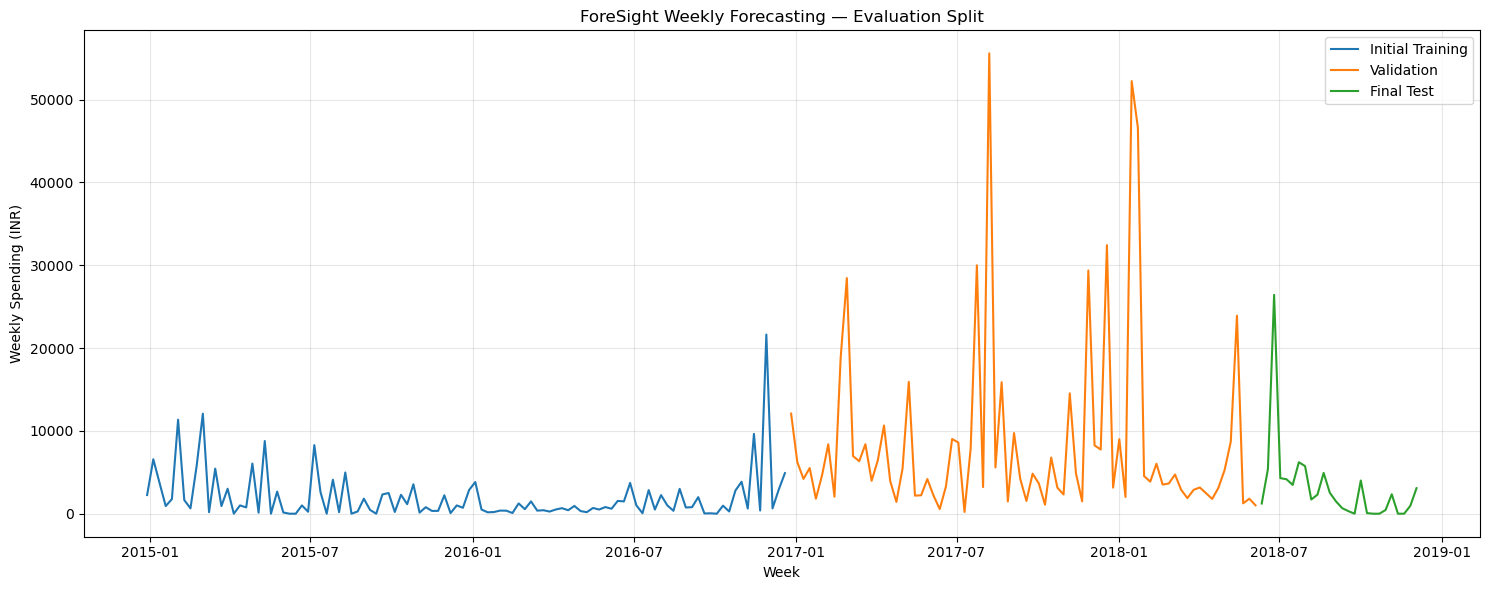


VALIDATION SETTINGS
Initial training weeks: 104
Validation forecast origins: 76
Final test forecast origins: 26

VALIDATION FIRST FORECAST:
2016-12-26/2017-01-01

FINAL TEST FIRST FORECAST:
2018-06-11/2018-06-17

STEP 7 COMPLETED


In [36]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 7: CHRONOLOGICAL TRAINING AND TEST SPLIT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. DEFINE EVALUATION SETTINGS
# ------------------------------------------------------------

INITIAL_TRAIN_SIZE = 104
FINAL_TEST_SIZE = 26

TOTAL_WEEKS = len(weekly_spending)

VALIDATION_SIZE = (
    TOTAL_WEEKS -
    INITIAL_TRAIN_SIZE -
    FINAL_TEST_SIZE
)

if VALIDATION_SIZE <= 0:
    raise ValueError(
        "Not enough weekly observations for the selected split."
    )

# ------------------------------------------------------------
# 2. CREATE CHRONOLOGICAL DATA SPLITS
# ------------------------------------------------------------

train_data = weekly_spending.iloc[
    :INITIAL_TRAIN_SIZE
].copy()

validation_data = weekly_spending.iloc[
    INITIAL_TRAIN_SIZE:
    TOTAL_WEEKS - FINAL_TEST_SIZE
].copy()

final_test_data = weekly_spending.iloc[
    TOTAL_WEEKS - FINAL_TEST_SIZE:
].copy()

# ------------------------------------------------------------
# 3. DISPLAY DATASET INFORMATION
# ------------------------------------------------------------

split_summary = pd.DataFrame({
    "Dataset": [
        "Initial Training",
        "Validation",
        "Final Test"
    ],
    "Observations": [
        len(train_data),
        len(validation_data),
        len(final_test_data)
    ],
    "Start": [
        train_data.index.min(),
        validation_data.index.min(),
        final_test_data.index.min()
    ],
    "End": [
        train_data.index.max(),
        validation_data.index.max(),
        final_test_data.index.max()
    ]
})

print("CHRONOLOGICAL DATA SPLIT")

display(split_summary)

# ------------------------------------------------------------
# 4. VERIFY NO OVERLAPPING PERIODS
# ------------------------------------------------------------

assert train_data.index.max() < validation_data.index.min()

assert validation_data.index.max() < final_test_data.index.min()

assert len(train_data) + len(validation_data) + len(final_test_data) == TOTAL_WEEKS

print("\nDATA SPLIT VERIFICATION PASSED")

# ------------------------------------------------------------
# 5. VISUALIZE DATA SPLITS
# ------------------------------------------------------------

plt.figure(figsize=(15, 6))

plt.plot(
    train_data.index.to_timestamp(),
    train_data.values,
    label="Initial Training"
)

plt.plot(
    validation_data.index.to_timestamp(),
    validation_data.values,
    label="Validation"
)

plt.plot(
    final_test_data.index.to_timestamp(),
    final_test_data.values,
    label="Final Test"
)

plt.title("ForeSight Weekly Forecasting — Evaluation Split")
plt.xlabel("Week")
plt.ylabel("Weekly Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. DEFINE EXPANDING-WINDOW VALIDATION ORIGINS
# ------------------------------------------------------------

validation_origins = list(
    range(
        INITIAL_TRAIN_SIZE,
        TOTAL_WEEKS - FINAL_TEST_SIZE
    )
)

test_origins = list(
    range(
        TOTAL_WEEKS - FINAL_TEST_SIZE,
        TOTAL_WEEKS
    )
)

print("\nVALIDATION SETTINGS")
print("Initial training weeks:", INITIAL_TRAIN_SIZE)
print("Validation forecast origins:", len(validation_origins))
print("Final test forecast origins:", len(test_origins))

print("\nVALIDATION FIRST FORECAST:")
print(weekly_spending.index[validation_origins[0]])

print("\nFINAL TEST FIRST FORECAST:")
print(weekly_spending.index[test_origins[0]])

print("\nSTEP 7 COMPLETED")


BASELINE MODEL PERFORMANCE — VALIDATION


,Model,MAE,RMSE,Bias
0,Rolling_Median_8,6157.41,11520.25,-3384.19
1,Historical_Mean,6365.39,12269.39,-4968.57
2,Rolling_Median_13,6442.82,11863.96,-3574.98
3,Rolling_Median_4,7236.38,12555.41,-1757.43
4,Seasonal_Naive,7796.64,13172.50,-5111.86
5,Moving_Average_8,7913.71,11904.47,1.25
6,Moving_Average_4,8013.93,12141.56,50.51
7,Moving_Average_13,8100.33,12007.74,-33.22
8,Naive,8816.78,14809.49,51.14



BEST MODEL BY MAE: Rolling_Median_8
BEST MODEL BY RMSE: Rolling_Median_8


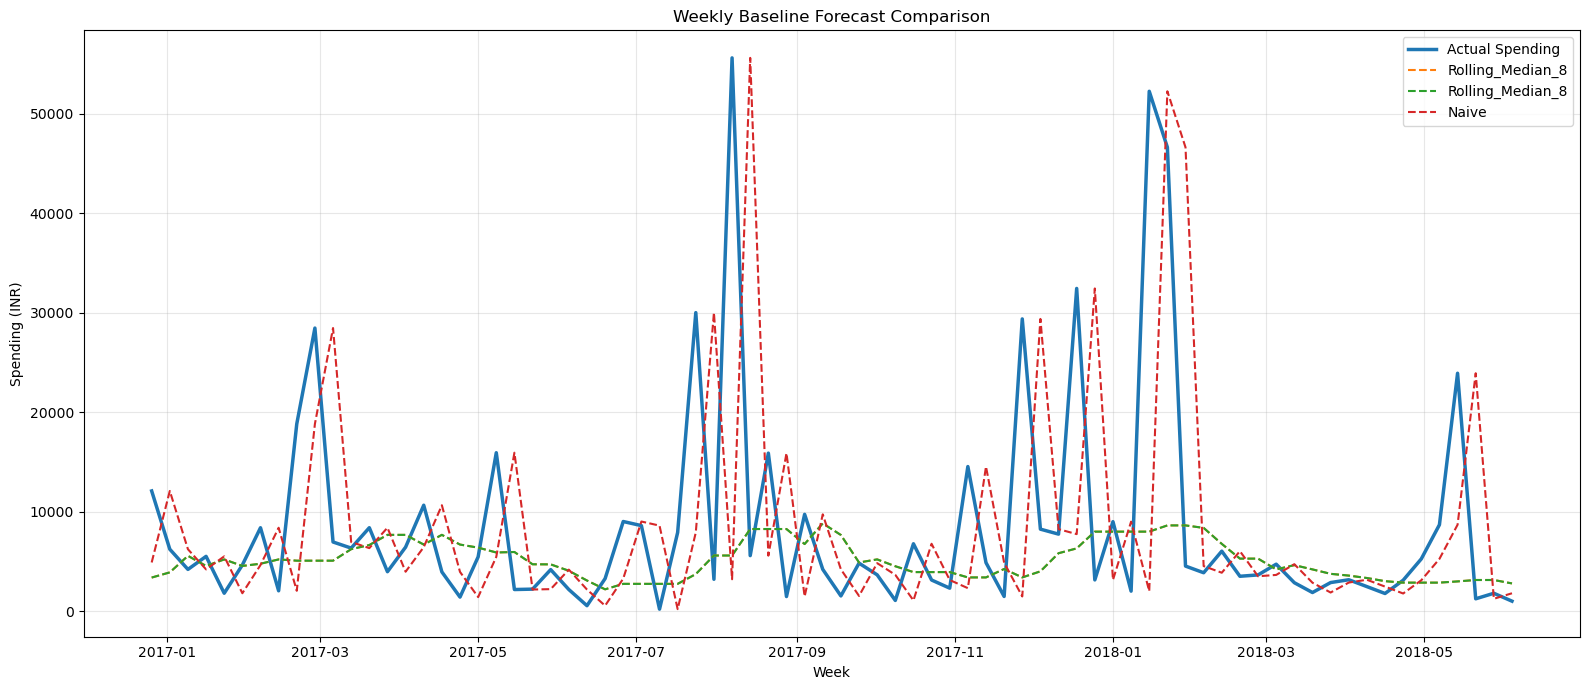


Validation observations: 76
Final test observations remain untouched: 26

STEP 8 COMPLETED


In [37]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 8: BASELINE FORECASTING MODELS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. DEFINE FORECASTING CONFIGURATION
# ------------------------------------------------------------

WINDOWS = [4, 8, 13]

baseline_predictions = pd.DataFrame(
    index=weekly_spending.index[validation_origins]
)

baseline_predictions["Actual"] = weekly_spending.iloc[
    validation_origins
].values

# ------------------------------------------------------------
# 2. EXPANDING-WINDOW BACKTESTING
# ------------------------------------------------------------

for model_name in [
    "Naive",
    "Historical_Mean",
    "Seasonal_Naive"
]:
    baseline_predictions[model_name] = np.nan

for window in WINDOWS:
    baseline_predictions[f"Moving_Average_{window}"] = np.nan
    baseline_predictions[f"Rolling_Median_{window}"] = np.nan

for i in validation_origins:

    history = weekly_spending.iloc[:i]
    target_week = weekly_spending.index[i]

    # NAIVE
    baseline_predictions.loc[target_week, "Naive"] = (
        history.iloc[-1]
    )

    # HISTORICAL MEAN
    baseline_predictions.loc[
        target_week, "Historical_Mean"
    ] = history.mean()

    # SEASONAL NAIVE: SAME WEEK LAST YEAR
    baseline_predictions.loc[
        target_week, "Seasonal_Naive"
    ] = weekly_spending.iloc[i - 52]

    # MOVING AVERAGE AND ROLLING MEDIAN
    for window in WINDOWS:

        recent_history = history.iloc[-window:]

        baseline_predictions.loc[
            target_week,
            f"Moving_Average_{window}"
        ] = recent_history.mean()

        baseline_predictions.loc[
            target_week,
            f"Rolling_Median_{window}"
        ] = recent_history.median()

# ------------------------------------------------------------
# 3. EVALUATE BASELINE MODELS
# ------------------------------------------------------------

from sklearn.metrics import mean_absolute_error, mean_squared_error

model_columns = [
    col for col in baseline_predictions.columns
    if col != "Actual"
]

baseline_metrics = []

for model_name in model_columns:

    actual = baseline_predictions["Actual"]
    predicted = baseline_predictions[model_name]

    baseline_metrics.append({
        "Model": model_name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "Bias": (predicted - actual).mean()
    })

baseline_metrics = pd.DataFrame(
    baseline_metrics
).sort_values("MAE").reset_index(drop=True)

print("BASELINE MODEL PERFORMANCE — VALIDATION")

display(baseline_metrics.round(2))

# ------------------------------------------------------------
# 4. BEST MODEL BY MAE AND RMSE
# ------------------------------------------------------------

best_mae_model = baseline_metrics.iloc[0]["Model"]

best_rmse_model = baseline_metrics.loc[
    baseline_metrics["RMSE"].idxmin(),
    "Model"
]

print("\nBEST MODEL BY MAE:", best_mae_model)
print("BEST MODEL BY RMSE:", best_rmse_model)

# ------------------------------------------------------------
# 5. PLOT ACTUAL VS FORECAST
# ------------------------------------------------------------

plt.figure(figsize=(16, 7))

plt.plot(
    baseline_predictions.index.to_timestamp(),
    baseline_predictions["Actual"],
    label="Actual Spending",
    linewidth=2.5
)

for model_name in [
    best_mae_model,
    best_rmse_model,
    "Naive"
]:

    if model_name not in [
        best_mae_model,
        best_rmse_model
    ] and model_name == best_mae_model:
        continue

    plt.plot(
        baseline_predictions.index.to_timestamp(),
        baseline_predictions[model_name],
        linestyle="--",
        label=model_name
    )

plt.title("Weekly Baseline Forecast Comparison")
plt.xlabel("Week")
plt.ylabel("Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. SAVE VALIDATION RESULTS IN MEMORY
# ------------------------------------------------------------

print("\nValidation observations:", len(baseline_predictions))
print("Final test observations remain untouched:", len(final_test_data))

print("\nSTEP 8 COMPLETED")


EXPONENTIAL SMOOTHING PERFORMANCE


,Model,Valid_Predictions,MAE,RMSE,Bias
0,SES,76,7834.01,11763.91,3.34
1,Damped_Trend,76,8348.73,11990.54,761.21
2,Holt_Trend,76,8487.57,12066.81,865.86



ALL TESTED MODELS — VALIDATION


,Model,MAE,RMSE,Bias,Model_Group,Valid_Predictions
0,Rolling_Median_8,6157.41,11520.25,-3384.19,Baseline,NaN
1,Historical_Mean,6365.39,12269.39,-4968.57,Baseline,NaN
2,Rolling_Median_13,6442.82,11863.96,-3574.98,Baseline,NaN
3,Rolling_Median_4,7236.38,12555.41,-1757.43,Baseline,NaN
4,Seasonal_Naive,7796.64,13172.50,-5111.86,Baseline,NaN
5,SES,7834.01,11763.91,3.34,Exponential Smoothing,76.0
6,Moving_Average_8,7913.71,11904.47,1.25,Baseline,NaN
7,Moving_Average_4,8013.93,12141.56,50.51,Baseline,NaN
8,Moving_Average_13,8100.33,12007.74,-33.22,Baseline,NaN
9,Damped_Trend,8348.73,11990.54,761.21,Exponential Smoothing,76.0


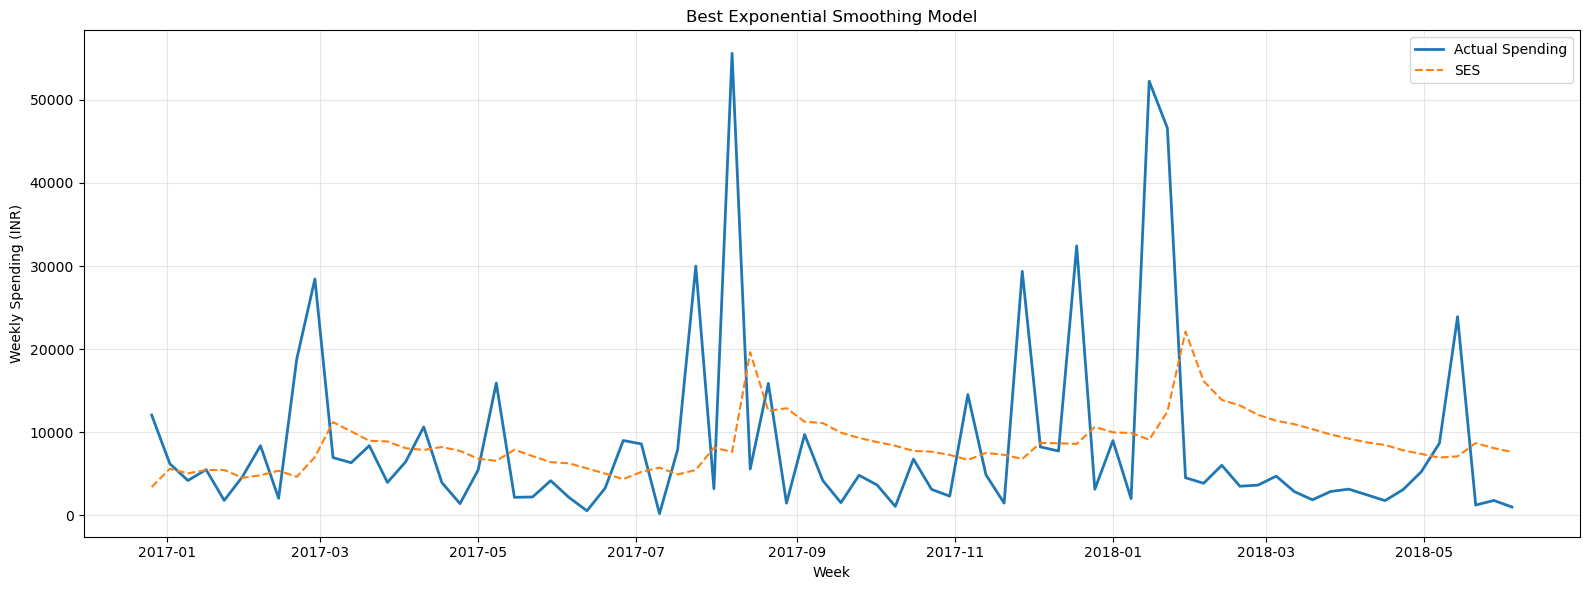


BEST EXPONENTIAL SMOOTHING MODEL: SES
STEP 9 COMPLETED


In [38]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 9: EXPONENTIAL SMOOTHING MODELS
# ============================================================

import numpy as np
import pandas as pd
import warnings

from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing,
    Holt
)

from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. PREPARE PREDICTION STORAGE
# ------------------------------------------------------------

smoothing_predictions = pd.DataFrame(
    index=weekly_spending.index[validation_origins]
)

smoothing_predictions["Actual"] = weekly_spending.iloc[
    validation_origins
].values

model_names = [
    "SES",
    "Holt_Trend",
    "Damped_Trend"
]

for model_name in model_names:
    smoothing_predictions[model_name] = np.nan

# ------------------------------------------------------------
# 2. EXPANDING-WINDOW VALIDATION
# ------------------------------------------------------------

for i in validation_origins:

    history = weekly_spending.iloc[:i].astype(float)
    target_week = weekly_spending.index[i]

    try:
        # SIMPLE EXPONENTIAL SMOOTHING
        ses_model = SimpleExpSmoothing(
            history,
            initialization_method="estimated"
        ).fit(optimized=True)

        smoothing_predictions.loc[
            target_week, "SES"
        ] = ses_model.forecast(1).iloc[0]

    except Exception as e:
        print("SES error at", target_week, ":", e)

    try:
        # HOLT LINEAR TREND
        holt_model = Holt(
            history,
            initialization_method="estimated"
        ).fit(optimized=True)

        smoothing_predictions.loc[
            target_week, "Holt_Trend"
        ] = holt_model.forecast(1).iloc[0]

    except Exception as e:
        print("Holt error at", target_week, ":", e)

    try:
        # DAMPED TREND
        damped_model = Holt(
            history,
            damped_trend=True,
            initialization_method="estimated"
        ).fit(optimized=True)

        smoothing_predictions.loc[
            target_week, "Damped_Trend"
        ] = damped_model.forecast(1).iloc[0]

    except Exception as e:
        print("Damped Trend error at", target_week, ":", e)

# ------------------------------------------------------------
# 3. EVALUATE MODELS
# ------------------------------------------------------------

smoothing_metrics = []

for model_name in model_names:

    actual = smoothing_predictions["Actual"]
    predicted = smoothing_predictions[model_name]

    valid = predicted.notna()

    smoothing_metrics.append({
        "Model": model_name,
        "Valid_Predictions": valid.sum(),
        "MAE": mean_absolute_error(
            actual[valid], predicted[valid]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual[valid], predicted[valid]
            )
        ),
        "Bias": (
            predicted[valid] - actual[valid]
        ).mean()
    })

smoothing_metrics = pd.DataFrame(
    smoothing_metrics
).sort_values("MAE").reset_index(drop=True)

print("EXPONENTIAL SMOOTHING PERFORMANCE")

display(smoothing_metrics.round(2))

# ------------------------------------------------------------
# 4. COMPARE WITH BASELINE MODELS
# ------------------------------------------------------------

combined_metrics = pd.concat(
    [
        baseline_metrics.assign(Model_Group="Baseline"),
        smoothing_metrics.assign(Model_Group="Exponential Smoothing")
    ],
    ignore_index=True
)

combined_metrics = combined_metrics.sort_values(
    "MAE"
).reset_index(drop=True)

print("\nALL TESTED MODELS — VALIDATION")

display(combined_metrics.round(2))

# ------------------------------------------------------------
# 5. VISUALIZE BEST EXPONENTIAL SMOOTHING MODEL
# ------------------------------------------------------------

best_smoothing_model = smoothing_metrics.iloc[0]["Model"]

plt.figure(figsize=(16, 6))

plt.plot(
    smoothing_predictions.index.to_timestamp(),
    smoothing_predictions["Actual"],
    label="Actual Spending",
    linewidth=2
)

plt.plot(
    smoothing_predictions.index.to_timestamp(),
    smoothing_predictions[best_smoothing_model],
    label=best_smoothing_model,
    linestyle="--"
)

plt.title("Best Exponential Smoothing Model")
plt.xlabel("Week")
plt.ylabel("Weekly Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nBEST EXPONENTIAL SMOOTHING MODEL:", best_smoothing_model)
print("STEP 9 COMPLETED")


ARIMA MODEL PERFORMANCE


,Model,Valid_Predictions,MAE,RMSE,Bias
0,"ARIMA(0, 1, 1)",76,7861.55,11744.89,-13.56
1,"ARIMA(0, 1, 2)",76,8295.88,12164.53,491.57
2,"ARIMA(1, 1, 1)",76,8402.16,12305.38,306.89
3,"ARIMA(2, 1, 0)",76,8558.22,13456.32,175.54
4,"ARIMA(1, 1, 0)",76,8595.77,13421.97,76.38
5,"ARIMA(0, 1, 0)",76,8816.78,14809.49,51.14



OVERALL MODEL RANKING — VALIDATION


,Model,MAE,RMSE,Bias,Model_Group,Valid_Predictions
0,Rolling_Median_8,6157.41,11520.25,-3384.19,Baseline,NaN
1,Historical_Mean,6365.39,12269.39,-4968.57,Baseline,NaN
2,Rolling_Median_13,6442.82,11863.96,-3574.98,Baseline,NaN
3,Rolling_Median_4,7236.38,12555.41,-1757.43,Baseline,NaN
4,Seasonal_Naive,7796.64,13172.50,-5111.86,Baseline,NaN
5,SES,7834.01,11763.91,3.34,Exponential Smoothing,76.0
6,"ARIMA(0, 1, 1)",7861.55,11744.89,-13.56,ARIMA,76.0
7,Moving_Average_8,7913.71,11904.47,1.25,Baseline,NaN
8,Moving_Average_4,8013.93,12141.56,50.51,Baseline,NaN
9,Moving_Average_13,8100.33,12007.74,-33.22,Baseline,NaN


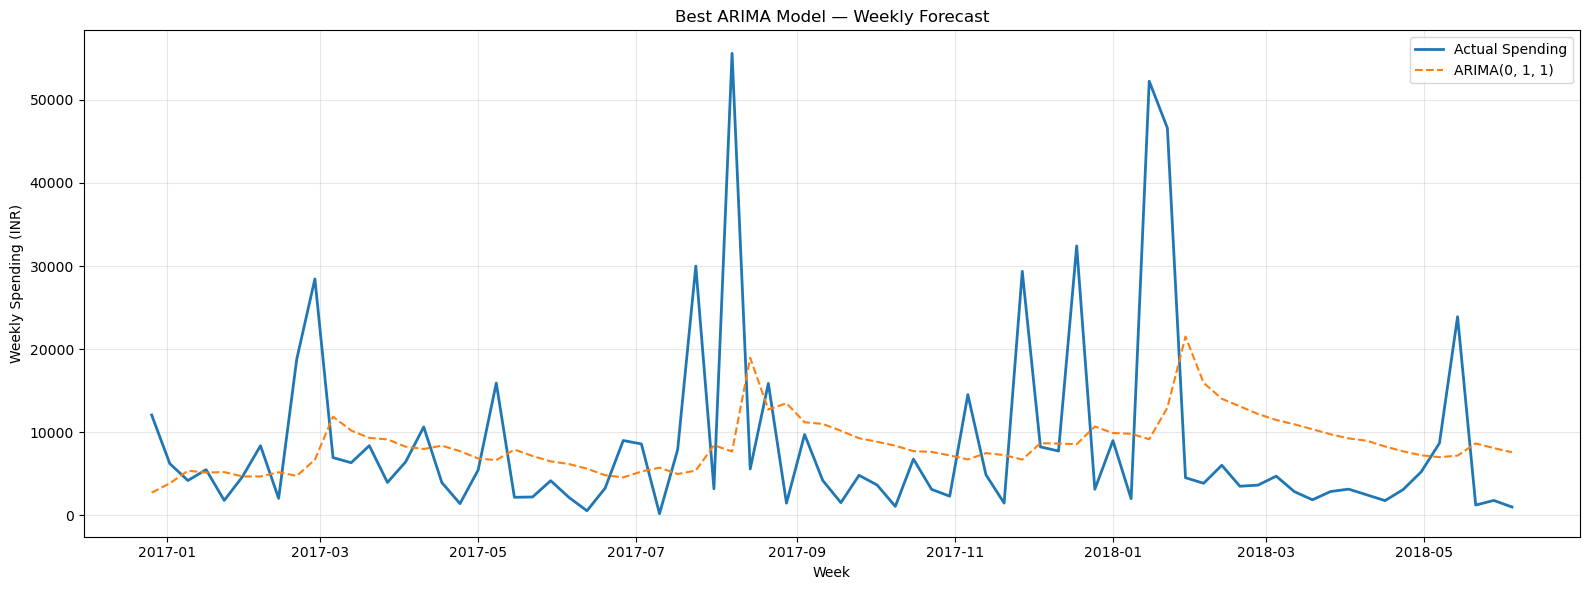


BEST ARIMA MODEL: ARIMA(0, 1, 1)

STEP 10 COMPLETED


In [39]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 10: ARIMA MODEL EXPERIMENTS
# ============================================================

import numpy as np
import pandas as pd
import warnings

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. DEFINE ARIMA CONFIGURATIONS
# ------------------------------------------------------------

arima_orders = [
    (0, 1, 0),
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
    (2, 1, 0),
    (0, 1, 2)
]

# ------------------------------------------------------------
# 2. PREPARE PREDICTION STORAGE
# ------------------------------------------------------------

arima_predictions = pd.DataFrame(
    index=weekly_spending.index[validation_origins]
)

arima_predictions["Actual"] = weekly_spending.iloc[
    validation_origins
].values

for order in arima_orders:
    arima_predictions[f"ARIMA{order}"] = np.nan

# ------------------------------------------------------------
# 3. EXPANDING-WINDOW ARIMA VALIDATION
# ------------------------------------------------------------

for i in validation_origins:

    history = weekly_spending.iloc[:i].astype(float)
    target_week = weekly_spending.index[i]

    for order in arima_orders:

        model_name = f"ARIMA{order}"

        try:
            model = ARIMA(
                history,
                order=order,
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            fitted_model = model.fit()

            forecast = fitted_model.forecast(steps=1).iloc[0]

            # Weekly expenditure cannot be negative.
            forecast = max(0, float(forecast))

            arima_predictions.loc[
                target_week, model_name
            ] = forecast

        except Exception as e:
            print(
                f"Error in {model_name} at {target_week}: {e}"
            )

# ------------------------------------------------------------
# 4. EVALUATE ARIMA MODELS
# ------------------------------------------------------------

arima_metrics = []

for order in arima_orders:

    model_name = f"ARIMA{order}"

    actual = arima_predictions["Actual"]
    predicted = arima_predictions[model_name]

    valid = predicted.notna()

    if valid.sum() == 0:
        continue

    arima_metrics.append({
        "Model": model_name,
        "Valid_Predictions": valid.sum(),
        "MAE": mean_absolute_error(
            actual[valid], predicted[valid]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual[valid], predicted[valid]
            )
        ),
        "Bias": (
            predicted[valid] - actual[valid]
        ).mean()
    })

arima_metrics = pd.DataFrame(
    arima_metrics
).sort_values("MAE").reset_index(drop=True)

print("ARIMA MODEL PERFORMANCE")

display(arima_metrics.round(2))

# ------------------------------------------------------------
# 5. COMPARE ALL EXPERIMENTS SO FAR
# ------------------------------------------------------------

arima_comparison = pd.concat(
    [
        baseline_metrics.assign(
            Model_Group="Baseline"
        ),
        smoothing_metrics.assign(
            Model_Group="Exponential Smoothing"
        ),
        arima_metrics.assign(
            Model_Group="ARIMA"
        )
    ],
    ignore_index=True
)

arima_comparison = arima_comparison.sort_values(
    "MAE"
).reset_index(drop=True)

print("\nOVERALL MODEL RANKING — VALIDATION")

display(arima_comparison.round(2))

# ------------------------------------------------------------
# 6. VISUALIZE BEST ARIMA MODEL
# ------------------------------------------------------------

if not arima_metrics.empty:

    best_arima_model = arima_metrics.iloc[0]["Model"]

    plt.figure(figsize=(16, 6))

    plt.plot(
        arima_predictions.index.to_timestamp(),
        arima_predictions["Actual"],
        label="Actual Spending",
        linewidth=2
    )

    plt.plot(
        arima_predictions.index.to_timestamp(),
        arima_predictions[best_arima_model],
        label=best_arima_model,
        linestyle="--"
    )

    plt.title("Best ARIMA Model — Weekly Forecast")
    plt.xlabel("Week")
    plt.ylabel("Weekly Spending (INR)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("\nBEST ARIMA MODEL:", best_arima_model)

print("\nSTEP 10 COMPLETED")


MACHINE LEARNING MODEL PERFORMANCE


,Model,Valid_Predictions,MAE,RMSE,Bias
0,Gradient_Boosting,76,6658.95,11975.87,-2947.57
1,Extra_Trees,76,7425.87,11792.23,-1137.34
2,Random_Forest,76,7585.34,11784.38,-708.72
3,Ridge,76,7942.63,12479.03,-1452.23



COMPLETE VALIDATION MODEL RANKING


,Model,MAE,RMSE,Bias,Model_Group,Valid_Predictions
0,Rolling_Median_8,6157.41,11520.25,-3384.19,Baseline,NaN
1,Historical_Mean,6365.39,12269.39,-4968.57,Baseline,NaN
2,Rolling_Median_13,6442.82,11863.96,-3574.98,Baseline,NaN
3,Gradient_Boosting,6658.95,11975.87,-2947.57,Machine Learning,76.0
4,Rolling_Median_4,7236.38,12555.41,-1757.43,Baseline,NaN
5,Extra_Trees,7425.87,11792.23,-1137.34,Machine Learning,76.0
6,Random_Forest,7585.34,11784.38,-708.72,Machine Learning,76.0
7,Seasonal_Naive,7796.64,13172.50,-5111.86,Baseline,NaN
8,SES,7834.01,11763.91,3.34,Exponential Smoothing,76.0
9,"ARIMA(0, 1, 1)",7861.55,11744.89,-13.56,ARIMA,76.0



BEST ML MODEL: Gradient_Boosting


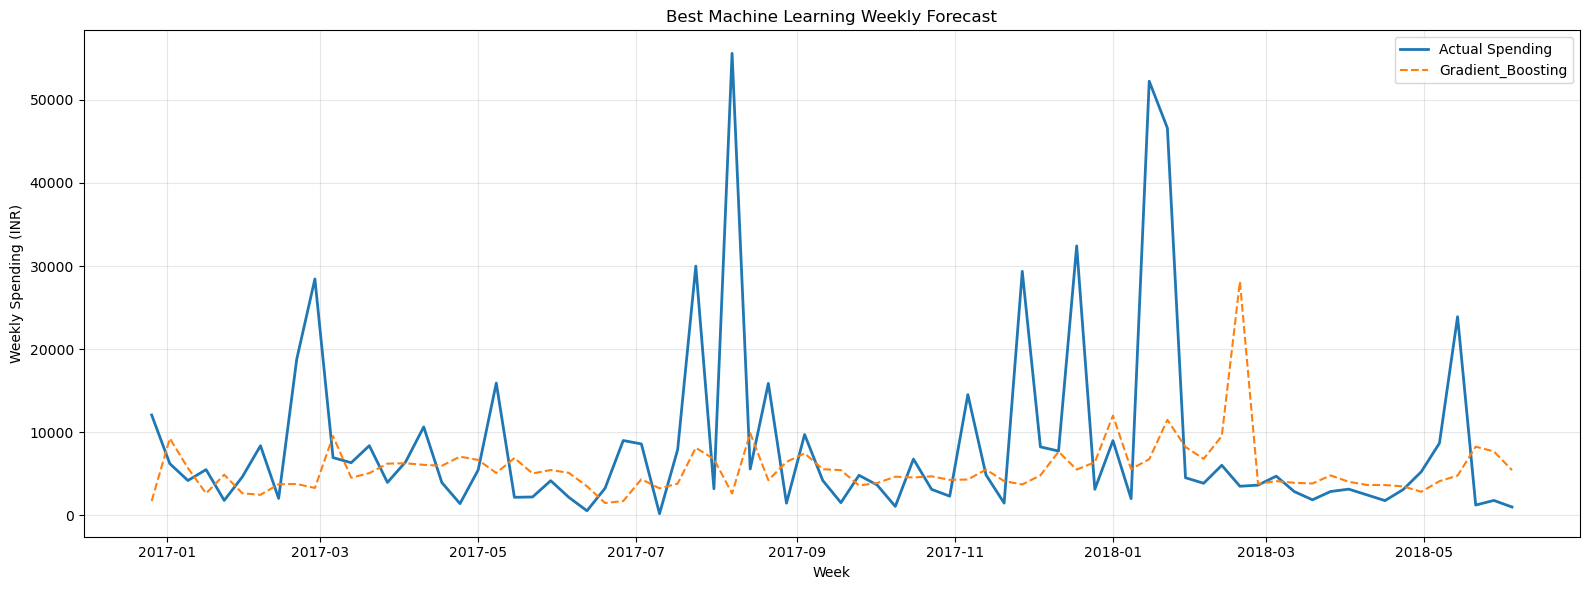


STEP 11 COMPLETED


In [40]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 11: MACHINE LEARNING FORECASTING
# ============================================================

import numpy as np
import pandas as pd
import warnings

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. FEATURE ENGINEERING FUNCTION
# ------------------------------------------------------------

def create_weekly_features(series):

    data = pd.DataFrame(index=series.index)
    data["Target"] = series.astype(float)

    # Previous-week spending
    for lag in [1, 2, 3, 4, 8, 13]:
        data[f"Lag_{lag}"] = series.shift(lag)

    # Rolling statistics use only earlier weeks
    shifted = series.shift(1)

    for window in [4, 8, 13]:
        data[f"Rolling_Mean_{window}"] = (
            shifted.rolling(window).mean()
        )

        data[f"Rolling_Median_{window}"] = (
            shifted.rolling(window).median()
        )

        data[f"Rolling_Std_{window}"] = (
            shifted.rolling(window).std()
        )

    return data.dropna()


# ------------------------------------------------------------
# 2. DEFINE MACHINE LEARNING MODELS
# ------------------------------------------------------------

ml_models = {
    "Ridge": make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    ),

    "Random_Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=3,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "Extra_Trees": ExtraTreesRegressor(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=3,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient_Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=3,
        loss="huber",
        random_state=42
    )
}

# ------------------------------------------------------------
# 3. PREPARE PREDICTION STORAGE
# ------------------------------------------------------------

ml_predictions = pd.DataFrame(
    index=weekly_spending.index[validation_origins]
)

ml_predictions["Actual"] = weekly_spending.iloc[
    validation_origins
].values

for model_name in ml_models:
    ml_predictions[model_name] = np.nan

# ------------------------------------------------------------
# 4. EXPANDING-WINDOW VALIDATION
# ------------------------------------------------------------

for i in validation_origins:

    history = weekly_spending.iloc[:i].astype(float)
    target_week = weekly_spending.index[i]

    # Create training examples from historical data only
    supervised_data = create_weekly_features(history)

    X_train = supervised_data.drop(columns=["Target"])
    y_train = supervised_data["Target"]

    # Features for the next week
    latest_features = pd.DataFrame(
        [history.iloc[-lag] for lag in [1, 2, 3, 4, 8, 13]],
        index=[
            "Lag_1", "Lag_2", "Lag_3",
            "Lag_4", "Lag_8", "Lag_13"
        ]
    ).T

    shifted_history = history

    for window in [4, 8, 13]:

        recent = shifted_history.iloc[-window:]

        latest_features[f"Rolling_Mean_{window}"] = recent.mean()
        latest_features[f"Rolling_Median_{window}"] = recent.median()
        latest_features[f"Rolling_Std_{window}"] = recent.std()

    # Fit and predict each model
    for model_name, model in ml_models.items():

        try:
            model.fit(X_train, y_train)

            prediction = model.predict(
                latest_features[X_train.columns]
            )[0]

            ml_predictions.loc[
                target_week, model_name
            ] = max(0, float(prediction))

        except Exception as e:
            print(
                f"{model_name} error at {target_week}: {e}"
            )

# ------------------------------------------------------------
# 5. EVALUATE MACHINE LEARNING MODELS
# ------------------------------------------------------------

ml_metrics = []

for model_name in ml_models:

    actual = ml_predictions["Actual"]
    predicted = ml_predictions[model_name]

    valid = predicted.notna()

    if valid.sum() == 0:
        continue

    ml_metrics.append({
        "Model": model_name,
        "Valid_Predictions": valid.sum(),
        "MAE": mean_absolute_error(
            actual[valid], predicted[valid]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual[valid], predicted[valid]
            )
        ),
        "Bias": (
            predicted[valid] - actual[valid]
        ).mean()
    })

ml_metrics = pd.DataFrame(
    ml_metrics
).sort_values("MAE").reset_index(drop=True)

print("MACHINE LEARNING MODEL PERFORMANCE")

display(ml_metrics.round(2))

# ------------------------------------------------------------
# 6. COMPARE ALL MODELS SO FAR
# ------------------------------------------------------------

all_model_results = pd.concat(
    [
        baseline_metrics.assign(Model_Group="Baseline"),
        smoothing_metrics.assign(Model_Group="Exponential Smoothing"),
        arima_metrics.assign(Model_Group="ARIMA"),
        ml_metrics.assign(Model_Group="Machine Learning")
    ],
    ignore_index=True
)

all_model_results = all_model_results.sort_values(
    "MAE"
).reset_index(drop=True)

print("\nCOMPLETE VALIDATION MODEL RANKING")

display(all_model_results.round(2))

# ------------------------------------------------------------
# 7. BEST MACHINE LEARNING MODEL
# ------------------------------------------------------------

if not ml_metrics.empty:

    best_ml_model = ml_metrics.iloc[0]["Model"]

    print("\nBEST ML MODEL:", best_ml_model)

    plt.figure(figsize=(16, 6))

    plt.plot(
        ml_predictions.index.to_timestamp(),
        ml_predictions["Actual"],
        label="Actual Spending",
        linewidth=2
    )

    plt.plot(
        ml_predictions.index.to_timestamp(),
        ml_predictions[best_ml_model],
        label=best_ml_model,
        linestyle="--"
    )

    plt.title("Best Machine Learning Weekly Forecast")
    plt.xlabel("Week")
    plt.ylabel("Weekly Spending (INR)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

print("\nSTEP 11 COMPLETED")


MACHINE LEARNING MODEL PERFORMANCE


,Model,Valid_Predictions,MAE,RMSE,Bias
0,Gradient_Boosting,76,6658.95,11975.87,-2947.57
1,Extra_Trees,76,7425.87,11792.23,-1137.34
2,Random_Forest,76,7585.34,11784.38,-708.72
3,Ridge,76,7942.63,12479.03,-1452.23



COMPLETE VALIDATION MODEL RANKING


,Model,MAE,RMSE,Bias,Model_Group,Valid_Predictions
0,Rolling_Median_8,6157.41,11520.25,-3384.19,Baseline,NaN
1,Historical_Mean,6365.39,12269.39,-4968.57,Baseline,NaN
2,Rolling_Median_13,6442.82,11863.96,-3574.98,Baseline,NaN
3,Gradient_Boosting,6658.95,11975.87,-2947.57,Machine Learning,76.0
4,Rolling_Median_4,7236.38,12555.41,-1757.43,Baseline,NaN
5,Extra_Trees,7425.87,11792.23,-1137.34,Machine Learning,76.0
6,Random_Forest,7585.34,11784.38,-708.72,Machine Learning,76.0
7,Seasonal_Naive,7796.64,13172.50,-5111.86,Baseline,NaN
8,SES,7834.01,11763.91,3.34,Exponential Smoothing,76.0
9,"ARIMA(0, 1, 1)",7861.55,11744.89,-13.56,ARIMA,76.0



BEST ML MODEL: Gradient_Boosting


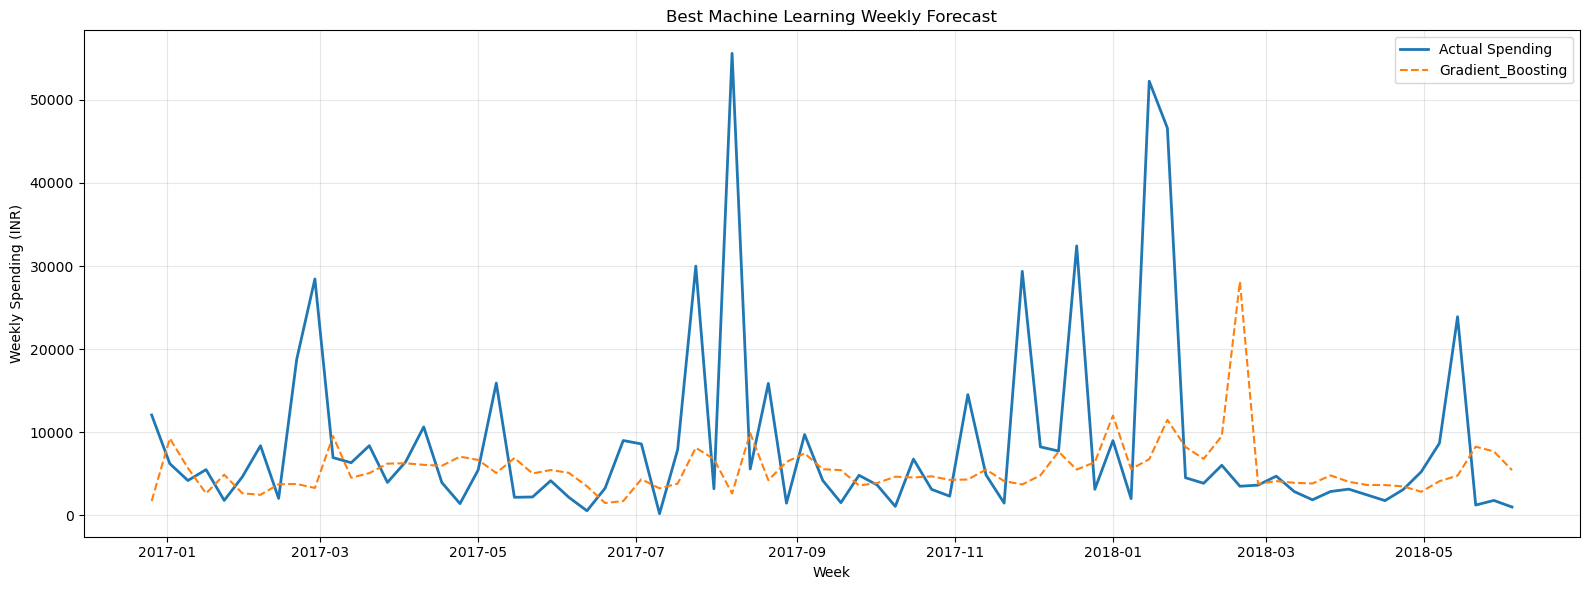


STEP 11 COMPLETED


In [41]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 11: MACHINE LEARNING FORECASTING
# ============================================================

import numpy as np
import pandas as pd
import warnings

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. FEATURE ENGINEERING FUNCTION
# ------------------------------------------------------------

def create_weekly_features(series):

    data = pd.DataFrame(index=series.index)
    data["Target"] = series.astype(float)

    # Previous-week spending
    for lag in [1, 2, 3, 4, 8, 13]:
        data[f"Lag_{lag}"] = series.shift(lag)

    # Rolling statistics use only earlier weeks
    shifted = series.shift(1)

    for window in [4, 8, 13]:
        data[f"Rolling_Mean_{window}"] = (
            shifted.rolling(window).mean()
        )

        data[f"Rolling_Median_{window}"] = (
            shifted.rolling(window).median()
        )

        data[f"Rolling_Std_{window}"] = (
            shifted.rolling(window).std()
        )

    return data.dropna()


# ------------------------------------------------------------
# 2. DEFINE MACHINE LEARNING MODELS
# ------------------------------------------------------------

ml_models = {
    "Ridge": make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    ),

    "Random_Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=3,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "Extra_Trees": ExtraTreesRegressor(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=3,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient_Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=3,
        loss="huber",
        random_state=42
    )
}

# ------------------------------------------------------------
# 3. PREPARE PREDICTION STORAGE
# ------------------------------------------------------------

ml_predictions = pd.DataFrame(
    index=weekly_spending.index[validation_origins]
)

ml_predictions["Actual"] = weekly_spending.iloc[
    validation_origins
].values

for model_name in ml_models:
    ml_predictions[model_name] = np.nan

# ------------------------------------------------------------
# 4. EXPANDING-WINDOW VALIDATION
# ------------------------------------------------------------

for i in validation_origins:

    history = weekly_spending.iloc[:i].astype(float)
    target_week = weekly_spending.index[i]

    # Create training examples from historical data only
    supervised_data = create_weekly_features(history)

    X_train = supervised_data.drop(columns=["Target"])
    y_train = supervised_data["Target"]

    # Features for the next week
    latest_features = pd.DataFrame(
        [history.iloc[-lag] for lag in [1, 2, 3, 4, 8, 13]],
        index=[
            "Lag_1", "Lag_2", "Lag_3",
            "Lag_4", "Lag_8", "Lag_13"
        ]
    ).T

    shifted_history = history

    for window in [4, 8, 13]:

        recent = shifted_history.iloc[-window:]

        latest_features[f"Rolling_Mean_{window}"] = recent.mean()
        latest_features[f"Rolling_Median_{window}"] = recent.median()
        latest_features[f"Rolling_Std_{window}"] = recent.std()

    # Fit and predict each model
    for model_name, model in ml_models.items():

        try:
            model.fit(X_train, y_train)

            prediction = model.predict(
                latest_features[X_train.columns]
            )[0]

            ml_predictions.loc[
                target_week, model_name
            ] = max(0, float(prediction))

        except Exception as e:
            print(
                f"{model_name} error at {target_week}: {e}"
            )

# ------------------------------------------------------------
# 5. EVALUATE MACHINE LEARNING MODELS
# ------------------------------------------------------------

ml_metrics = []

for model_name in ml_models:

    actual = ml_predictions["Actual"]
    predicted = ml_predictions[model_name]

    valid = predicted.notna()

    if valid.sum() == 0:
        continue

    ml_metrics.append({
        "Model": model_name,
        "Valid_Predictions": valid.sum(),
        "MAE": mean_absolute_error(
            actual[valid], predicted[valid]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual[valid], predicted[valid]
            )
        ),
        "Bias": (
            predicted[valid] - actual[valid]
        ).mean()
    })

ml_metrics = pd.DataFrame(
    ml_metrics
).sort_values("MAE").reset_index(drop=True)

print("MACHINE LEARNING MODEL PERFORMANCE")

display(ml_metrics.round(2))

# ------------------------------------------------------------
# 6. COMPARE ALL MODELS SO FAR
# ------------------------------------------------------------

all_model_results = pd.concat(
    [
        baseline_metrics.assign(Model_Group="Baseline"),
        smoothing_metrics.assign(Model_Group="Exponential Smoothing"),
        arima_metrics.assign(Model_Group="ARIMA"),
        ml_metrics.assign(Model_Group="Machine Learning")
    ],
    ignore_index=True
)

all_model_results = all_model_results.sort_values(
    "MAE"
).reset_index(drop=True)

print("\nCOMPLETE VALIDATION MODEL RANKING")

display(all_model_results.round(2))

# ------------------------------------------------------------
# 7. BEST MACHINE LEARNING MODEL
# ------------------------------------------------------------

if not ml_metrics.empty:

    best_ml_model = ml_metrics.iloc[0]["Model"]

    print("\nBEST ML MODEL:", best_ml_model)

    plt.figure(figsize=(16, 6))

    plt.plot(
        ml_predictions.index.to_timestamp(),
        ml_predictions["Actual"],
        label="Actual Spending",
        linewidth=2
    )

    plt.plot(
        ml_predictions.index.to_timestamp(),
        ml_predictions[best_ml_model],
        label=best_ml_model,
        linestyle="--"
    )

    plt.title("Best Machine Learning Weekly Forecast")
    plt.xlabel("Week")
    plt.ylabel("Weekly Spending (INR)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

print("\nSTEP 11 COMPLETED")


In [42]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 12: HYPERPARAMETER TUNING
# ============================================================

import numpy as np
import pandas as pd
import warnings

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. DEFINE GRADIENT BOOSTING CONFIGURATIONS
# ------------------------------------------------------------

gb_configs = [
    {
        "n_estimators": 100,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_samples_leaf": 3,
        "loss": "huber"
    },
    {
        "n_estimators": 200,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_samples_leaf": 3,
        "loss": "huber"
    },
    {
        "n_estimators": 100,
        "learning_rate": 0.05,
        "max_depth": 2,
        "min_samples_leaf": 3,
        "loss": "huber"
    },
    {
        "n_estimators": 200,
        "learning_rate": 0.05,
        "max_depth": 2,
        "min_samples_leaf": 3,
        "loss": "huber"
    },
    {
        "n_estimators": 100,
        "learning_rate": 0.03,
        "max_depth": 1,
        "min_samples_leaf": 3,
        "loss": "huber"
    },
    {
        "n_estimators": 100,
        "learning_rate": 0.03,
        "max_depth": 3,
        "min_samples_leaf": 3,
        "loss": "huber"
    },
    {
        "n_estimators": 100,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_samples_leaf": 5,
        "loss": "huber"
    },
    {
        "n_estimators": 100,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_samples_leaf": 3,
        "loss": "absolute_error"
    },
    {
        "n_estimators": 100,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_samples_leaf": 3,
        "loss": "squared_error"
    },
    {
        "n_estimators": 200,
        "learning_rate": 0.01,
        "max_depth": 2,
        "min_samples_leaf": 5,
        "loss": "huber"
    }
]

# ------------------------------------------------------------
# 2. TUNE GRADIENT BOOSTING
# ------------------------------------------------------------

gb_tuning_results = []

for config_number, config in enumerate(gb_configs, start=1):

    predictions = []
    actual_values = []

    for i in validation_origins:

        history = weekly_spending.iloc[:i].astype(float)

        supervised_data = create_weekly_features(history)

        X_train = supervised_data.drop(columns=["Target"])
        y_train = supervised_data["Target"]

        # Construct next-week features
        latest = {}

        for lag in [1, 2, 3, 4, 8, 13]:
            latest[f"Lag_{lag}"] = history.iloc[-lag]

        shifted = history

        for window in [4, 8, 13]:
            recent = shifted.iloc[-window:]

            latest[f"Rolling_Mean_{window}"] = recent.mean()
            latest[f"Rolling_Median_{window}"] = recent.median()
            latest[f"Rolling_Std_{window}"] = recent.std()

        X_next = pd.DataFrame([latest])[X_train.columns]

        model = GradientBoostingRegressor(
            **config,
            random_state=42
        )

        model.fit(X_train, y_train)

        prediction = model.predict(X_next)[0]

        predictions.append(max(0, float(prediction)))
        actual_values.append(weekly_spending.iloc[i])

    gb_tuning_results.append({
        "Configuration": config_number,
        "MAE": mean_absolute_error(
            actual_values, predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(actual_values, predictions)
        ),
        "Parameters": str(config)
    })

gb_tuning_results = pd.DataFrame(
    gb_tuning_results
).sort_values("MAE").reset_index(drop=True)

print("GRADIENT BOOSTING TUNING RESULTS")

display(gb_tuning_results.round(2))

# ------------------------------------------------------------
# 3. TUNE ROLLING MEDIAN WINDOW
# ------------------------------------------------------------

median_window_results = []

for window in range(2, 27):

    predictions = []
    actual_values = []

    for i in validation_origins:

        history = weekly_spending.iloc[:i]

        prediction = history.iloc[-window:].median()

        predictions.append(prediction)
        actual_values.append(weekly_spending.iloc[i])

    median_window_results.append({
        "Window": window,
        "MAE": mean_absolute_error(
            actual_values, predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(actual_values, predictions)
        )
    })

median_window_results = pd.DataFrame(
    median_window_results
).sort_values("MAE").reset_index(drop=True)

print("\nROLLING MEDIAN WINDOW TUNING RESULTS")

display(median_window_results.round(2))

# ------------------------------------------------------------
# 4. IDENTIFY BEST CONFIGURATIONS
# ------------------------------------------------------------

best_gb_config_number = int(
    gb_tuning_results.iloc[0]["Configuration"]
)

best_gb_config = gb_configs[
    best_gb_config_number - 1
]

best_median_window = int(
    median_window_results.iloc[0]["Window"]
)

print("\nBEST GRADIENT BOOSTING CONFIGURATION:")
print(best_gb_config)

print("\nBEST ROLLING MEDIAN WINDOW:", best_median_window)

# ------------------------------------------------------------
# 5. COMBINED COMPARISON
# ------------------------------------------------------------

tuning_leaderboard = pd.DataFrame([
    {
        "Model": "Previous Best: Rolling Median 8",
        "MAE": 6157.41,
        "RMSE": 11520.25
    },
    {
        "Model": "Previous Gradient Boosting",
        "MAE": 6658.95,
        "RMSE": 11975.87
    },
    {
        "Model": f"Tuned Rolling Median {best_median_window}",
        "MAE": median_window_results.iloc[0]["MAE"],
        "RMSE": median_window_results.iloc[0]["RMSE"]
    },
    {
        "Model": f"Tuned Gradient Boosting Config {best_gb_config_number}",
        "MAE": gb_tuning_results.iloc[0]["MAE"],
        "RMSE": gb_tuning_results.iloc[0]["RMSE"]
    }
]).sort_values("MAE").reset_index(drop=True)

print("\nTUNING LEADERBOARD")

display(tuning_leaderboard.round(2))

print("\nSTEP 12 COMPLETED")


GRADIENT BOOSTING TUNING RESULTS


,Configuration,MAE,RMSE,Parameters
0,5,6391.54,11933.50,"{'n_estimators': 100, 'learning_rate': 0.03, '..."
1,8,6410.98,12300.33,"{'n_estimators': 100, 'learning_rate': 0.03, '..."
2,10,6452.60,12036.73,"{'n_estimators': 200, 'learning_rate': 0.01, '..."
3,7,6481.00,11961.87,"{'n_estimators': 100, 'learning_rate': 0.03, '..."
4,1,6658.95,11975.87,"{'n_estimators': 100, 'learning_rate': 0.03, '..."
5,6,6742.54,12157.20,"{'n_estimators': 100, 'learning_rate': 0.03, '..."
6,2,6754.72,11891.73,"{'n_estimators': 200, 'learning_rate': 0.03, '..."
7,3,6819.95,12117.39,"{'n_estimators': 100, 'learning_rate': 0.05, '..."
8,4,7146.72,12335.89,"{'n_estimators': 200, 'learning_rate': 0.05, '..."
9,9,7896.80,12376.23,"{'n_estimators': 100, 'learning_rate': 0.03, '..."



ROLLING MEDIAN WINDOW TUNING RESULTS


,Window,MAE,RMSE
0,7,6117.43,11406.45
1,8,6157.41,11520.25
2,9,6188.80,11675.95
3,10,6228.81,11714.21
4,21,6249.90,11953.71
5,6,6258.23,11466.02
6,5,6260.48,11386.64
7,24,6263.76,11845.90
8,11,6285.94,11765.54
9,22,6288.73,11907.93



BEST GRADIENT BOOSTING CONFIGURATION:
{'n_estimators': 100, 'learning_rate': 0.03, 'max_depth': 1, 'min_samples_leaf': 3, 'loss': 'huber'}

BEST ROLLING MEDIAN WINDOW: 7

TUNING LEADERBOARD


,Model,MAE,RMSE
0,Tuned Rolling Median 7,6117.43,11406.45
1,Previous Best: Rolling Median 8,6157.41,11520.25
2,Tuned Gradient Boosting Config 5,6391.54,11933.50
3,Previous Gradient Boosting,6658.95,11975.87



STEP 12 COMPLETED


ADVANCED FORECASTING RESULTS


,Model,Valid_Predictions,MAE,RMSE,Bias
0,Croston_SBA_0.2,76,7294.40,11556.69,-886.63
1,Croston_SBA_0.1,76,7329.84,11512.53,-805.45
2,Croston_0.1,76,7536.60,11524.55,-398.12
3,TSB_0.1,76,7536.78,11524.26,-395.86
4,Croston_0.2,76,7731.24,11633.47,-35.72
5,TSB_0.2,76,7731.45,11633.32,-34.11
6,Theta,76,7963.83,11754.44,233.36



ADVANCED MODEL LEADERBOARD


,Model,MAE,RMSE
0,Rolling Median 7,6117.43,11406.45
1,Tuned Gradient Boosting,6391.54,11933.50
2,Croston_SBA_0.2,7294.40,11556.69
3,Croston_SBA_0.1,7329.84,11512.53
4,Croston_0.1,7536.60,11524.55
5,TSB_0.1,7536.78,11524.26
6,Croston_0.2,7731.24,11633.47
7,TSB_0.2,7731.45,11633.32
8,Theta,7963.83,11754.44


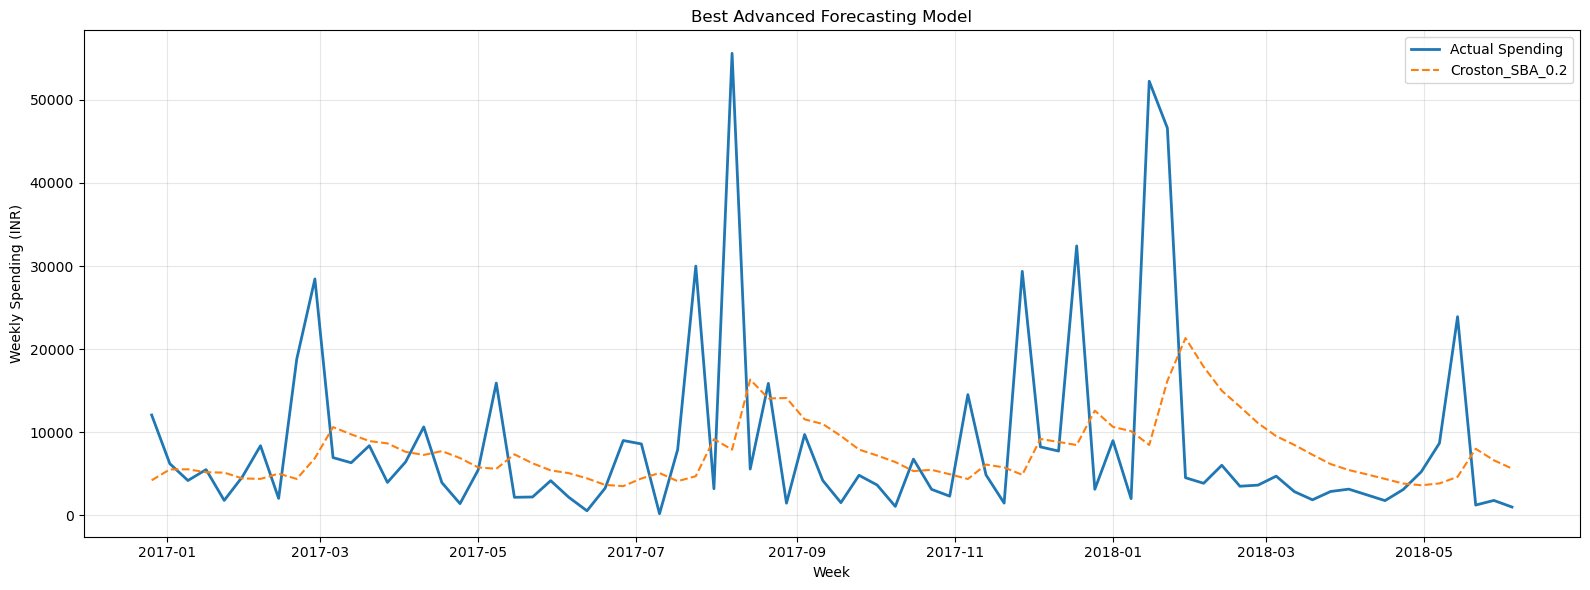

BEST ADVANCED MODEL: Croston_SBA_0.2

STEP 13 COMPLETED


In [43]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 13: ADVANCED FORECASTING EXPERIMENTS
# ============================================================

import numpy as np
import pandas as pd
import warnings

from statsmodels.tsa.forecasting.theta import ThetaModel
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. CROSTON FORECASTING FUNCTION
# ------------------------------------------------------------

def croston_forecast(series, alpha=0.1, sba=False):

    values = np.asarray(series, dtype=float)

    nonzero_positions = np.where(values > 0)[0]

    if len(nonzero_positions) == 0:
        return 0.0

    first_position = nonzero_positions[0]

    demand_size = values[first_position]
    interval = first_position + 1

    previous_position = first_position

    for position in nonzero_positions[1:]:

        demand = values[position]
        gap = position - previous_position

        demand_size = (
            alpha * demand
            + (1 - alpha) * demand_size
        )

        interval = (
            alpha * gap
            + (1 - alpha) * interval
        )

        previous_position = position

    forecast = demand_size / interval

    if sba:
        forecast *= (1 - alpha / 2)

    return max(0.0, float(forecast))


# ------------------------------------------------------------
# 2. TSB FORECASTING FUNCTION
# ------------------------------------------------------------

def tsb_forecast(series, alpha=0.1, beta=0.1):

    values = np.asarray(series, dtype=float)

    if len(values) == 0:
        return 0.0

    probability = np.mean(values > 0)

    nonzero_values = values[values > 0]

    if len(nonzero_values) == 0:
        return 0.0

    demand_size = nonzero_values[0]

    for value in values:

        occurrence = 1.0 if value > 0 else 0.0

        probability = (
            beta * occurrence
            + (1 - beta) * probability
        )

        if value > 0:
            demand_size = (
                alpha * value
                + (1 - alpha) * demand_size
            )

    return max(0.0, float(probability * demand_size))


# ------------------------------------------------------------
# 3. DEFINE EXPERIMENTS
# ------------------------------------------------------------

advanced_predictions = pd.DataFrame(
    index=weekly_spending.index[validation_origins]
)

advanced_predictions["Actual"] = weekly_spending.iloc[
    validation_origins
].values

model_names = [
    "Theta",
    "Croston_0.1",
    "Croston_0.2",
    "Croston_SBA_0.1",
    "Croston_SBA_0.2",
    "TSB_0.1",
    "TSB_0.2"
]

for model_name in model_names:
    advanced_predictions[model_name] = np.nan


# ------------------------------------------------------------
# 4. EXPANDING-WINDOW VALIDATION
# ------------------------------------------------------------

for i in validation_origins:

    history = weekly_spending.iloc[:i].astype(float)
    target_week = weekly_spending.index[i]

    # THETA MODEL
    try:

        theta_model = ThetaModel(
            history,
            period=1
        ).fit()

        theta_prediction = theta_model.forecast(1).iloc[0]

        advanced_predictions.loc[
            target_week, "Theta"
        ] = max(0.0, float(theta_prediction))

    except Exception as e:

        print("Theta error:", target_week, e)

    # CROSTON, SBA AND TSB
    advanced_predictions.loc[
        target_week, "Croston_0.1"
    ] = croston_forecast(history, alpha=0.1)

    advanced_predictions.loc[
        target_week, "Croston_0.2"
    ] = croston_forecast(history, alpha=0.2)

    advanced_predictions.loc[
        target_week, "Croston_SBA_0.1"
    ] = croston_forecast(
        history, alpha=0.1, sba=True
    )

    advanced_predictions.loc[
        target_week, "Croston_SBA_0.2"
    ] = croston_forecast(
        history, alpha=0.2, sba=True
    )

    advanced_predictions.loc[
        target_week, "TSB_0.1"
    ] = tsb_forecast(
        history, alpha=0.1, beta=0.1
    )

    advanced_predictions.loc[
        target_week, "TSB_0.2"
    ] = tsb_forecast(
        history, alpha=0.2, beta=0.2
    )


# ------------------------------------------------------------
# 5. EVALUATE ADVANCED MODELS
# ------------------------------------------------------------

advanced_metrics = []

for model_name in model_names:

    actual = advanced_predictions["Actual"]
    predicted = advanced_predictions[model_name]

    valid = predicted.notna()

    if valid.sum() == 0:
        continue

    advanced_metrics.append({
        "Model": model_name,
        "Valid_Predictions": valid.sum(),
        "MAE": mean_absolute_error(
            actual[valid], predicted[valid]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual[valid], predicted[valid]
            )
        ),
        "Bias": (
            predicted[valid] - actual[valid]
        ).mean()
    })

advanced_metrics = pd.DataFrame(
    advanced_metrics
).sort_values("MAE").reset_index(drop=True)

print("ADVANCED FORECASTING RESULTS")

display(advanced_metrics.round(2))


# ------------------------------------------------------------
# 6. COMPARE WITH PREVIOUS BEST MODELS
# ------------------------------------------------------------

advanced_leaderboard = pd.DataFrame([
    {
        "Model": "Rolling Median 7",
        "MAE": 6117.43,
        "RMSE": 11406.45
    },
    {
        "Model": "Tuned Gradient Boosting",
        "MAE": 6391.54,
        "RMSE": 11933.50
    }
])

advanced_leaderboard = pd.concat(
    [
        advanced_leaderboard,
        advanced_metrics[["Model", "MAE", "RMSE"]]
    ],
    ignore_index=True
).sort_values("MAE").reset_index(drop=True)

print("\nADVANCED MODEL LEADERBOARD")

display(advanced_leaderboard.round(2))


# ------------------------------------------------------------
# 7. VISUALIZE THE BEST ADVANCED MODEL
# ------------------------------------------------------------

if not advanced_metrics.empty:

    best_advanced_model = advanced_metrics.iloc[0]["Model"]

    plt.figure(figsize=(16, 6))

    plt.plot(
        advanced_predictions.index.to_timestamp(),
        advanced_predictions["Actual"],
        label="Actual Spending",
        linewidth=2
    )

    plt.plot(
        advanced_predictions.index.to_timestamp(),
        advanced_predictions[best_advanced_model],
        label=best_advanced_model,
        linestyle="--"
    )

    plt.title("Best Advanced Forecasting Model")
    plt.xlabel("Week")
    plt.ylabel("Weekly Spending (INR)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("BEST ADVANCED MODEL:", best_advanced_model)


print("\nSTEP 13 COMPLETED")


ROBUST AND TRANSFORMED MODEL RESULTS


,Model,Valid_Predictions,MAE,RMSE,Bias
0,Log_Median_7,76,6117.43,11406.45,-3365.44
1,Winsorized_Median_7_98,76,6117.43,11406.45,-3365.44
2,Winsorized_Median_7_95,76,6117.43,11406.45,-3365.44
3,Log_Mean_7,76,6350.73,11678.98,-3165.46
4,Log_Median_13,76,6442.82,11863.96,-3574.98
5,Winsorized_Median_13_95,76,6442.82,11863.96,-3574.98
6,Winsorized_Median_13_98,76,6442.82,11863.96,-3574.98
7,Log_ARIMA_011,76,6478.76,11924.44,-3841.93
8,Log_SES,76,6503.22,11948.88,-3908.15
9,Log_Mean_13,76,6677.72,11992.76,-3522.93



OVERALL ROBUST MODEL COMPARISON


,Model,MAE,RMSE
0,Winsorized_Median_7_98,6117.43,11406.45
1,Log_Median_7,6117.43,11406.45
2,Winsorized_Median_7_95,6117.43,11406.45
3,Rolling Median 7,6117.43,11406.45
4,Log_Mean_7,6350.73,11678.98
5,Tuned Gradient Boosting,6391.54,11933.50
6,Log_Median_13,6442.82,11863.96
7,Winsorized_Median_13_95,6442.82,11863.96
8,Winsorized_Median_13_98,6442.82,11863.96
9,Log_ARIMA_011,6478.76,11924.44



BEST ROBUST MODEL: Log_Median_7


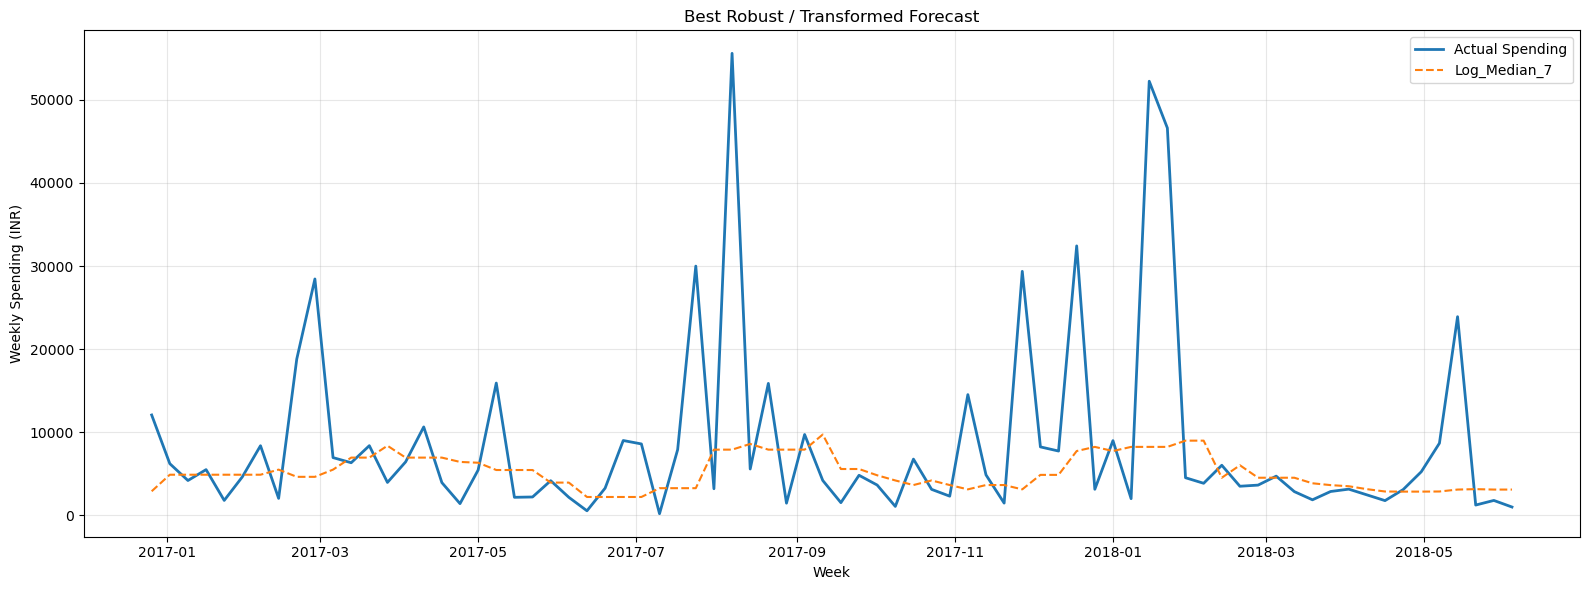


STEP 14 COMPLETED


In [44]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 14: ROBUST AND LOG-TRANSFORMED FORECASTING
# ============================================================

import numpy as np
import pandas as pd
import warnings

from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. PREPARE PREDICTION STORAGE
# ------------------------------------------------------------

robust_predictions = pd.DataFrame(
    index=weekly_spending.index[validation_origins]
)

robust_predictions["Actual"] = weekly_spending.iloc[
    validation_origins
].values

robust_model_names = [
    "Log_Median_7",
    "Log_Median_13",
    "Log_Mean_7",
    "Log_Mean_13",
    "Log_SES",
    "Log_ARIMA_011",
    "Winsorized_Median_7_95",
    "Winsorized_Median_7_98",
    "Winsorized_Median_13_95",
    "Winsorized_Median_13_98"
]

for name in robust_model_names:
    robust_predictions[name] = np.nan


# ------------------------------------------------------------
# 2. EXPANDING-WINDOW VALIDATION
# ------------------------------------------------------------

for i in validation_origins:

    history = weekly_spending.iloc[:i].astype(float)
    target_week = weekly_spending.index[i]

    # LOG TRANSFORMATION
    log_history = np.log1p(history)

    # LOG MEDIAN AND MEAN
    log_median_7 = np.expm1(
        log_history.iloc[-7:].median()
    )

    log_median_13 = np.expm1(
        log_history.iloc[-13:].median()
    )

    log_mean_7 = np.expm1(
        log_history.iloc[-7:].mean()
    )

    log_mean_13 = np.expm1(
        log_history.iloc[-13:].mean()
    )

    robust_predictions.loc[
        target_week, "Log_Median_7"
    ] = max(0, log_median_7)

    robust_predictions.loc[
        target_week, "Log_Median_13"
    ] = max(0, log_median_13)

    robust_predictions.loc[
        target_week, "Log_Mean_7"
    ] = max(0, log_mean_7)

    robust_predictions.loc[
        target_week, "Log_Mean_13"
    ] = max(0, log_mean_13)

    # LOG SIMPLE EXPONENTIAL SMOOTHING
    try:

        ses_model = SimpleExpSmoothing(
            log_history,
            initialization_method="estimated"
        ).fit(optimized=True)

        prediction = ses_model.forecast(1).iloc[0]

        robust_predictions.loc[
            target_week, "Log_SES"
        ] = max(0, float(np.expm1(prediction)))

    except Exception as e:
        print("Log SES error:", target_week, e)

    # LOG ARIMA (0,1,1)
    try:

        arima_model = ARIMA(
            log_history,
            order=(0, 1, 1),
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit()

        prediction = arima_model.forecast(1).iloc[0]

        robust_predictions.loc[
            target_week, "Log_ARIMA_011"
        ] = max(0, float(np.expm1(prediction)))

    except Exception as e:
        print("Log ARIMA error:", target_week, e)

    # WINSORIZED HISTORICAL DATA
    # Actual validation targets remain unchanged.
    for percentile in [0.95, 0.98]:

        cap = history.quantile(percentile)

        winsorized_history = history.clip(upper=cap)

        for window in [7, 13]:

            prediction = winsorized_history.iloc[
                -window:
            ].median()

            model_name = (
                f"Winsorized_Median_{window}_"
                f"{int(percentile * 100)}"
            )

            robust_predictions.loc[
                target_week, model_name
            ] = max(0, float(prediction))


# ------------------------------------------------------------
# 3. EVALUATE ROBUST MODELS
# ------------------------------------------------------------

robust_metrics = []

for model_name in robust_model_names:

    actual = robust_predictions["Actual"]
    predicted = robust_predictions[model_name]

    valid = predicted.notna()

    if valid.sum() == 0:
        continue

    robust_metrics.append({
        "Model": model_name,
        "Valid_Predictions": valid.sum(),
        "MAE": mean_absolute_error(
            actual[valid], predicted[valid]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual[valid], predicted[valid]
            )
        ),
        "Bias": (
            predicted[valid] - actual[valid]
        ).mean()
    })

robust_metrics = pd.DataFrame(
    robust_metrics
).sort_values("MAE").reset_index(drop=True)

print("ROBUST AND TRANSFORMED MODEL RESULTS")

display(robust_metrics.round(2))


# ------------------------------------------------------------
# 4. COMPARE WITH CURRENT BEST MODELS
# ------------------------------------------------------------

robust_leaderboard = pd.DataFrame([
    {
        "Model": "Rolling Median 7",
        "MAE": 6117.43,
        "RMSE": 11406.45
    },
    {
        "Model": "Tuned Gradient Boosting",
        "MAE": 6391.54,
        "RMSE": 11933.50
    }
])

robust_leaderboard = pd.concat(
    [
        robust_leaderboard,
        robust_metrics[["Model", "MAE", "RMSE"]]
    ],
    ignore_index=True
).sort_values("MAE").reset_index(drop=True)

print("\nOVERALL ROBUST MODEL COMPARISON")

display(robust_leaderboard.round(2))


# ------------------------------------------------------------
# 5. IDENTIFY BEST ROBUST MODEL
# ------------------------------------------------------------

best_robust_model = robust_metrics.iloc[0]["Model"]

print("\nBEST ROBUST MODEL:", best_robust_model)

# ------------------------------------------------------------
# 6. VISUALIZE BEST ROBUST MODEL
# ------------------------------------------------------------

plt.figure(figsize=(16, 6))

plt.plot(
    robust_predictions.index.to_timestamp(),
    robust_predictions["Actual"],
    label="Actual Spending",
    linewidth=2
)

plt.plot(
    robust_predictions.index.to_timestamp(),
    robust_predictions[best_robust_model],
    label=best_robust_model,
    linestyle="--"
)

plt.title("Best Robust / Transformed Forecast")
plt.xlabel("Week")
plt.ylabel("Weekly Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSTEP 14 COMPLETED")



ADVANCED FEATURE ENGINEERING RESULTS


,Model,Valid_Predictions,MAE,RMSE,Bias
0,Gradient_Boosting_Advanced,76,7038.42,12424.40,-2469.49
1,Hist_Gradient_Boosting,76,7246.43,11612.12,-1388.61
2,Ridge_Advanced,76,7661.51,11630.15,-151.38
3,Random_Forest_Advanced,76,7837.92,11949.14,-37.84
4,Extra_Trees_Advanced,76,7917.28,12149.04,-5.55



STEP 15 MODEL LEADERBOARD


,Model,MAE,RMSE,Model_Group
0,Rolling Median 7,6117.43,11406.45,Baseline
1,Gradient_Boosting_Advanced,7038.42,12424.40,Advanced ML
2,Hist_Gradient_Boosting,7246.43,11612.12,Advanced ML
3,Ridge_Advanced,7661.51,11630.15,Advanced ML
4,Random_Forest_Advanced,7837.92,11949.14,Advanced ML
5,Extra_Trees_Advanced,7917.28,12149.04,Advanced ML



BEST ADVANCED ML MODEL: Gradient_Boosting_Advanced


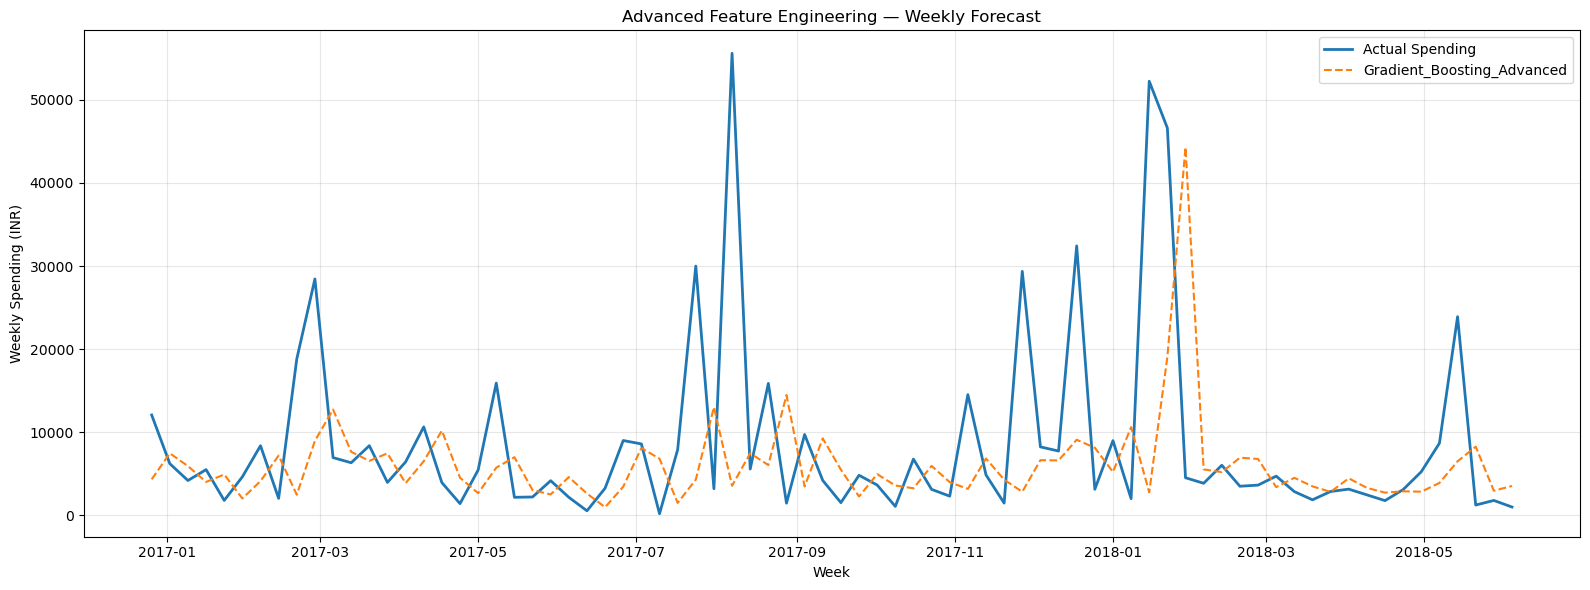


STEP 15 COMPLETED


In [45]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 15: ADVANCED FEATURE ENGINEERING
# ============================================================

import numpy as np
import pandas as pd
import warnings

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# 1. FEATURE ENGINEERING FUNCTION
# ------------------------------------------------------------

def create_advanced_features(series):

    data = pd.DataFrame(index=series.index)
    data["Target"] = series.astype(float)

    shifted = series.shift(1)

    # Lag features
    for lag in [1, 2, 3, 4, 8, 13, 26]:
        data[f"Lag_{lag}"] = series.shift(lag)

    # Rolling statistics
    for window in [4, 8, 13, 26]:

        recent = shifted.rolling(window)

        data[f"Mean_{window}"] = recent.mean()
        data[f"Median_{window}"] = recent.median()
        data[f"Std_{window}"] = recent.std()
        data[f"Min_{window}"] = recent.min()
        data[f"Max_{window}"] = recent.max()

    # Zero-spending frequency
    for window in [13, 26]:

        data[f"Zero_Frequency_{window}"] = (
            shifted.eq(0)
            .rolling(window)
            .mean()
        )

    # Long-term spending average
    data["Expanding_Mean"] = (
        shifted.expanding(min_periods=26).mean()
    )

    # Recent trend
    for window in [8, 13]:

        data[f"Trend_{window}"] = (
            shifted.rolling(window)
            .apply(
                lambda x: np.polyfit(
                    np.arange(len(x)), x, 1
                )[0],
                raw=True
            )
        )

    # Calendar seasonality
    week_number = pd.Series(
        [
            period.start_time.isocalendar().week
            for period in series.index
        ],
        index=series.index
    )

    data["Week_Sin"] = np.sin(
        2 * np.pi * week_number / 52.18
    )

    data["Week_Cos"] = np.cos(
        2 * np.pi * week_number / 52.18
    )

    return data.dropna()


# ------------------------------------------------------------
# 2. DEFINE FEATURE MODELS
# ------------------------------------------------------------

advanced_ml_models = {

    "Ridge_Advanced": make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    ),

    "Random_Forest_Advanced": RandomForestRegressor(
        n_estimators=300,
        max_depth=4,
        min_samples_leaf=3,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ),

    "Extra_Trees_Advanced": ExtraTreesRegressor(
        n_estimators=300,
        max_depth=4,
        min_samples_leaf=3,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient_Boosting_Advanced": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=3,
        loss="huber",
        random_state=42
    ),

    "Hist_Gradient_Boosting": HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.03,
        max_leaf_nodes=7,
        l2_regularization=5.0,
        random_state=42
    )
}


# ------------------------------------------------------------
# 3. PREPARE PREDICTION STORAGE
# ------------------------------------------------------------

advanced_ml_predictions = pd.DataFrame(
    index=weekly_spending.index[validation_origins]
)

advanced_ml_predictions["Actual"] = weekly_spending.iloc[
    validation_origins
].values

for model_name in advanced_ml_models:
    advanced_ml_predictions[model_name] = np.nan


# ------------------------------------------------------------
# 4. EXPANDING-WINDOW VALIDATION
# ------------------------------------------------------------

for i in validation_origins:

    history = weekly_spending.iloc[:i].astype(float)
    target_week = weekly_spending.index[i]

    # Build training data using past information only
    supervised_data = create_advanced_features(history)

    X_train = supervised_data.drop(columns=["Target"])
    y_train = supervised_data["Target"]

    # Build the next week's feature row
    extended_series = pd.concat([
        history,
        pd.Series(
            [np.nan],
            index=pd.PeriodIndex(
                [target_week],
                freq=history.index.freq
            )
        )
    ])

    next_features = create_advanced_features(
        extended_series
    ).iloc[[-1]]

    X_next = next_features[X_train.columns]

    # Train and predict
    for model_name, model in advanced_ml_models.items():

        try:

            model.fit(X_train, y_train)

            prediction = model.predict(X_next)[0]

            advanced_ml_predictions.loc[
                target_week, model_name
            ] = max(0.0, float(prediction))

        except Exception as e:

            print(
                f"{model_name} error at {target_week}: {e}"
            )


# ------------------------------------------------------------
# 5. EVALUATE MODELS
# ------------------------------------------------------------

advanced_ml_metrics = []

for model_name in advanced_ml_models:

    actual = advanced_ml_predictions["Actual"]
    predicted = advanced_ml_predictions[model_name]

    valid = predicted.notna()

    if valid.sum() == 0:
        continue

    advanced_ml_metrics.append({

        "Model": model_name,

        "Valid_Predictions": valid.sum(),

        "MAE": mean_absolute_error(
            actual[valid], predicted[valid]
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                actual[valid], predicted[valid]
            )
        ),

        "Bias": (
            predicted[valid] - actual[valid]
        ).mean()
    })


advanced_ml_metrics = pd.DataFrame(
    advanced_ml_metrics
).sort_values("MAE").reset_index(drop=True)

print("ADVANCED FEATURE ENGINEERING RESULTS")

display(advanced_ml_metrics.round(2))


# ------------------------------------------------------------
# 6. COMPLETE MODEL COMPARISON
# ------------------------------------------------------------

step15_leaderboard = pd.concat([

    pd.DataFrame([
        {
            "Model": "Rolling Median 7",
            "MAE": 6117.43,
            "RMSE": 11406.45,
            "Model_Group": "Baseline"
        }
    ]),

    advanced_ml_metrics.assign(
        Model_Group="Advanced ML"
    )[["Model", "MAE", "RMSE", "Model_Group"]]

], ignore_index=True).sort_values(
    "MAE"
).reset_index(drop=True)

print("\nSTEP 15 MODEL LEADERBOARD")

display(step15_leaderboard.round(2))


# ------------------------------------------------------------
# 7. BEST ADVANCED ML MODEL
# ------------------------------------------------------------

best_advanced_ml = advanced_ml_metrics.iloc[0]["Model"]

print("\nBEST ADVANCED ML MODEL:", best_advanced_ml)


# ------------------------------------------------------------
# 8. VISUALIZE BEST MODEL
# ------------------------------------------------------------

plt.figure(figsize=(16, 6))

plt.plot(
    advanced_ml_predictions.index.to_timestamp(),
    advanced_ml_predictions["Actual"],
    label="Actual Spending",
    linewidth=2
)

plt.plot(
    advanced_ml_predictions.index.to_timestamp(),
    advanced_ml_predictions[best_advanced_ml],
    label=best_advanced_ml,
    linestyle="--"
)

plt.title("Advanced Feature Engineering — Weekly Forecast")
plt.xlabel("Week")
plt.ylabel("Weekly Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSTEP 15 COMPLETED")


COMPLETE VALIDATION MODEL LEADERBOARD


,Model,Valid_Predictions,MAE,RMSE,Median_AE,WAPE_Percent,Bias
0,Log_Median_7,76,6117.43,11406.45,3011.73,71.59,-3365.44
1,Rolling_Median_7,76,6117.43,11406.45,3011.73,71.59,-3365.44
2,Winsorized_Median_7_98,76,6117.43,11406.45,3011.73,71.59,-3365.44
3,Winsorized_Median_7_95,76,6117.43,11406.45,3011.73,71.59,-3365.44
4,Rolling_Median_8,76,6157.41,11520.25,2607.77,72.06,-3384.19
5,Log_Mean_7,76,6350.73,11678.98,2899.62,74.32,-3165.46
6,Historical_Mean,76,6365.39,12269.39,2557.29,74.49,-4968.57
7,Rolling_Median_13,76,6442.82,11863.96,3363.40,75.40,-3574.98
8,Winsorized_Median_13_95,76,6442.82,11863.96,3363.40,75.40,-3574.98
9,Log_Median_13,76,6442.82,11863.96,3363.40,75.40,-3574.98



BEST MODEL BY MAE: Log_Median_7
BEST MODEL BY RMSE: Rolling_Median_7
BEST MODEL BY WAPE: Log_Median_7

ERROR BY SPENDING LEVEL


,Model,Spending_Segment,Weeks,MAE
0,Log_Median_7,Low Spending,25,2636.21
1,Log_Median_7,Medium Spending,26,1945.17
2,Log_Median_7,High Spending,25,13937.78
3,Rolling_Median_7,Low Spending,25,2636.21
4,Rolling_Median_7,Medium Spending,26,1945.17
...,...,...,...,...
130,"ARIMA(0, 1, 0)",Medium Spending,26,7237.69
131,"ARIMA(0, 1, 0)",High Spending,25,13967.35
132,Naive,Low Spending,25,5308.45
133,Naive,Medium Spending,26,7237.69



10 LARGEST FORECASTING ERRORS
Selected model: Log_Median_7


,Actual,Predicted,Error,Absolute_Error,Week
Week,,,,,
2017-08-07/2017-08-13,55597.00,7919.00,-47678.00,47678.00,2017-08-07/2017-08-13
2018-01-15/2018-01-21,52244.00,8250.00,-43994.00,43994.00,2018-01-15/2018-01-21
2018-01-22/2018-01-28,46613.90,8250.00,-38363.90,38363.90,2018-01-22/2018-01-28
2017-07-24/2017-07-30,30001.00,3282.00,-26719.00,26719.00,2017-07-24/2017-07-30
2017-11-27/2017-12-03,29370.00,3139.49,-26230.51,26230.51,2017-11-27/2017-12-03
2017-12-18/2017-12-24,32431.00,7750.00,-24681.00,24681.00,2017-12-18/2017-12-24
2017-02-27/2017-03-05,28453.47,4647.00,-23806.47,23806.47,2017-02-27/2017-03-05
2018-05-14/2018-05-20,23914.00,3115.00,-20799.00,20799.00,2018-05-14/2018-05-20
2017-02-20/2017-02-26,18824.00,4647.00,-14177.00,14177.00,2017-02-20/2017-02-26


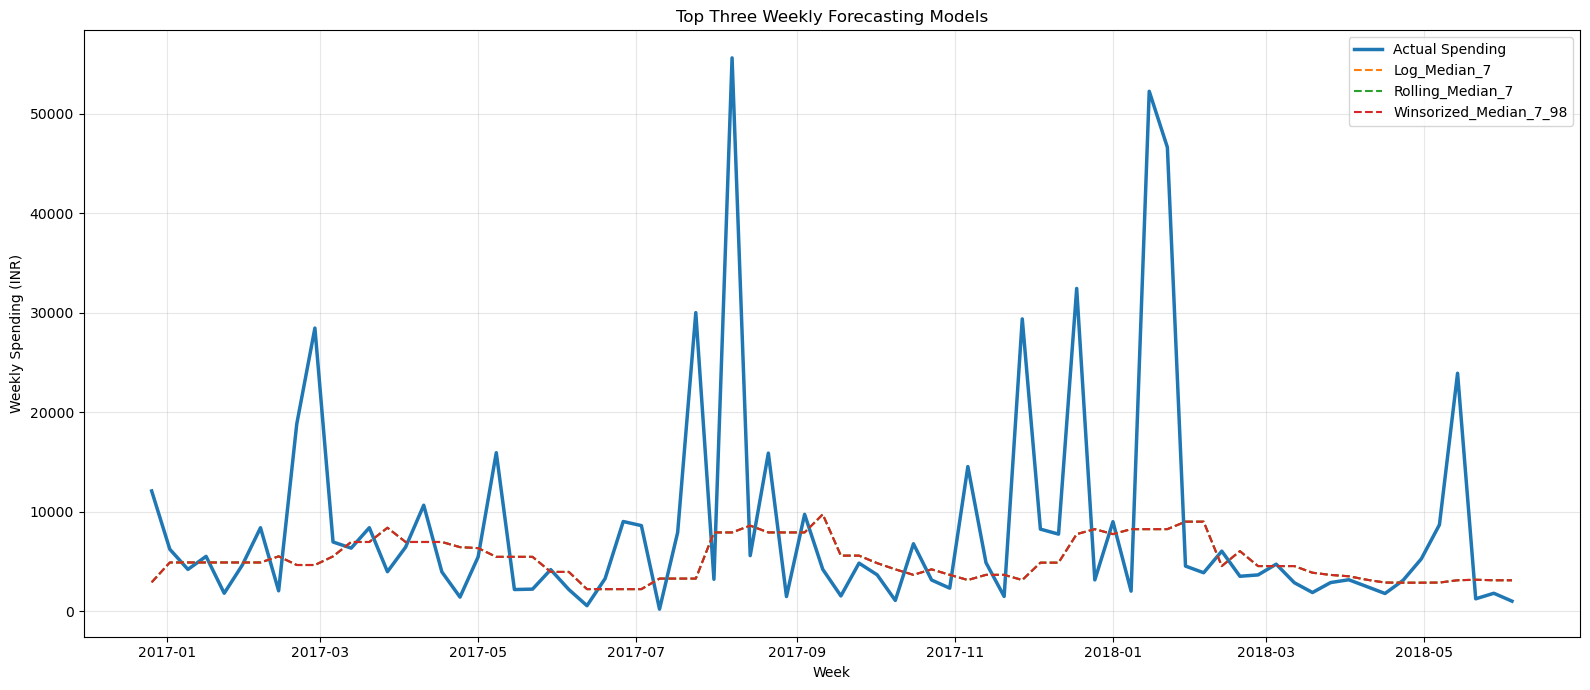

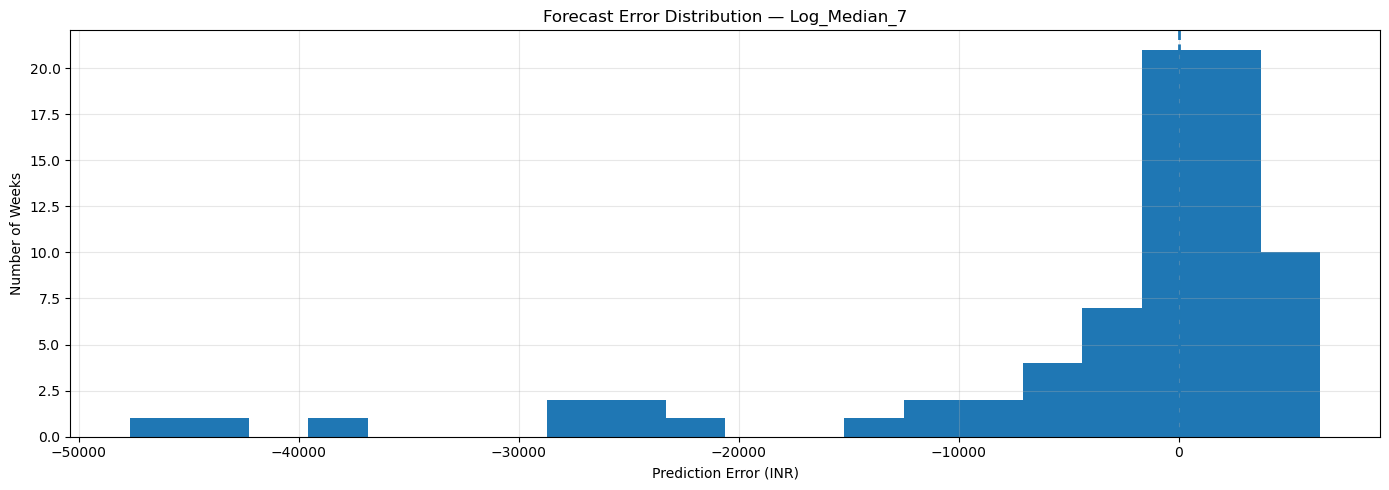


Validation weeks: 76
Models compared: 45
Final test set remains untouched: 26

STEP 16 COMPLETED


In [46]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 16: COMPLETE MODEL COMPARISON & ERROR ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error
)

# ------------------------------------------------------------
# 1. COLLECT ALL EXISTING VALIDATION PREDICTIONS
# ------------------------------------------------------------

validation_index = weekly_spending.index[validation_origins]

complete_predictions = pd.DataFrame(
    index=validation_index
)

complete_predictions["Actual"] = weekly_spending.iloc[
    validation_origins
].values

prediction_sources = [
    baseline_predictions,
    smoothing_predictions,
    arima_predictions,
    ml_predictions,
    advanced_predictions,
    robust_predictions,
    advanced_ml_predictions
]

for source in prediction_sources:

    for column in source.columns:

        if column == "Actual":
            continue

        if column not in complete_predictions.columns:

            complete_predictions[column] = (
                source[column].reindex(validation_index)
            )

# ------------------------------------------------------------
# 2. ADD ROLLING MEDIAN 7 AS OUR CURRENT BEST BASELINE
# ------------------------------------------------------------

rolling_median_7 = []

for i in validation_origins:

    history = weekly_spending.iloc[:i]

    rolling_median_7.append(
        history.iloc[-7:].median()
    )

complete_predictions["Rolling_Median_7"] = (
    rolling_median_7
)

# ------------------------------------------------------------
# 3. CALCULATE COMPREHENSIVE METRICS
# ------------------------------------------------------------

comparison_results = []

actual = complete_predictions["Actual"]

for model_name in complete_predictions.columns:

    if model_name == "Actual":
        continue

    predicted = complete_predictions[model_name]

    valid = predicted.notna()

    actual_valid = actual[valid]
    predicted_valid = predicted[valid]

    if len(actual_valid) == 0:
        continue

    errors = predicted_valid - actual_valid

    comparison_results.append({

        "Model": model_name,

        "Valid_Predictions": len(actual_valid),

        "MAE": mean_absolute_error(
            actual_valid, predicted_valid
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                actual_valid, predicted_valid
            )
        ),

        "Median_AE": median_absolute_error(
            actual_valid, predicted_valid
        ),

        "WAPE_Percent": (
            np.abs(errors).sum()
            / np.abs(actual_valid).sum()
        ) * 100,

        "Bias": errors.mean()
    })

complete_model_comparison = pd.DataFrame(
    comparison_results
).sort_values("MAE").reset_index(drop=True)

print("COMPLETE VALIDATION MODEL LEADERBOARD")

display(
    complete_model_comparison.round(2)
)

# ------------------------------------------------------------
# 4. IDENTIFY BEST MODELS BY DIFFERENT METRICS
# ------------------------------------------------------------

best_by_mae = complete_model_comparison.loc[
    complete_model_comparison["MAE"].idxmin()
]

best_by_rmse = complete_model_comparison.loc[
    complete_model_comparison["RMSE"].idxmin()
]

best_by_wape = complete_model_comparison.loc[
    complete_model_comparison["WAPE_Percent"].idxmin()
]

print("\nBEST MODEL BY MAE:", best_by_mae["Model"])
print("BEST MODEL BY RMSE:", best_by_rmse["Model"])
print("BEST MODEL BY WAPE:", best_by_wape["Model"])

# ------------------------------------------------------------
# 5. SPENDING-LEVEL ERROR ANALYSIS
# ------------------------------------------------------------

# Divide actual validation spending into three groups.
# These thresholds are calculated from validation actuals
# only for descriptive error analysis.

low_threshold = actual.quantile(0.33)
high_threshold = actual.quantile(0.67)

spending_segments = pd.Series(
    np.select(
        [
            actual <= low_threshold,
            actual <= high_threshold
        ],
        [
            "Low Spending",
            "Medium Spending"
        ],
        default="High Spending"
    ),
    index=actual.index
)

segment_results = []

for model_name in complete_model_comparison["Model"]:

    predicted = complete_predictions[model_name]

    for segment in [
        "Low Spending",
        "Medium Spending",
        "High Spending"
    ]:

        mask = (
            (spending_segments == segment)
            & predicted.notna()
        )

        if mask.sum() == 0:
            continue

        segment_results.append({

            "Model": model_name,

            "Spending_Segment": segment,

            "Weeks": mask.sum(),

            "MAE": mean_absolute_error(
                actual[mask],
                predicted[mask]
            )
        })

segment_error_analysis = pd.DataFrame(
    segment_results
)

print("\nERROR BY SPENDING LEVEL")

display(
    segment_error_analysis.round(2)
)

# ------------------------------------------------------------
# 6. LARGEST ERRORS OF THE CURRENT BEST MODEL
# ------------------------------------------------------------

best_model_name = best_by_mae["Model"]

best_predictions = complete_predictions[
    best_model_name
]

error_analysis = pd.DataFrame({

    "Actual": actual,

    "Predicted": best_predictions,

    "Error": best_predictions - actual,

    "Absolute_Error": (
        best_predictions - actual
    ).abs()
})

error_analysis["Week"] = (
    error_analysis.index.astype(str)
)

largest_errors = error_analysis.sort_values(
    "Absolute_Error",
    ascending=False
).head(10)

print("\n10 LARGEST FORECASTING ERRORS")
print("Selected model:", best_model_name)

display(largest_errors.round(2))

# ------------------------------------------------------------
# 7. VISUALIZE TOP THREE MODELS
# ------------------------------------------------------------

top_three_models = complete_model_comparison[
    "Model"
].head(3).tolist()

plt.figure(figsize=(16, 7))

plt.plot(
    validation_index.to_timestamp(),
    actual,
    label="Actual Spending",
    linewidth=2.5
)

for model_name in top_three_models:

    plt.plot(
        validation_index.to_timestamp(),
        complete_predictions[model_name],
        linestyle="--",
        label=model_name
    )

plt.title("Top Three Weekly Forecasting Models")
plt.xlabel("Week")
plt.ylabel("Weekly Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. ERROR DISTRIBUTION OF BEST MODEL
# ------------------------------------------------------------

plt.figure(figsize=(14, 5))

plt.hist(
    error_analysis["Error"].dropna(),
    bins=20
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=2
)

plt.title(
    f"Forecast Error Distribution — {best_model_name}"
)

plt.xlabel("Prediction Error (INR)")
plt.ylabel("Number of Weeks")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. SAVE EXPERIMENT RESULTS IN MEMORY
# ------------------------------------------------------------

print("\nValidation weeks:", len(validation_index))
print("Models compared:", len(complete_model_comparison))
print("Final test set remains untouched:", len(final_test_data))

print("\nSTEP 16 COMPLETED")


MODEL PERFORMANCE ACROSS VALIDATION PERIODS


,Period,Model,Weeks,MAE,RMSE,Bias
0,Early Validation,Rolling_Median_7,26,3955.12,6501.81,-1499.89
1,Early Validation,Rolling_Median_8,26,4060.87,6403.01,-1446.65
2,Early Validation,Log_Mean_7,26,3889.98,6564.57,-1481.20
3,Early Validation,Historical_Mean,26,4718.95,7512.25,-4206.83
4,Early Validation,Rolling_Median_13,26,4338.89,6635.52,-1698.35
5,Middle Validation,Rolling_Median_7,25,7465.93,12898.87,-4550.65
6,Middle Validation,Rolling_Median_8,25,7484.02,13170.63,-4656.35
7,Middle Validation,Log_Mean_7,25,7365.23,13444.75,-4946.57
8,Middle Validation,Historical_Mean,25,7226.39,13561.41,-6071.45
9,Middle Validation,Rolling_Median_13,25,7670.21,13575.39,-4952.17



MODEL STABILITY SUMMARY


,Model,Average_Block_MAE,Worst_Block_MAE,Best_Block_MAE,MAE_Variability,Average_Block_RMSE,Overall_MAE
0,Rolling_Median_7,6146.26,7465.93,3955.12,1910.77,11002.93,6117.43
1,Rolling_Median_8,6185.36,7484.02,4060.87,1854.99,11087.12,6157.41
2,Log_Mean_7,6383.54,7895.42,3889.98,2175.70,11253.23,6350.73
3,Historical_Mean,6387.34,7226.39,4718.95,1444.88,11912.55,6365.39
4,Rolling_Median_13,6470.87,7670.21,4338.89,1851.16,11425.11,6442.82


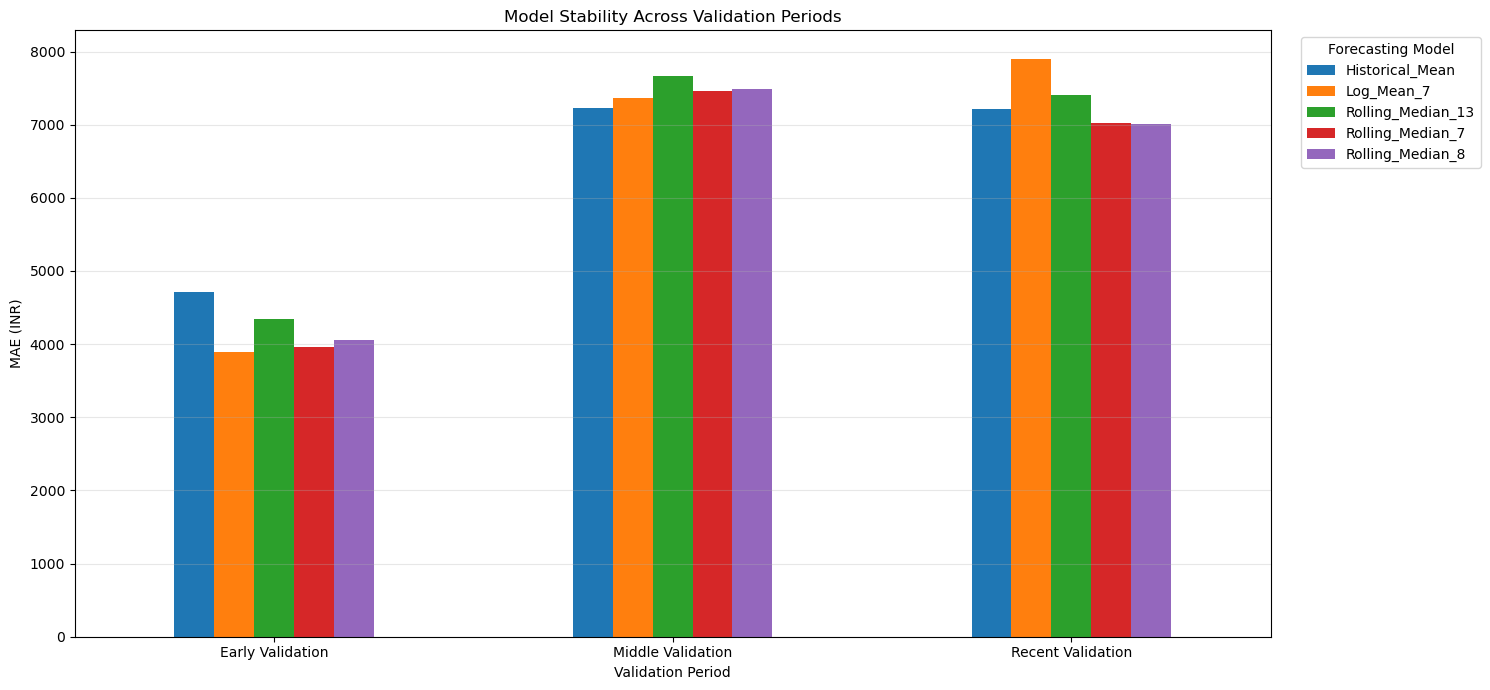


FINAL CANDIDATE RANKING


,Model,Overall_MAE,Worst_Block_MAE,MAE_Variability,Average_Block_RMSE,Overall_Rank,Stability_Rank,Combined_Rank
0,Rolling_Median_7,6117.43,7465.93,1910.77,11002.93,1.0,2.0,3.0
1,Rolling_Median_8,6157.41,7484.02,1854.99,11087.12,2.0,3.0,5.0
2,Historical_Mean,6365.39,7226.39,1444.88,11912.55,4.0,1.0,5.0
3,Log_Mean_7,6350.73,7895.42,2175.70,11253.23,3.0,5.0,8.0
4,Rolling_Median_13,6442.82,7670.21,1851.16,11425.11,5.0,4.0,9.0



SELECTED FINAL TEST CANDIDATES:
1. Rolling_Median_7
2. Rolling_Median_8

Final test set remains untouched: 26

STEP 17 COMPLETED


In [47]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 17: MODEL STABILITY & FINAL CANDIDATE SELECTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. SELECT DISTINCT TOP CANDIDATES
# ------------------------------------------------------------

candidate_models = [
    "Rolling_Median_7",
    "Rolling_Median_8",
    "Log_Mean_7",
    "Historical_Mean",
    "Rolling_Median_13"
]

# Verify all candidate predictions are available
missing_models = [
    model for model in candidate_models
    if model not in complete_predictions.columns
]

if missing_models:
    raise ValueError(
        f"Missing candidate predictions: {missing_models}"
    )

candidate_predictions = complete_predictions[
    ["Actual"] + candidate_models
].copy()

assert len(candidate_predictions) == 76

# ------------------------------------------------------------
# 2. DIVIDE VALIDATION INTO THREE CHRONOLOGICAL BLOCKS
# ------------------------------------------------------------

validation_blocks = np.array_split(
    np.arange(len(candidate_predictions)),
    3
)

block_names = [
    "Early Validation",
    "Middle Validation",
    "Recent Validation"
]

stability_results = []

for block_name, positions in zip(
    block_names, validation_blocks
):

    block_data = candidate_predictions.iloc[positions]

    actual = block_data["Actual"]

    for model_name in candidate_models:

        predicted = block_data[model_name]

        stability_results.append({

            "Period": block_name,

            "Model": model_name,

            "Weeks": len(block_data),

            "MAE": mean_absolute_error(
                actual, predicted
            ),

            "RMSE": np.sqrt(
                mean_squared_error(
                    actual, predicted
                )
            ),

            "Bias": (
                predicted - actual
            ).mean()
        })

stability_results = pd.DataFrame(
    stability_results
)

print("MODEL PERFORMANCE ACROSS VALIDATION PERIODS")

display(
    stability_results.round(2)
)

# ------------------------------------------------------------
# 3. CALCULATE STABILITY SUMMARY
# ------------------------------------------------------------

stability_summary = (
    stability_results
    .groupby("Model")
    .agg(
        Average_Block_MAE=("MAE", "mean"),
        Worst_Block_MAE=("MAE", "max"),
        Best_Block_MAE=("MAE", "min"),
        MAE_Variability=("MAE", "std"),
        Average_Block_RMSE=("RMSE", "mean")
    )
    .reset_index()
)

# Overall MAE across all validation observations
overall_mae = {
    model: mean_absolute_error(
        candidate_predictions["Actual"],
        candidate_predictions[model]
    )
    for model in candidate_models
}

stability_summary["Overall_MAE"] = (
    stability_summary["Model"].map(overall_mae)
)

stability_summary = stability_summary.sort_values(
    ["Overall_MAE", "Worst_Block_MAE"]
).reset_index(drop=True)

print("\nMODEL STABILITY SUMMARY")

display(
    stability_summary.round(2)
)

# ------------------------------------------------------------
# 4. VISUALIZE MAE ACROSS THE THREE PERIODS
# ------------------------------------------------------------

stability_pivot = stability_results.pivot(
    index="Period",
    columns="Model",
    values="MAE"
)

stability_pivot = stability_pivot.reindex(
    block_names
)

stability_pivot.plot(
    kind="bar",
    figsize=(15, 7)
)

plt.title("Model Stability Across Validation Periods")
plt.xlabel("Validation Period")
plt.ylabel("MAE (INR)")
plt.xticks(rotation=0)
plt.legend(
    title="Forecasting Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. IDENTIFY FINAL CANDIDATES
# ------------------------------------------------------------

# Rank models by overall validation MAE.
# Use worst-block MAE as a secondary stability measure.

final_candidate_ranking = stability_summary[
    [
        "Model",
        "Overall_MAE",
        "Worst_Block_MAE",
        "MAE_Variability",
        "Average_Block_RMSE"
    ]
].copy()

final_candidate_ranking["Overall_Rank"] = (
    final_candidate_ranking["Overall_MAE"]
    .rank(method="min")
)

final_candidate_ranking["Stability_Rank"] = (
    final_candidate_ranking["Worst_Block_MAE"]
    .rank(method="min")
)

final_candidate_ranking["Combined_Rank"] = (
    final_candidate_ranking["Overall_Rank"]
    + final_candidate_ranking["Stability_Rank"]
)

final_candidate_ranking = (
    final_candidate_ranking
    .sort_values(
        ["Combined_Rank", "Overall_MAE"]
    )
    .reset_index(drop=True)
)

print("\nFINAL CANDIDATE RANKING")

display(
    final_candidate_ranking.round(2)
)

# ------------------------------------------------------------
# 6. SELECT TWO CANDIDATES FOR FINAL TESTING
# ------------------------------------------------------------

selected_candidates = (
    final_candidate_ranking["Model"]
    .head(2)
    .tolist()
)

print("\nSELECTED FINAL TEST CANDIDATES:")

for rank, model_name in enumerate(
    selected_candidates, start=1
):
    print(f"{rank}. {model_name}")

# ------------------------------------------------------------
# 7. SAVE SELECTION INFORMATION
# ------------------------------------------------------------

final_candidate_selection = {
    "selected_candidates": selected_candidates,
    "validation_weeks": len(candidate_predictions),
    "selection_method": (
        "Overall MAE and chronological block stability"
    )
}

print("\nFinal test set remains untouched:", len(final_test_data))
print("\nSTEP 17 COMPLETED")


FINAL TEST PERIOD
Start: 2018-06-11/2018-06-17
End: 2018-12-03/2018-12-09
Test observations: 26

FINAL TEST PERFORMANCE


,Model,MAE,RMSE,Median_AE,WAPE_Percent,Bias
0,Rolling_Median_8,2404.92,4838.58,1761.58,76.45,-789.83
1,Rolling_Median_7,2557.57,5192.00,1871.12,81.31,-1022.02
2,Naive,3059.60,6312.09,999.42,97.27,-79.54



BEST MODEL ON FINAL TEST: Rolling_Median_8

VALIDATION VS FINAL TEST


,Model,Validation_MAE,Final_Test_MAE
0,Rolling_Median_7,6117.43,2557.57
1,Rolling_Median_8,6157.41,2404.92



FINAL TEST WEEK-BY-WEEK PREDICTIONS


,Actual,Rolling_Median_7,Rolling_Median_8,Naive
Week,,,,
2018-06-11/2018-06-17,1228.60,3115.00,2461.50,1015.00
2018-06-18/2018-06-24,5384.75,1808.00,2461.50,1228.60
2018-06-25/2018-07-01,26429.67,1808.00,3534.50,5384.75
2018-07-02/2018-07-08,4298.00,1808.00,3596.38,26429.67
2018-07-09/2018-07-15,4161.00,1808.00,3053.00,4298.00
2018-07-16/2018-07-22,3477.00,4161.00,2984.50,4161.00
2018-07-23/2018-07-29,6216.36,4161.00,3819.00,3477.00
2018-07-30/2018-08-05,5752.00,4298.00,4229.50,6216.36
2018-08-06/2018-08-12,1713.00,5384.75,4841.38,5752.00


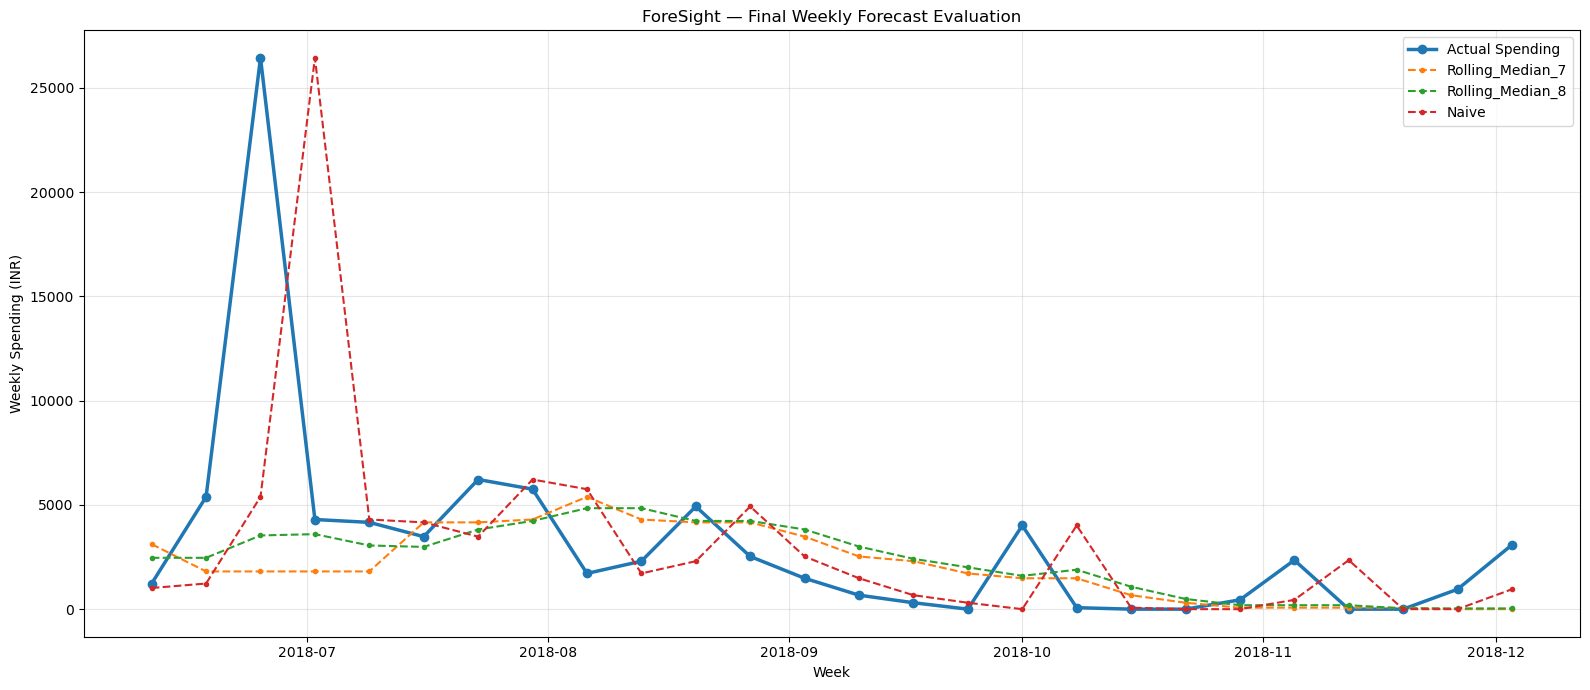


LARGEST FINAL TEST ERRORS


,Actual,Predicted,Error,Absolute_Error
Week,,,,
2018-06-25/2018-07-01,26429.67,3534.50,-22895.17,22895.17
2018-08-06/2018-08-12,1713.00,4841.38,3128.38,3128.38
2018-12-03/2018-12-09,3083.00,35.50,-3047.50,3047.50
2018-06-18/2018-06-24,5384.75,2461.50,-2923.25,2923.25
2018-08-13/2018-08-19,2300.00,4841.38,2541.38,2541.38
2018-10-01/2018-10-07,4012.00,1597.00,-2415.00,2415.00
2018-07-23/2018-07-29,6216.36,3819.00,-2397.36,2397.36
2018-09-03/2018-09-09,1481.00,3819.00,2338.00,2338.00
2018-09-10/2018-09-16,670.00,3001.42,2331.43,2331.43



FORESIGHT WEEKLY FORECASTING — FINAL EVALUATION
Validation observations: 76
Final test observations: 26
Selected candidates: ['Rolling_Median_7', 'Rolling_Median_8']
Best final-test model: Rolling_Median_8
Final-test MAE: 2404.92
Final-test RMSE: 4838.58

STEP 18 COMPLETED


In [48]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 18: FINAL TEST SET EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error
)

# ------------------------------------------------------------
# 1. VERIFY FINAL TEST SET
# ------------------------------------------------------------

assert len(final_test_data) == 26
assert len(test_origins) == 26

assert (
    validation_origins[-1] < test_origins[0]
), "Validation and test periods overlap!"

print("FINAL TEST PERIOD")
print("Start:", final_test_data.index[0])
print("End:", final_test_data.index[-1])
print("Test observations:", len(final_test_data))

# ------------------------------------------------------------
# 2. GENERATE FINAL TEST PREDICTIONS
# ------------------------------------------------------------

final_test_predictions = pd.DataFrame(
    index=final_test_data.index
)

final_test_predictions["Actual"] = (
    final_test_data.values
)

final_test_predictions["Rolling_Median_7"] = np.nan
final_test_predictions["Rolling_Median_8"] = np.nan
final_test_predictions["Naive"] = np.nan

for i in test_origins:

    history = weekly_spending.iloc[:i].astype(float)

    target_week = weekly_spending.index[i]

    # ROLLING MEDIAN 7
    final_test_predictions.loc[
        target_week, "Rolling_Median_7"
    ] = history.iloc[-7:].median()

    # ROLLING MEDIAN 8
    final_test_predictions.loc[
        target_week, "Rolling_Median_8"
    ] = history.iloc[-8:].median()

    # NAIVE BENCHMARK
    final_test_predictions.loc[
        target_week, "Naive"
    ] = history.iloc[-1]


# ------------------------------------------------------------
# 3. EVALUATE FINAL TEST PERFORMANCE
# ------------------------------------------------------------

final_test_metrics = []

actual = final_test_predictions["Actual"]

for model_name in [
    "Rolling_Median_7",
    "Rolling_Median_8",
    "Naive"
]:

    predicted = final_test_predictions[model_name]

    errors = predicted - actual

    final_test_metrics.append({

        "Model": model_name,

        "MAE": mean_absolute_error(
            actual, predicted
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                actual, predicted
            )
        ),

        "Median_AE": median_absolute_error(
            actual, predicted
        ),

        "WAPE_Percent": (
            errors.abs().sum()
            / actual.abs().sum()
        ) * 100,

        "Bias": errors.mean()
    })


final_test_metrics = pd.DataFrame(
    final_test_metrics
).sort_values("MAE").reset_index(drop=True)

print("\nFINAL TEST PERFORMANCE")

display(final_test_metrics.round(2))


# ------------------------------------------------------------
# 4. IDENTIFY FINAL TEST WINNER
# ------------------------------------------------------------

best_test_model = final_test_metrics.iloc[0]["Model"]

print("\nBEST MODEL ON FINAL TEST:", best_test_model)

# ------------------------------------------------------------
# 5. COMPARE VALIDATION AND FINAL TEST PERFORMANCE
# ------------------------------------------------------------

validation_test_comparison = pd.DataFrame({

    "Model": [
        "Rolling_Median_7",
        "Rolling_Median_8"
    ],

    "Validation_MAE": [
        mean_absolute_error(
            complete_predictions["Actual"],
            complete_predictions["Rolling_Median_7"]
        ),
        mean_absolute_error(
            complete_predictions["Actual"],
            complete_predictions["Rolling_Median_8"]
        )
    ],

    "Final_Test_MAE": [
        final_test_metrics.set_index("Model").loc[
            "Rolling_Median_7", "MAE"
        ],
        final_test_metrics.set_index("Model").loc[
            "Rolling_Median_8", "MAE"
        ]
    ]
})

print("\nVALIDATION VS FINAL TEST")

display(validation_test_comparison.round(2))


# ------------------------------------------------------------
# 6. ACTUAL VS PREDICTED TEST RESULTS
# ------------------------------------------------------------

print("\nFINAL TEST WEEK-BY-WEEK PREDICTIONS")

display(final_test_predictions.round(2))


# ------------------------------------------------------------
# 7. VISUALIZE FINAL TEST FORECASTS
# ------------------------------------------------------------

plt.figure(figsize=(16, 7))

plt.plot(
    final_test_predictions.index.to_timestamp(),
    final_test_predictions["Actual"],
    label="Actual Spending",
    linewidth=2.5,
    marker="o"
)

for model_name in [
    "Rolling_Median_7",
    "Rolling_Median_8",
    "Naive"
]:

    plt.plot(
        final_test_predictions.index.to_timestamp(),
        final_test_predictions[model_name],
        label=model_name,
        linestyle="--",
        marker="."
    )

plt.title("ForeSight — Final Weekly Forecast Evaluation")
plt.xlabel("Week")
plt.ylabel("Weekly Spending (INR)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. FINAL TEST ERROR ANALYSIS
# ------------------------------------------------------------

best_predictions = final_test_predictions[
    best_test_model
]

final_test_error_analysis = pd.DataFrame({

    "Actual": actual,

    "Predicted": best_predictions,

    "Error": best_predictions - actual,

    "Absolute_Error": (
        best_predictions - actual
    ).abs()
})

print("\nLARGEST FINAL TEST ERRORS")

display(
    final_test_error_analysis.sort_values(
        "Absolute_Error",
        ascending=False
    ).head(10).round(2)
)


# ------------------------------------------------------------
# 9. FINAL EVALUATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("FORESIGHT WEEKLY FORECASTING — FINAL EVALUATION")
print("=" * 55)

print("Validation observations:", len(validation_data))
print("Final test observations:", len(final_test_data))

print("Selected candidates:", selected_candidates)

print("Best final-test model:", best_test_model)

print(
    "Final-test MAE:",
    round(
        final_test_metrics.iloc[0]["MAE"], 2
    )
)

print(
    "Final-test RMSE:",
    round(
        final_test_metrics.iloc[0]["RMSE"], 2
    )
)

print("\nSTEP 18 COMPLETED")


In [49]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# STEP 19: PACKAGE WEEKLY FORECASTING MODULE
# ============================================================

import os
import sys
import joblib
import importlib.util
import numpy as np
import pandas as pd

from pathlib import Path

# ------------------------------------------------------------
# 1. IDENTIFY PROJECT ROOT
# ------------------------------------------------------------

current_directory = Path.cwd()

if (current_directory / "notebooks").exists():
    PROJECT_ROOT = current_directory

elif current_directory.name == "notebooks":
    PROJECT_ROOT = current_directory.parent

else:
    PROJECT_ROOT = current_directory

# Create required directories
forecasting_directory = PROJECT_ROOT / "src" / "forecasting"
models_directory = PROJECT_ROOT / "models"
predictions_directory = PROJECT_ROOT / "data" / "predictions"

forecasting_directory.mkdir(parents=True, exist_ok=True)
models_directory.mkdir(parents=True, exist_ok=True)
predictions_directory.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. DEFINE FORECASTING MODULE
# ------------------------------------------------------------

module_code = '''
import numpy as np
import pandas as pd


def forecast_next_week(weekly_history, window=7):
    """
    Forecast next week's spending using rolling median.

    Parameters
    ----------
    weekly_history : pandas.Series
        Historical weekly spending values in INR.

    window : int
        Number of recent weeks used for forecasting.

    Returns
    -------
    float
        Forecasted next-week spending in INR.
    """

    if not isinstance(weekly_history, pd.Series):
        raise TypeError("weekly_history must be a pandas Series.")

    if window < 1:
        raise ValueError("window must be at least 1.")

    history = pd.to_numeric(
        weekly_history, errors="coerce"
    ).dropna()

    if len(history) < window:
        raise ValueError(
            f"At least {window} valid weeks are required."
        )

    if not np.isfinite(history.to_numpy()).all():
        raise ValueError("History contains invalid values.")

    if (history < 0).any():
        raise ValueError("Spending values cannot be negative.")

    forecast = history.iloc[-window:].median()

    return max(0.0, float(forecast))


def forecast_with_bundle(weekly_history, bundle):
    """
    Forecast using a saved ForeSight configuration.
    """

    window = bundle["primary_window"]

    return forecast_next_week(
        weekly_history,
        window=window
    )
'''

module_path = (
    forecasting_directory / "weekly_forecasting.py"
)

module_path.write_text(
    module_code,
    encoding="utf-8"
)

print("Forecasting module created:")
print(module_path)


# ------------------------------------------------------------
# 3. CREATE MODEL CONFIGURATION BUNDLE
# ------------------------------------------------------------

weekly_forecasting_bundle = {

    "project": "ForeSight",

    "module": "weekly_forecasting.py",

    "forecasting_method": "Rolling Median",

    "primary_window": 7,

    "alternative_window": 8,

    "frequency": "Weekly",

    "forecast_horizon": "One week ahead",

    "currency": "INR",

    "primary_selection_basis": (
        "Chronological validation MAE and stability"
    ),

    "validation_metrics": {
        "rolling_median_7_MAE": 6117.43,
        "rolling_median_7_RMSE": 11406.45
    },

    "final_test_metrics": {
        "rolling_median_7_MAE": 2557.57,
        "rolling_median_7_RMSE": 5192.00,
        "rolling_median_8_MAE": 2404.92,
        "rolling_median_8_RMSE": 4838.58
    },

    "training_data_end": "2018-12-09",

    "dataset_observations": 206,

    "limitations": [
        "Developed using one household dataset",
        "Historical dataset ends in December 2018",
        "Cannot anticipate unexpected large purchases",
        "Requires recent weekly spending history"
    ]
}

bundle_path = (
    models_directory / "weekly_forecasting_bundle.joblib"
)

joblib.dump(
    weekly_forecasting_bundle,
    bundle_path
)

print("\nConfiguration bundle saved:")
print(bundle_path)


# ------------------------------------------------------------
# 4. IMPORT AND VERIFY THE SAVED MODULE
# ------------------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "weekly_forecasting",
    module_path
)

weekly_forecasting = importlib.util.module_from_spec(spec)

spec.loader.exec_module(weekly_forecasting)

# Reload saved configuration
loaded_bundle = joblib.load(bundle_path)

# Test primary forecasting function
primary_forecast = weekly_forecasting.forecast_with_bundle(
    weekly_spending,
    loaded_bundle
)

# Test alternative configuration
alternative_forecast = weekly_forecasting.forecast_next_week(
    weekly_spending,
    window=loaded_bundle["alternative_window"]
)

print("\nMODULE VERIFICATION")

print(
    "Primary model (7-week median):",
    round(primary_forecast, 2)
)

print(
    "Alternative model (8-week median):",
    round(alternative_forecast, 2)
)


# ------------------------------------------------------------
# 5. SAVE FINAL TEST PREDICTIONS
# ------------------------------------------------------------

final_test_export = final_test_predictions.copy()

final_test_export.index = (
    final_test_export.index.astype(str)
)

csv_path = (
    predictions_directory
    / "weekly_forecasting_final_test_predictions.csv"
)

final_test_export.to_csv(csv_path)

print("\nFinal test predictions saved:")
print(csv_path)


# ------------------------------------------------------------
# 6. VERIFY ALL GENERATED FILES
# ------------------------------------------------------------

required_files = [
    module_path,
    bundle_path,
    csv_path
]

print("\nFILE VERIFICATION")

for file_path in required_files:

    print(
        file_path.name,
        "->",
        "EXISTS" if file_path.exists() else "MISSING"
    )

assert all(
    file_path.exists() for file_path in required_files
)

print("\nSTEP 19 COMPLETED SUCCESSFULLY")
print("FORESIGHT WEEKLY FORECASTING MODULE PACKAGED")


Forecasting module created:
c:\Users\singh\Desktop\foresight\src\forecasting\weekly_forecasting.py

Configuration bundle saved:
c:\Users\singh\Desktop\foresight\models\weekly_forecasting_bundle.joblib

MODULE VERIFICATION
Primary model (7-week median): 446.0
Alternative model (8-week median): 223.0

Final test predictions saved:
c:\Users\singh\Desktop\foresight\data\predictions\weekly_forecasting_final_test_predictions.csv

FILE VERIFICATION
weekly_forecasting.py -> EXISTS
weekly_forecasting_bundle.joblib -> EXISTS
weekly_forecasting_final_test_predictions.csv -> EXISTS

STEP 19 COMPLETED SUCCESSFULLY
FORESIGHT WEEKLY FORECASTING MODULE PACKAGED


In [50]:

# ============================================================
# FORESIGHT — STEP 20A
# AI-ASSISTED MODEL DISCOVERY
# CHECK AVAILABLE ML LIBRARIES
# ============================================================

import importlib.util
import sklearn
import statsmodels

libraries = {
    "Scikit-learn": "sklearn",
    "XGBoost": "xgboost",
    "CatBoost": "catboost",
    "LightGBM": "lightgbm",
    "Statsmodels": "statsmodels"
}

library_results = []

for library_name, module_name in libraries.items():

    available = (
        importlib.util.find_spec(module_name) is not None
    )

    library_results.append({
        "Library": library_name,
        "Available": available
    })

library_results = pd.DataFrame(library_results)

print("FORESIGHT — AVAILABLE ML LIBRARIES")

display(library_results)

print("\nScikit-learn version:", sklearn.__version__)
print("Statsmodels version:", statsmodels.__version__)

print("\nSTEP 20A COMPLETED")


FORESIGHT — AVAILABLE ML LIBRARIES


,Library,Available
0,Scikit-learn,True
1,XGBoost,False
2,CatBoost,False
3,LightGBM,False
4,Statsmodels,True



Scikit-learn version: 1.6.1
Statsmodels version: 0.14.4

STEP 20A COMPLETED


In [51]:

# ============================================================
# STEP 20B: ADVANCED FEATURE DATASET
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit

# Use the feature engineering function already developed
# in Step 15.

ai_feature_data = create_advanced_features(weekly_spending)

ai_X = ai_feature_data.drop(columns=["Target"]).copy()
ai_y = ai_feature_data["Target"].copy()

print("FEATURE DATASET")
print("Observations:", len(ai_feature_data))
print("Features:", ai_X.shape[1])
print("Target observations:", len(ai_y))

display(ai_feature_data.head())

assert ai_X.index.equals(ai_y.index)
assert ai_X.isna().sum().sum() == 0
assert ai_y.notna().all()

# Five chronological validation folds
ai_cv = TimeSeriesSplit(n_splits=5)

print("\nChronological cross-validation folds:")

for fold, (train_idx, test_idx) in enumerate(
    ai_cv.split(ai_X), start=1
):
    print(
        f"Fold {fold}: "
        f"Train={len(train_idx)}, "
        f"Validation={len(test_idx)}, "
        f"From={ai_X.index[test_idx[0]]} "
        f"To={ai_X.index[test_idx[-1]]}"
    )

print("\nSTEP 20B COMPLETED")


FEATURE DATASET
Observations: 180
Features: 34
Target observations: 180


,Target,Lag_1,Lag_2,Lag_3,Lag_4,Lag_8,Lag_13,Lag_26,Mean_4,Median_4,...,Std_26,Min_26,Max_26,Zero_Frequency_13,Zero_Frequency_26,Expanding_Mean,Trend_8,Trend_13,Week_Sin,Week_Cos
Week,,,,,,,,,,,,,,,,,,,,,
2015-06-29/2015-07-05,236.0,999.0,0.0,0.0,145.0,126.0,3015.0,2254.0,286.00,72.5,...,3542.098686,0.0,12082.0,0.307692,0.153846,2956.530769,-479.880952,-136.527473,-0.109357,-0.994003
2015-07-06/2015-07-12,8280.0,236.0,999.0,0.0,0.0,8779.0,0.0,6575.0,308.75,118.0,...,3580.015016,0.0,12082.0,0.307692,0.153846,2855.770370,-749.571429,-142.197802,-0.227968,-0.973669
2015-07-13/2015-07-19,2599.0,8280.0,236.0,999.0,0.0,0.0,1004.0,3736.0,2378.75,617.5,...,3665.032348,0.0,12082.0,0.230769,0.153846,3049.492857,575.559524,16.626374,-0.343277,-0.939234
2015-07-20/2015-07-26,0.0,2599.0,8280.0,236.0,999.0,2671.0,759.0,924.0,3028.50,1799.0,...,3661.992416,0.0,12082.0,0.230769,0.153846,3033.958621,498.547619,-18.714286,-0.453615,-0.891198
2015-07-27/2015-08-02,4106.0,0.0,2599.0,8280.0,236.0,145.0,6055.0,1759.0,2778.75,1417.5,...,3686.346186,0.0,12082.0,0.307692,0.192308,2932.826667,429.250000,-157.923077,-0.557384,-0.830255



Chronological cross-validation folds:
Fold 1: Train=30, Validation=30, From=2016-01-25/2016-01-31 To=2016-08-15/2016-08-21
Fold 2: Train=60, Validation=30, From=2016-08-22/2016-08-28 To=2017-03-13/2017-03-19
Fold 3: Train=90, Validation=30, From=2017-03-20/2017-03-26 To=2017-10-09/2017-10-15
Fold 4: Train=120, Validation=30, From=2017-10-16/2017-10-22 To=2018-05-07/2018-05-13
Fold 5: Train=150, Validation=30, From=2018-05-14/2018-05-20 To=2018-12-03/2018-12-09

STEP 20B COMPLETED


In [52]:

# ============================================================
# STEP 20C: ADDITIONAL MACHINE LEARNING COMPARISON
# ============================================================

import warnings
warnings.filterwarnings("ignore")

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import ElasticNet
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor
)

from sklearn.metrics import mean_absolute_error, mean_squared_error

ai_models = {

    "ElasticNet": make_pipeline(
        StandardScaler(),
        ElasticNet(
            alpha=1.0,
            l1_ratio=0.5,
            max_iter=10000
        )
    ),

    "SVR_RBF": make_pipeline(
        StandardScaler(),
        SVR(
            kernel="rbf",
            C=10,
            epsilon=0.1
        )
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(
            n_neighbors=5,
            weights="distance"
        )
    ),

    "Random_Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=4,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    "Extra_Trees": ExtraTreesRegressor(
        n_estimators=300,
        max_depth=4,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient_Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=3,
        loss="huber",
        random_state=42
    ),

    "Hist_Gradient_Boosting": HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.03,
        max_leaf_nodes=7,
        l2_regularization=5.0,
        random_state=42
    )
}

# ------------------------------------------------------------
# OPTIONAL ADVANCED LIBRARIES
# ------------------------------------------------------------

try:
    from xgboost import XGBRegressor

    ai_models["XGBoost"] = XGBRegressor(
        n_estimators=200,
        max_depth=2,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
        verbosity=0
    )

except ImportError:
    print("XGBoost unavailable - skipped.")

try:
    from catboost import CatBoostRegressor

    ai_models["CatBoost"] = CatBoostRegressor(
        iterations=200,
        depth=3,
        learning_rate=0.03,
        l2_leaf_reg=5,
        loss_function="MAE",
        verbose=False,
        random_seed=42,
        allow_writing_files=False
    )

except ImportError:
    print("CatBoost unavailable - skipped.")

try:
    from lightgbm import LGBMRegressor

    ai_models["LightGBM"] = LGBMRegressor(
        n_estimators=200,
        max_depth=3,
        num_leaves=7,
        learning_rate=0.03,
        reg_lambda=5,
        verbosity=-1,
        random_state=42,
        n_jobs=-1
    )

except ImportError:
    print("LightGBM unavailable - skipped.")

print("\nMODELS AVAILABLE:", list(ai_models.keys()))

# ------------------------------------------------------------
# CHRONOLOGICAL CROSS-VALIDATION
# ------------------------------------------------------------

ai_predictions = {}
ai_fold_results = []

for model_name, model in ai_models.items():

    print("\nTesting:", model_name)

    all_actual = []
    all_predicted = []

    for fold, (train_idx, test_idx) in enumerate(
        ai_cv.split(ai_X), start=1
    ):

        X_train = ai_X.iloc[train_idx]
        y_train = ai_y.iloc[train_idx]

        X_test = ai_X.iloc[test_idx]
        y_test = ai_y.iloc[test_idx]

        try:
            from sklearn.base import clone

            fold_model = clone(model)

            fold_model.fit(X_train, y_train)

            predictions = fold_model.predict(X_test)
            predictions = np.maximum(0, predictions)

            all_actual.extend(y_test.values)
            all_predicted.extend(predictions)

            ai_fold_results.append({
                "Model": model_name,
                "Fold": fold,
                "MAE": mean_absolute_error(
                    y_test, predictions
                ),
                "RMSE": np.sqrt(
                    mean_squared_error(
                        y_test, predictions
                    )
                )
            })

        except Exception as error:
            print(
                f"{model_name}, fold {fold} failed:",
                error
            )

    if len(all_actual) > 0:

        ai_predictions[model_name] = {
            "Actual": np.array(all_actual),
            "Predicted": np.array(all_predicted)
        }

# ------------------------------------------------------------
# AGGREGATE RESULTS
# ------------------------------------------------------------

ai_fold_results = pd.DataFrame(ai_fold_results)

ai_cv_results = (
    ai_fold_results
    .groupby("Model")
    .agg(
        Mean_MAE=("MAE", "mean"),
        Mean_RMSE=("RMSE", "mean"),
        MAE_Std=("MAE", "std"),
        Folds_Completed=("Fold", "count")
    )
    .reset_index()
    .sort_values("Mean_MAE")
    .reset_index(drop=True)
)

print("\nAI-ASSISTED MODEL RESULTS")

display(ai_cv_results.round(2))

print("\nSTEP 20C COMPLETED")


XGBoost unavailable - skipped.
CatBoost unavailable - skipped.
LightGBM unavailable - skipped.

MODELS AVAILABLE: ['ElasticNet', 'SVR_RBF', 'KNN', 'Random_Forest', 'Extra_Trees', 'Gradient_Boosting', 'Hist_Gradient_Boosting']

Testing: ElasticNet

Testing: SVR_RBF

Testing: KNN

Testing: Random_Forest

Testing: Extra_Trees

Testing: Gradient_Boosting

Testing: Hist_Gradient_Boosting

AI-ASSISTED MODEL RESULTS


,Model,Mean_MAE,Mean_RMSE,MAE_Std,Folds_Completed
0,SVR_RBF,4632.34,8575.03,2894.89,5
1,Gradient_Boosting,4765.87,8223.88,2207.12,5
2,Hist_Gradient_Boosting,4914.52,8176.96,2289.59,5
3,KNN,5196.93,8316.37,2671.64,5
4,Random_Forest,5391.59,8206.29,2874.47,5
5,Extra_Trees,5772.40,8701.01,2933.98,5
6,ElasticNet,5927.97,8635.73,2905.66,5



STEP 20C COMPLETED


In [53]:

# ============================================================
# STEP 20D: HYPERPARAMETER OPTIMIZATION
# ============================================================

import warnings
warnings.filterwarnings("ignore")

from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

# ------------------------------------------------------------
# 1. SELECT TOP THREE MODELS
# ------------------------------------------------------------

top_ai_models = ai_cv_results["Model"].head(3).tolist()

print("MODELS SELECTED FOR TUNING:")
print(top_ai_models)

# ------------------------------------------------------------
# 2. DEFINE SEARCH SPACES
# ------------------------------------------------------------

search_spaces = {

    "ElasticNet": {
        "elasticnet__alpha": [0.01, 0.1, 1, 5, 10],
        "elasticnet__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
    },

    "SVR_RBF": {
        "svr__C": [0.1, 1, 10, 50, 100],
        "svr__epsilon": [0.01, 0.1, 0.5, 1],
        "svr__gamma": ["scale", "auto", 0.01, 0.1]
    },

    "KNN": {
        "kneighborsregressor__n_neighbors": [3, 5, 7, 9, 13],
        "kneighborsregressor__weights": [
            "uniform", "distance"
        ],
        "kneighborsregressor__p": [1, 2]
    },

    "Random_Forest": {
        "n_estimators": [100, 200, 300, 500],
        "max_depth": [2, 3, 4, 5, None],
        "min_samples_leaf": [2, 3, 5, 8],
        "max_features": [0.5, 0.8, 1.0]
    },

    "Extra_Trees": {
        "n_estimators": [100, 200, 300, 500],
        "max_depth": [2, 3, 4, 5, None],
        "min_samples_leaf": [2, 3, 5, 8],
        "max_features": [0.5, 0.8, 1.0]
    },

    "Gradient_Boosting": {
        "n_estimators": [50, 100, 150, 200, 300],
        "learning_rate": [0.01, 0.03, 0.05, 0.1],
        "max_depth": [1, 2, 3],
        "min_samples_leaf": [2, 3, 5, 8],
        "loss": ["huber", "absolute_error"]
    },

    "Hist_Gradient_Boosting": {
        "max_iter": [50, 100, 150, 200],
        "learning_rate": [0.01, 0.03, 0.05, 0.1],
        "max_leaf_nodes": [3, 5, 7, 10],
        "l2_regularization": [0, 1, 5, 10]
    }
}

# Optional model search spaces
if "XGBoost" in ai_models:
    search_spaces["XGBoost"] = {
        "n_estimators": [100, 200, 300, 500],
        "max_depth": [1, 2, 3, 4],
        "learning_rate": [0.01, 0.03, 0.05, 0.1],
        "subsample": [0.7, 0.8, 1.0],
        "colsample_bytree": [0.7, 0.8, 1.0],
        "reg_lambda": [1, 5, 10, 20]
    }

if "CatBoost" in ai_models:
    search_spaces["CatBoost"] = {
        "iterations": [100, 200, 300, 500],
        "depth": [2, 3, 4, 5],
        "learning_rate": [0.01, 0.03, 0.05, 0.1],
        "l2_leaf_reg": [1, 3, 5, 10]
    }

if "LightGBM" in ai_models:
    search_spaces["LightGBM"] = {
        "n_estimators": [100, 200, 300, 500],
        "max_depth": [2, 3, 4, 5],
        "num_leaves": [3, 5, 7, 10],
        "learning_rate": [0.01, 0.03, 0.05, 0.1],
        "reg_lambda": [1, 5, 10, 20]
    }

# ------------------------------------------------------------
# 3. RUN RANDOMIZED SEARCH
# ------------------------------------------------------------

tuned_models = {}
tuning_results = []

tuning_cv = TimeSeriesSplit(n_splits=4)

for model_name in top_ai_models:

    print("\nTUNING:", model_name)

    search = RandomizedSearchCV(
        estimator=clone(ai_models[model_name]),
        param_distributions=search_spaces[model_name],
        n_iter=20,
        scoring="neg_mean_absolute_error",
        cv=tuning_cv,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        error_score="raise"
    )

    search.fit(ai_X, ai_y)

    tuned_models[model_name] = search.best_estimator_

    tuning_results.append({

        "Model": model_name,

        "Best_CV_MAE": -search.best_score_,

        "Best_Parameters": str(search.best_params_)
    })

tuning_results = pd.DataFrame(
    tuning_results
).sort_values("Best_CV_MAE").reset_index(drop=True)

print("\nHYPERPARAMETER TUNING RESULTS")

display(tuning_results)

print("\nSTEP 20D COMPLETED")


MODELS SELECTED FOR TUNING:
['SVR_RBF', 'Gradient_Boosting', 'Hist_Gradient_Boosting']

TUNING: SVR_RBF
Fitting 4 folds for each of 20 candidates, totalling 80 fits

TUNING: Gradient_Boosting
Fitting 4 folds for each of 20 candidates, totalling 80 fits

TUNING: Hist_Gradient_Boosting
Fitting 4 folds for each of 20 candidates, totalling 80 fits

HYPERPARAMETER TUNING RESULTS


,Model,Best_CV_MAE,Best_Parameters
0,Gradient_Boosting,4539.883264,"{'n_estimators': 150, 'min_samples_leaf': 8, '..."
1,SVR_RBF,4683.129238,"{'svr__gamma': 0.01, 'svr__epsilon': 0.1, 'svr..."
2,Hist_Gradient_Boosting,4786.343552,"{'max_leaf_nodes': 10, 'max_iter': 100, 'learn..."



STEP 20D COMPLETED


In [54]:

# ============================================================
# STEP 20E: FINAL EXPLORATORY MODEL COMPARISON
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit

# Combine original and tuned candidates
comparison_models = {
    **ai_models,
    **{
        f"Tuned_{name}": model
        for name, model in tuned_models.items()
    }
}

comparison_cv = TimeSeriesSplit(n_splits=5)

comparison_predictions = {}
comparison_rows = []

# ------------------------------------------------------------
# 1. EVALUATE ML MODELS
# ------------------------------------------------------------

for model_name, model in comparison_models.items():

    actual_all = []
    predicted_all = []

    for fold, (train_idx, test_idx) in enumerate(
        comparison_cv.split(ai_X), start=1
    ):

        X_train = ai_X.iloc[train_idx]
        y_train = ai_y.iloc[train_idx]

        X_test = ai_X.iloc[test_idx]
        y_test = ai_y.iloc[test_idx]

        try:

            fold_model = clone(model)

            fold_model.fit(X_train, y_train)

            predictions = np.maximum(
                0,
                fold_model.predict(X_test)
            )

            actual_all.extend(y_test.values)
            predicted_all.extend(predictions)

        except Exception as error:
            print(
                f"Skipping {model_name}, fold {fold}:",
                error
            )

    if len(actual_all) == 0:
        continue

    comparison_predictions[model_name] = {
        "Actual": np.asarray(actual_all),
        "Predicted": np.asarray(predicted_all)
    }

    comparison_rows.append({

        "Model": model_name,

        "MAE": mean_absolute_error(
            actual_all, predicted_all
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                actual_all, predicted_all
            )
        ),

        "Bias": np.mean(
            np.asarray(predicted_all)
            - np.asarray(actual_all)
        )
    })


# ------------------------------------------------------------
# 2. ADD ROLLING MEDIAN BASELINES
# ------------------------------------------------------------

baseline_actual = []
baseline_7 = []
baseline_8 = []

for _, test_idx in comparison_cv.split(ai_X):

    for position in test_idx:

        target_period = ai_X.index[position]

        history = weekly_spending.loc[
            weekly_spending.index < target_period
        ]

        baseline_actual.append(
            weekly_spending.loc[target_period]
        )

        baseline_7.append(
            history.iloc[-7:].median()
        )

        baseline_8.append(
            history.iloc[-8:].median()
        )

for name, predictions in [
    ("Rolling_Median_7", baseline_7),
    ("Rolling_Median_8", baseline_8)
]:

    comparison_rows.append({

        "Model": name,

        "MAE": mean_absolute_error(
            baseline_actual, predictions
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                baseline_actual, predictions
            )
        ),

        "Bias": np.mean(
            np.asarray(predictions)
            - np.asarray(baseline_actual)
        )
    })


# ------------------------------------------------------------
# 3. FINAL EXPLORATORY LEADERBOARD
# ------------------------------------------------------------

ai_final_leaderboard = pd.DataFrame(
    comparison_rows
).sort_values("MAE").reset_index(drop=True)

print("AI-ASSISTED MODEL DISCOVERY LEADERBOARD")

display(ai_final_leaderboard.round(2))

print("\nBEST EXPLORATORY CANDIDATE:")
print(ai_final_leaderboard.iloc[0]["Model"])

print("\nSTEP 20E COMPLETED")


AI-ASSISTED MODEL DISCOVERY LEADERBOARD


,Model,MAE,RMSE,Bias
0,Rolling_Median_8,3964.95,8666.70,-2144.87
1,Rolling_Median_7,3970.36,8623.24,-2161.38
2,Tuned_Gradient_Boosting,4231.52,9278.91,-2942.18
3,Tuned_SVR_RBF,4429.99,9717.49,-3855.00
4,Tuned_Hist_Gradient_Boosting,4470.62,8986.23,-1796.95
5,SVR_RBF,4632.34,9912.05,-4123.54
6,Gradient_Boosting,4765.87,9222.59,-1546.58
7,Hist_Gradient_Boosting,4914.52,9086.60,-1093.08
8,KNN,5196.93,9311.08,-558.04
9,Random_Forest,5391.59,9200.51,84.87



BEST EXPLORATORY CANDIDATE:
Rolling_Median_8

STEP 20E COMPLETED


BEST NEW ML CANDIDATE: Tuned_Gradient_Boosting

NEW MODEL ERROR SUMMARY


,Actual,Predicted,Error,Absolute_Error
count,150.00,150.00,150.00,150.00
mean,5414.65,2472.47,-2942.18,4231.52
std,9055.03,1499.76,8829.58,8285.53
min,0.00,338.67,-51195.92,22.23
25%,760.00,895.13,-2695.90,620.95
50%,2657.02,2983.22,-42.29,1601.72
75%,5446.44,3936.93,1047.32,3170.95
max,55597.00,4463.73,3725.93,51195.92


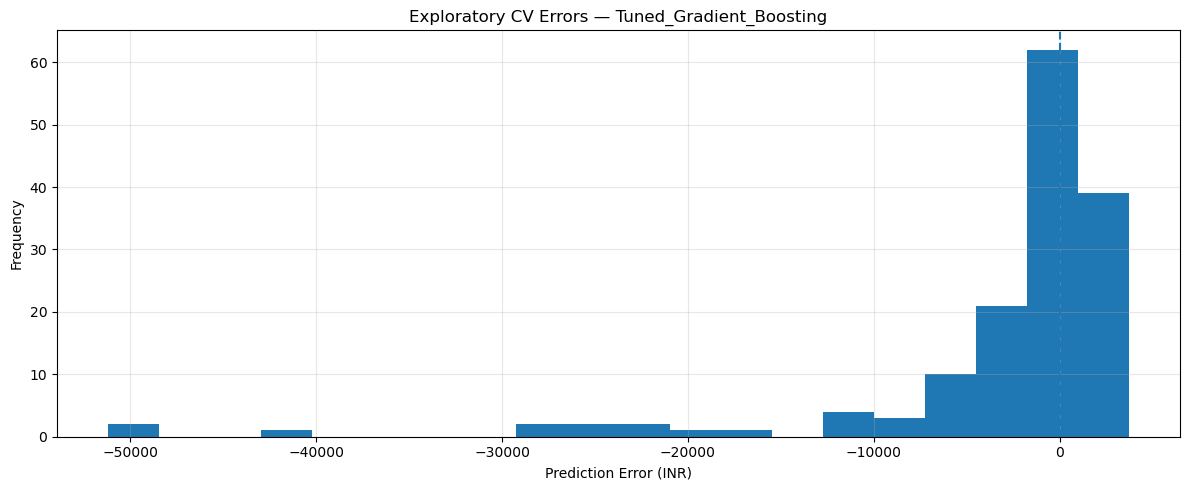


LARGEST ERRORS


,Actual,Predicted,Error,Absolute_Error
80,55597.00,4401.08,-51195.92,51195.92
103,52244.00,3175.85,-49068.15,49068.15
104,46613.90,4302.16,-42311.74,42311.74
99,32431.00,4302.16,-28128.84,28128.84
57,28453.47,461.32,-27992.15,27992.15
78,30001.00,3936.93,-26064.07,26064.07
96,29370.00,3399.37,-25970.63,25970.63
126,26429.67,3352.02,-23077.65,23077.65
44,21637.00,504.97,-21132.03,21132.03
120,23914.00,3259.58,-20654.42,20654.42



EXPLORATORY COMPARISON
Rolling Median 7 CV MAE: 3970.36
Best new candidate CV MAE: 4231.52
Relative MAE improvement (%): -6.58
Rolling Median 7 remains stronger in this comparison.

EXPERIMENT FILES SAVED
weekly_ai_discovery_leaderboard.csv
weekly_ai_discovery_fold_results.csv
weekly_ai_discovery_error_analysis.csv
weekly_ai_discovery_report.joblib

STEP 20F COMPLETED
AI-ASSISTED MODEL DISCOVERY FINISHED


In [55]:

# ============================================================
# STEP 20F: ERROR ANALYSIS AND EXPERIMENT REPORT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. SELECT BEST NEW ML CANDIDATE
# ------------------------------------------------------------

new_model_results = ai_final_leaderboard[
    ~ai_final_leaderboard["Model"].isin([
        "Rolling_Median_7",
        "Rolling_Median_8"
    ])
]

best_new_model_name = (
    new_model_results.iloc[0]["Model"]
)

print("BEST NEW ML CANDIDATE:", best_new_model_name)

# ------------------------------------------------------------
# 2. ERROR ANALYSIS
# ------------------------------------------------------------

if best_new_model_name in comparison_predictions:

    best_prediction_data = comparison_predictions[
        best_new_model_name
    ]

    actual_values = best_prediction_data["Actual"]
    predicted_values = best_prediction_data["Predicted"]

    best_error = predicted_values - actual_values

    error_report = pd.DataFrame({

        "Actual": actual_values,

        "Predicted": predicted_values,

        "Error": best_error,

        "Absolute_Error": np.abs(best_error)
    })

    print("\nNEW MODEL ERROR SUMMARY")

    display(
        error_report.describe().round(2)
    )

    # Error distribution
    plt.figure(figsize=(12, 5))

    plt.hist(
        best_error,
        bins=20
    )

    plt.axvline(
        0,
        linestyle="--"
    )

    plt.title(
        f"Exploratory CV Errors — {best_new_model_name}"
    )

    plt.xlabel("Prediction Error (INR)")
    plt.ylabel("Frequency")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("\nLARGEST ERRORS")

    display(
        error_report.sort_values(
            "Absolute_Error",
            ascending=False
        ).head(10).round(2)
    )

else:
    error_report = pd.DataFrame()
    print("No usable prediction series for the selected candidate.")


# ------------------------------------------------------------
# 3. COMPARE AGAINST ROLLING MEDIAN 7
# ------------------------------------------------------------

baseline_mae = ai_final_leaderboard.loc[
    ai_final_leaderboard["Model"] == "Rolling_Median_7",
    "MAE"
].iloc[0]

new_model_mae = new_model_results.iloc[0]["MAE"]

improvement = (
    (baseline_mae - new_model_mae)
    / baseline_mae
) * 100

print("\nEXPLORATORY COMPARISON")

print("Rolling Median 7 CV MAE:", round(baseline_mae, 2))
print("Best new candidate CV MAE:", round(new_model_mae, 2))
print("Relative MAE improvement (%):", round(improvement, 2))

if new_model_mae < baseline_mae:
    print("New candidate has lower exploratory CV MAE.")
else:
    print("Rolling Median 7 remains stronger in this comparison.")


# ------------------------------------------------------------
# 4. SAVE EXPERIMENT RESULTS
# ------------------------------------------------------------

project_root = Path.cwd()

if not (project_root / "models").exists():
    if project_root.name == "notebooks":
        project_root = project_root.parent

models_directory = project_root / "models"
predictions_directory = project_root / "data" / "predictions"

models_directory.mkdir(parents=True, exist_ok=True)
predictions_directory.mkdir(parents=True, exist_ok=True)

ai_final_leaderboard.to_csv(
    predictions_directory
    / "weekly_ai_discovery_leaderboard.csv",
    index=False
)

ai_fold_results.to_csv(
    predictions_directory
    / "weekly_ai_discovery_fold_results.csv",
    index=False
)

if not error_report.empty:

    error_report.to_csv(
        predictions_directory
        / "weekly_ai_discovery_error_analysis.csv",
        index=False
    )

# Research metadata
ai_discovery_report = {

    "project": "ForeSight",

    "experiment": "AI-assisted weekly model discovery",

    "dataset_observations": len(weekly_spending),

    "features": list(ai_X.columns),

    "cross_validation": "5-fold chronological TimeSeriesSplit",

    "best_new_candidate": best_new_model_name,

    "best_new_candidate_mae": float(new_model_mae),

    "rolling_median_7_cv_mae": float(baseline_mae),

    "relative_improvement_percent": float(improvement),

    "warning": (
        "Exploratory cross-validation only. "
        "Hyperparameter tuning and model exploration used "
        "historical development data. Independent confirmation "
        "on new household data is required before deployment."
    )
}

joblib.dump(
    ai_discovery_report,
    models_directory / "weekly_ai_discovery_report.joblib"
)

print("\nEXPERIMENT FILES SAVED")

print("weekly_ai_discovery_leaderboard.csv")
print("weekly_ai_discovery_fold_results.csv")
print("weekly_ai_discovery_error_analysis.csv")
print("weekly_ai_discovery_report.joblib")

print("\nSTEP 20F COMPLETED")
print("AI-ASSISTED MODEL DISCOVERY FINISHED")


In [56]:

# ============================================================
# STEP 21: PACKAGE AI-ASSISTED DISCOVERY
# ============================================================

import joblib
import numpy as np

from pathlib import Path
from sklearn.base import clone

# ------------------------------------------------------------
# 1. PREPARE PROJECT DIRECTORIES
# ------------------------------------------------------------

project_root = Path.cwd()

if not (project_root / "models").exists():
    if project_root.name == "notebooks":
        project_root = project_root.parent

models_directory = project_root / "models"
models_directory.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. SAVE BEST NEW ML CANDIDATE
# ------------------------------------------------------------

research_model_path = (
    models_directory / "weekly_ai_research_candidate.joblib"
)

research_bundle_path = (
    models_directory / "weekly_ai_research_bundle.joblib"
)

if best_new_model_name in comparison_models:

    research_model = clone(
        comparison_models[best_new_model_name]
    )

    research_model.fit(ai_X, ai_y)

    joblib.dump(
        research_model,
        research_model_path
    )

    research_bundle = {

        "project": "ForeSight",

        "candidate_name": best_new_model_name,

        "feature_names": list(ai_X.columns),

        "forecast_frequency": "Weekly",

        "forecast_horizon": "One week ahead",

        "currency": "INR",

        "research_only": True,

        "production_approved": False,

        "training_observations": len(ai_X),

        "selection_method": (
            "Exploratory chronological cross-validation"
        ),

        "independent_confirmation_required": True
    }

    joblib.dump(
        research_bundle,
        research_bundle_path
    )

    print("Research model saved:", research_model_path)
    print("Research configuration saved:", research_bundle_path)

else:

    print(
        "The best candidate is a baseline method. "
        "No additional fitted ML artifact is required."
    )

# ------------------------------------------------------------
# 3. VERIFY EXISTING PRIMARY FORECASTING MODULE
# ------------------------------------------------------------

primary_module = (
    project_root / "src" / "forecasting"
    / "weekly_forecasting.py"
)

primary_bundle = (
    models_directory / "weekly_forecasting_bundle.joblib"
)

print("\nEXISTING PRIMARY MODEL FILES")

print("Forecasting module exists:", primary_module.exists())
print("Forecasting bundle exists:", primary_bundle.exists())

# ------------------------------------------------------------
# 4. FINAL EXPERIMENT STATUS
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("FORESIGHT — AI MODEL DISCOVERY SUMMARY")
print("=" * 55)

print("Best new candidate:", best_new_model_name)
print("Primary deployment candidate: Rolling Median 7")
print("Alternative candidate: Rolling Median 8")

print("New candidate CV MAE:", round(new_model_mae, 2))
print("Rolling Median 7 CV MAE:", round(baseline_mae, 2))

print("\nResearch candidate approved for production: NO")
print("Independent new-data evaluation required: YES")

print("\nSTEP 21 COMPLETED")


Research model saved: c:\Users\singh\Desktop\foresight\models\weekly_ai_research_candidate.joblib
Research configuration saved: c:\Users\singh\Desktop\foresight\models\weekly_ai_research_bundle.joblib

EXISTING PRIMARY MODEL FILES
Forecasting module exists: True
Forecasting bundle exists: True

FORESIGHT — AI MODEL DISCOVERY SUMMARY
Best new candidate: Tuned_Gradient_Boosting
Primary deployment candidate: Rolling Median 7
Alternative candidate: Rolling Median 8
New candidate CV MAE: 4231.52
Rolling Median 7 CV MAE: 3970.36

Research candidate approved for production: NO
Independent new-data evaluation required: YES

STEP 21 COMPLETED


In [57]:

# ============================================================
# FORESIGHT — NOTEBOOK 06
# VALIDATION STEP 1: DATA INTEGRITY AND CHRONOLOGICAL SPLIT
# ============================================================

import numpy as np
import pandas as pd

weekly_validation_checks = []

def weekly_check(name, condition, details=""):
    weekly_validation_checks.append({
        "Check": name,
        "Status": "PASS" if condition else "FAIL",
        "Details": details
    })

# ------------------------------------------------------------
# 1. DATA STRUCTURE
# ------------------------------------------------------------

weekly_check(
    "Weekly spending is a pandas Series",
    isinstance(weekly_spending, pd.Series)
)

weekly_check(
    "Weekly index is PeriodIndex",
    isinstance(weekly_spending.index, pd.PeriodIndex)
)

weekly_check(
    "Weekly frequency is Monday-Sunday",
    weekly_spending.index.freqstr == "W-SUN",
    str(weekly_spending.index.freqstr)
)

weekly_check(
    "206 calendar weeks available",
    len(weekly_spending) == 206,
    f"Found: {len(weekly_spending)}"
)

weekly_check(
    "Weekly index is sorted",
    weekly_spending.index.is_monotonic_increasing
)

weekly_check(
    "Weekly index has no duplicates",
    weekly_spending.index.is_unique
)

weekly_check(
    "Weekly periods are continuous",
    weekly_spending.index.equals(all_weeks)
)

# ------------------------------------------------------------
# 2. SPENDING VALUES
# ------------------------------------------------------------

weekly_values = weekly_spending.to_numpy(dtype=float)

weekly_check(
    "No missing weekly values",
    not weekly_spending.isna().any()
)

weekly_check(
    "All weekly values are finite",
    np.isfinite(weekly_values).all()
)

weekly_check(
    "No negative weekly spending",
    (weekly_spending >= 0).all()
)

weekly_check(
    "13 zero-spending weeks preserved",
    int((weekly_spending == 0).sum()) == 13,
    f"Found: {(weekly_spending == 0).sum()}"
)

weekly_check(
    "193 active spending weeks",
    int((weekly_spending > 0).sum()) == 193,
    f"Found: {(weekly_spending > 0).sum()}"
)

weekly_check(
    "Total spending matches source aggregation",
    np.isclose(
        weekly_spending.sum(),
        936993.63,
        atol=0.01
    ),
    f"Total: ₹{weekly_spending.sum():,.2f}"
)

# ------------------------------------------------------------
# 3. INDEPENDENT AGGREGATION CHECK
# ------------------------------------------------------------

independent_weekly = (
    household_df
    .groupby("Week")["Amount"]
    .sum()
    .reindex(all_weeks, fill_value=0)
)

aggregation_matches = np.allclose(
    independent_weekly.to_numpy(dtype=float),
    weekly_spending.to_numpy(dtype=float),
    atol=0.000001
)

weekly_check(
    "Independent weekly aggregation matches",
    aggregation_matches
)

weekly_check(
    "Household transaction count matches",
    len(household_df) == 1996,
    f"Found: {len(household_df)}"
)

# ------------------------------------------------------------
# 4. CHRONOLOGICAL SPLIT
# ------------------------------------------------------------

weekly_check(
    "Training contains 104 weeks",
    len(train_data) == 104
)

weekly_check(
    "Validation contains 76 weeks",
    len(validation_data) == 76
)

weekly_check(
    "Final test contains 26 weeks",
    len(final_test_data) == 26
)

weekly_check(
    "Training precedes validation",
    train_data.index.max() < validation_data.index.min()
)

weekly_check(
    "Validation precedes final test",
    validation_data.index.max() < final_test_data.index.min()
)

weekly_check(
    "All split lengths sum to 206",
    len(train_data) + len(validation_data)
    + len(final_test_data) == 206
)

# ------------------------------------------------------------
# 5. FORECAST ORIGIN ALIGNMENT
# ------------------------------------------------------------

weekly_check(
    "76 validation origins",
    len(validation_origins) == 76
)

weekly_check(
    "26 test origins",
    len(test_origins) == 26
)

weekly_check(
    "Validation origins match validation dates",
    weekly_spending.index[validation_origins].equals(
        validation_data.index
    )
)

weekly_check(
    "Test origins match final test dates",
    weekly_spending.index[test_origins].equals(
        final_test_data.index
    )
)

# ------------------------------------------------------------
# 6. FINAL REPORT
# ------------------------------------------------------------

weekly_validation_report = pd.DataFrame(
    weekly_validation_checks
)

display(weekly_validation_report)

passed = (
    weekly_validation_report["Status"] == "PASS"
).sum()

failed = (
    weekly_validation_report["Status"] == "FAIL"
).sum()

print("\n" + "=" * 60)
print("WEEKLY FORECASTING — VALIDATION STEP 1")
print("=" * 60)

print("Checks passed:", passed)
print("Checks failed:", failed)
print("Total checks:", len(weekly_validation_report))

if failed == 0:
    print("\nSTEP 1 RESULT: ALL CHECKS PASSED")
else:
    print("\nSTEP 1 RESULT: INVESTIGATION REQUIRED")

    display(
        weekly_validation_report[
            weekly_validation_report["Status"] == "FAIL"
        ]
    )


,Check,Status,Details
0,Weekly spending is a pandas Series,PASS,
1,Weekly index is PeriodIndex,PASS,
2,Weekly frequency is Monday-Sunday,PASS,W-SUN
3,206 calendar weeks available,PASS,Found: 206
4,Weekly index is sorted,PASS,
5,Weekly index has no duplicates,PASS,
6,Weekly periods are continuous,PASS,
7,No missing weekly values,PASS,
8,All weekly values are finite,PASS,
9,No negative weekly spending,PASS,



WEEKLY FORECASTING — VALIDATION STEP 1
Checks passed: 25
Checks failed: 0
Total checks: 25

STEP 1 RESULT: ALL CHECKS PASSED
